In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import differential_evolution, minimize
from scipy.spatial import ConvexHull, QhullError

plt.style.use(style="seaborn-v0_8-whitegrid")
np.set_printoptions(precision=4, suppress=True)

In [2]:
from __future__ import annotations
from numpy.typing import NDArray

In [3]:
def jones_ar_coefficients(p: int, rng: np.random.Generator | int | None = None, *, return_pacf: bool = False):
    if not isinstance(p, (int, np.integer)) or p < 1:
        raise ValueError(f"p must be a positive integer, got {p}")
    generator = np.random.default_rng(rng)
    k = np.arange(1, p + 1)
    a = (k + 1) // 2
    b = k // 2 + 1
    beta_draws = generator.beta(a, b)
    pacf = 2.0 * beta_draws - 1.0
    phi = np.array([pacf[0]], dtype=float)
    for order in range(2, p + 1):
        reflection_coeff = pacf[order - 1]
        previous_phi = phi
        phi = np.empty(order, dtype=float)
        phi[:-1] = (previous_phi - reflection_coeff * previous_phi[::-1])
        phi[-1] = reflection_coeff
    if return_pacf:
        return phi, pacf
    return phi

def simulate_uniform_ar(phi, sample_size: int, burnin: int=500, half_width=1.0, rng=None):
    phi = np.asarray(phi, dtype=float)
    if phi.ndim != 1 or len(phi) == 0:
        raise ValueError("phi must be a nonempty one-dimensional coefficient vector")
    if not isinstance(sample_size, (int, np.integer)) or sample_size < 1:
        raise ValueError("sample_size must be a positive integer")
    if not isinstance(burnin, (int, np.integer)) or burnin < 0:
        raise ValueError("burnin must be a non-negative integer")
    if half_width <= 0:
        raise ValueError("half_width must be a positive number")
    generator = np.random.default_rng(rng)
    order = len(phi)
    total_length = burnin + order + sample_size
    innovations = generator.uniform(-half_width, half_width, size=total_length)
    series = np.zeros(total_length, dtype=float)
    for t in range(order, total_length):
        recent_values = series[t - np.arange(1, order + 1)]
        series[t] = phi @ recent_values + innovations[t]
    return series[burnin + order:]

phi: [-1.0876 -0.9523]


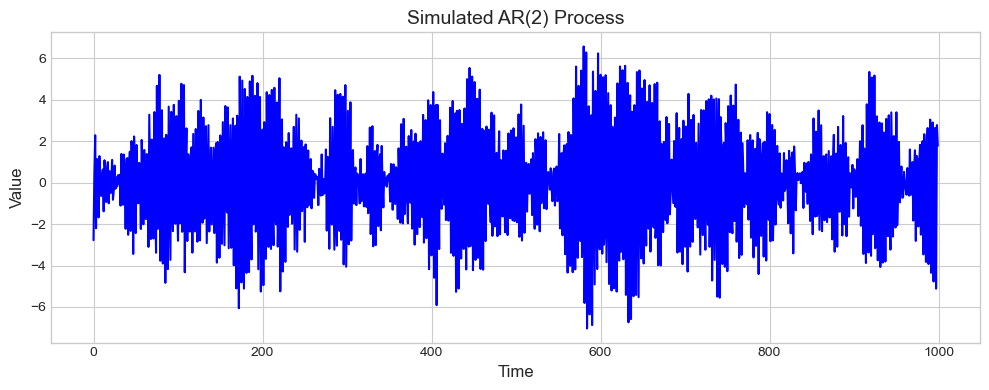

In [4]:
p = 2
coefficient_seed = 42
process_seed = 20260806
sample_size = 1000
burnin = 500
innovations_half_width = 1.0

phi = jones_ar_coefficients(p, rng=coefficient_seed, return_pacf=False)
ar_series = simulate_uniform_ar(phi, sample_size, burnin, innovations_half_width, rng=process_seed)

print("phi:", phi)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(ar_series, color="blue", linewidth=1.5)
ax.set_title(f"Simulated AR({p}) Process", fontsize=14)
ax.set_xlabel("Time", fontsize=12)
ax.set_ylabel("Value", fontsize=12)
plt.tight_layout()
plt.show()

In [5]:
def ar_impulse_response(phi, maximum_lag):
    phi = np.asarray(phi, dtype=float)
    order = len(phi)
    psi = np.zeros(maximum_lag + 1)
    psi[0] = 1.0
    for lag in range(1, maximum_lag + 1):
        psi[lag] = sum(phi[j - 1] * psi[lag - j] for j in range(1, min(order, lag) + 1))
    return psi

In [6]:
def sliding_window_point_cloud(series, embedding_dimension: int):
    series = np.asarray(series, dtype=float)
    k = int(embedding_dimension)
    if series.ndim != 1:
        raise ValueError("series must be a one-dimensional array")
    if k < 1 or len(series) < k:
        raise ValueError("embedding_dimension must be a positive integer less than or equal to the length of the series")
    return np.column_stack([series[k - 1 - lag:len(series) - lag] for lag in range(k)])

In [7]:
def projected_subgradient_empirical_width(
    points,
    iterations=2_000,
    initial_step=0.2,
    patience=200,
    improvement_tolerance=1e-10,
    rng=None,
    initial_direction=None,
    step_schedule="inverse_sqrt",
    geometric_decay=0.99,
):
    """Minimize empirical directional width over the unit sphere.

    step_schedule="inverse_sqrt" uses eta_t = eta_0 / sqrt(t + 1).
    step_schedule="geometric" uses eta_t = eta_0 * beta**t, as in
    the local convergence result of Li et al. (Theorem 4).
    """
    points = np.asarray(points, dtype=float)
    if points.ndim != 2 or len(points) < 2:
        raise ValueError("points must have shape (n, k) with n >= 2.")
    if iterations < 1:
        raise ValueError("iterations must be positive.")
    if initial_step <= 0:
        raise ValueError("initial_step must be positive.")
    valid_step_schedules = {"inverse_sqrt", "geometric"}
    if step_schedule not in valid_step_schedules:
        raise ValueError(
            f"step_schedule must be one of {sorted(valid_step_schedules)}."
        )
    if not 0.0 < geometric_decay < 1.0:
        raise ValueError("geometric_decay must lie strictly between zero and one.")
    if not isinstance(patience, (int, np.integer)) or patience < 1:
        raise ValueError("patience must be a positive integer.")
    if improvement_tolerance < 0:
        raise ValueError("improvement_tolerance must be nonnegative.")

    generator = np.random.default_rng(rng)
    dimension = points.shape[1]

    if initial_direction is None:
        direction = generator.normal(size=dimension)
    else:
        direction = np.asarray(initial_direction, dtype=float)
        if direction.shape != (dimension,):
            raise ValueError(f"initial_direction must have shape ({dimension},).")

    direction_norm = np.linalg.norm(direction)
    if direction_norm <= np.finfo(float).eps:
        raise ValueError("initial_direction must be nonzero.")
    direction = direction / direction_norm

    width_history = np.empty(iterations)
    best_width_history = np.empty(iterations)
    step_history = np.empty(iterations)
    best_width = np.inf
    best_direction = direction.copy()
    iterations_without_improvement = 0

    for iteration in range(iterations):
        projections = points @ direction
        maximum_index = int(np.argmax(projections))
        minimum_index = int(np.argmin(projections))
        width = projections[maximum_index] - projections[minimum_index]

        if width < best_width - improvement_tolerance:
            best_width = float(width)
            best_direction = direction.copy()
            iterations_without_improvement = 0
        else:
            iterations_without_improvement += 1

        width_history[iteration] = width
        best_width_history[iteration] = best_width
        if step_schedule == "inverse_sqrt":
            step = initial_step / np.sqrt(iteration + 1.0)
        else:
            step = initial_step * geometric_decay**iteration
        step_history[iteration] = step

        if iterations_without_improvement >= patience:
            width_history = width_history[:iteration + 1]
            best_width_history = best_width_history[:iteration + 1]
            step_history = step_history[:iteration + 1]
            break

        # x_max-x_min is a subgradient of max_i <x_i,u>-min_i <x_i,u>.
        subgradient = points[maximum_index] - points[minimum_index]
        # Project the Euclidean subgradient onto the tangent space of the sphere.
        riemannian_subgradient = (
            subgradient - (direction @ subgradient) * direction
        )
        if np.linalg.norm(riemannian_subgradient) <= np.finfo(float).eps:
            width_history = width_history[:iteration + 1]
            best_width_history = best_width_history[:iteration + 1]
            step_history = step_history[:iteration + 1]
            break

        # Retract the Riemannian subgradient update back onto the unit sphere.
        candidate = direction - step * riemannian_subgradient
        candidate_norm = np.linalg.norm(candidate)
        if candidate_norm <= np.finfo(float).eps:
            candidate = generator.normal(size=dimension)
            candidate_norm = np.linalg.norm(candidate)
        direction = candidate / candidate_norm

    return {
        "minimum_width": best_width,
        "direction": best_direction,
        "width_history": width_history,
        "best_width_history": best_width_history,
        "step_history": step_history,
        "step_schedule": step_schedule,
        "geometric_decay": geometric_decay,
    }


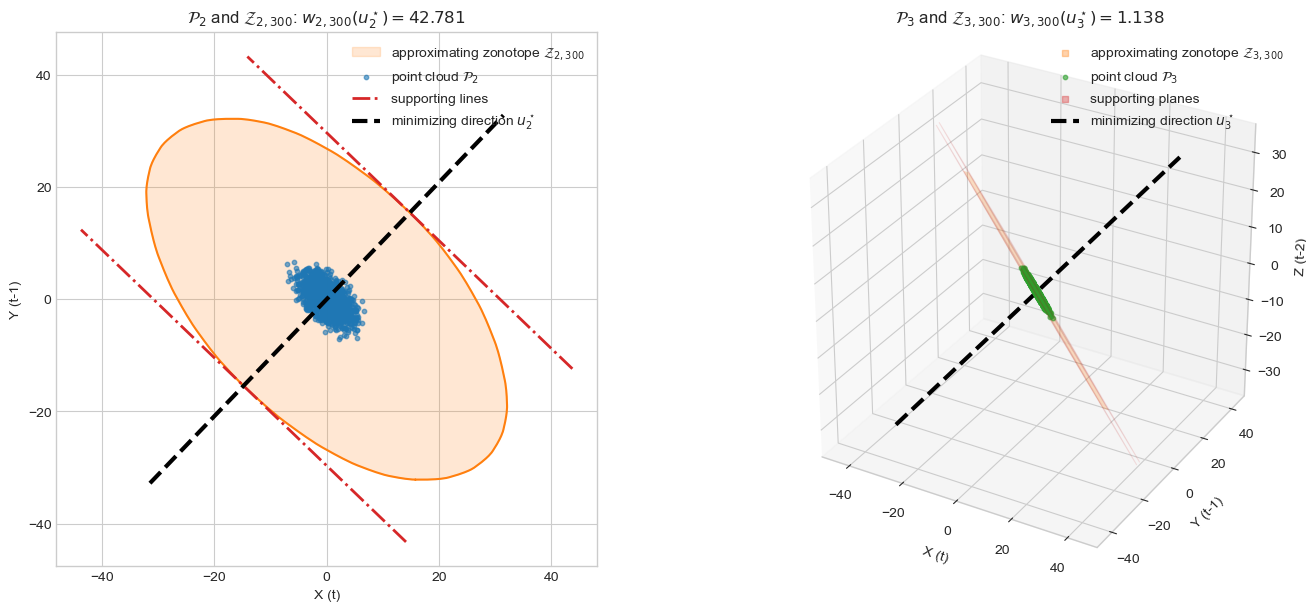

In [8]:
cloud_2d = sliding_window_point_cloud(ar_series, embedding_dimension=2)
cloud_3d = sliding_window_point_cloud(ar_series, embedding_dimension=3)

subgradient_2d = projected_subgradient_empirical_width(
    cloud_2d,
    iterations=2_000,
    initial_step=0.2,
    rng=20260806,
)
subgradient_3d = projected_subgradient_empirical_width(
    cloud_3d,
    iterations=2_000,
    initial_step=0.2,
    rng=20260807,
)

theoretical_history = 10_000
psi_for_cloud_plot = ar_impulse_response(phi, theoretical_history)
psi_shifted_once = np.concatenate(([0.0], psi_for_cloud_plot[:-1]))

def theoretical_width_2d_from_angle(angle):
    direction = np.array([np.cos(angle), np.sin(angle)])
    generator_projections = (
        direction[0] * psi_for_cloud_plot
        + direction[1] * psi_shifted_once
    )
    return float(
        2.0 * innovations_half_width * np.sum(np.abs(generator_projections))
    )

angle_grid = np.linspace(0.0, np.pi, 721, endpoint=False)
width_grid = np.array([theoretical_width_2d_from_angle(angle) for angle in angle_grid])
best_grid_angle = angle_grid[np.argmin(width_grid)]
theoretical_fit_2d = minimize(
    lambda angle: theoretical_width_2d_from_angle(float(angle[0])),
    x0=np.array([best_grid_angle]),
    method="Nelder-Mead",
    options={"xatol": 1e-12, "fatol": 1e-12},
)
theoretical_angle_2d = float(theoretical_fit_2d.x[0] % np.pi)
theoretical_direction_2d = np.array([
    np.cos(theoretical_angle_2d),
    np.sin(theoretical_angle_2d),
])
theoretical_minimum_width_2d = theoretical_width_2d_from_angle(
    theoretical_angle_2d
)

theoretical_direction_3d = np.concatenate(([1.0], -phi))
theoretical_direction_3d /= np.linalg.norm(theoretical_direction_3d)
generator_projections_3d = np.convolve(
    psi_for_cloud_plot, theoretical_direction_3d
)[: theoretical_history + 1]
theoretical_minimum_width_3d = float(
    2.0 * innovations_half_width * np.sum(np.abs(generator_projections_3d))
)

# Use a finite impulse-response history to obtain drawable approximations
# Z_(k,H) of the infinite theoretical support zonotopes.
zonotope_history = 300

def ar_window_zonotope_generators(phi, embedding_dimension, history, half_width=1.0):
    psi = ar_impulse_response(phi, history)
    generators = np.zeros((embedding_dimension, history + 1))
    for innovation_lag in range(history + 1):
        for coordinate in range(embedding_dimension):
            response_lag = innovation_lag - coordinate
            if response_lag >= 0:
                generators[coordinate, innovation_lag] = (
                    half_width * psi[response_lag]
                )
    return generators[:, np.linalg.norm(generators, axis=0) > 1e-13]


def zonotope_polygon_2d(generators):
    # A planar zonotope has two boundary edges parallel to every generator.
    lengths = np.linalg.norm(generators, axis=0)
    angles = np.mod(np.arctan2(generators[1], generators[0]), np.pi)
    oriented = lengths[:, None] * np.column_stack((np.cos(angles), np.sin(angles)))
    oriented = oriented[np.argsort(angles)]

    current = -np.sum(oriented, axis=0)
    vertices = [current.copy()]
    for generator in oriented:
        current = current + 2.0 * generator
        vertices.append(current.copy())
    for generator in oriented:
        current = current - 2.0 * generator
        vertices.append(current.copy())
    return np.asarray(vertices)


def fibonacci_sphere_directions(number_of_directions):
    index = np.arange(number_of_directions)
    z = 1.0 - 2.0 * (index + 0.5) / number_of_directions
    radius = np.sqrt(1.0 - z**2)
    angle = np.pi * (3.0 - np.sqrt(5.0)) * index
    return np.column_stack((radius * np.cos(angle), radius * np.sin(angle), z))


def zonotope_support_points(generators, directions):
    # The support point in direction u is sum_j sign(<g_j,u>) g_j.
    signs = np.sign(generators.T @ directions.T)
    signs[signs == 0.0] = 1.0
    return (generators @ signs).T


generators_2d = ar_window_zonotope_generators(
    phi, 2, zonotope_history, innovations_half_width
)
generators_3d = ar_window_zonotope_generators(
    phi, 3, zonotope_history, innovations_half_width
)
zonotope_vertices_2d = zonotope_polygon_2d(generators_2d)

sphere_directions = fibonacci_sphere_directions(1_200)
sphere_directions = np.vstack((
    sphere_directions,
    theoretical_direction_3d,
    -theoretical_direction_3d,
))
zonotope_surface_points_3d = zonotope_support_points(
    generators_3d, sphere_directions
)
zonotope_hull_3d = ConvexHull(zonotope_surface_points_3d)

# The two support levels are +/-h, so their separation is the finite-history width 2h.
support_half_width_2d = np.sum(
    np.abs(generators_2d.T @ theoretical_direction_2d)
)
support_half_width_3d = np.sum(
    np.abs(generators_3d.T @ theoretical_direction_3d)
)
approximating_width_2d = 2.0 * support_half_width_2d
approximating_width_3d = 2.0 * support_half_width_3d

perpendicular_2d = np.array([
    -theoretical_direction_2d[1], theoretical_direction_2d[0]
])
perpendicular_coordinates_2d = zonotope_vertices_2d @ perpendicular_2d
support_line_coordinate = np.linspace(
    perpendicular_coordinates_2d.min(),
    perpendicular_coordinates_2d.max(),
    2,
)

reference_axis = np.array([0.0, 0.0, 1.0])
if abs(theoretical_direction_3d @ reference_axis) > 0.9:
    reference_axis = np.array([0.0, 1.0, 0.0])
plane_basis_1 = np.cross(theoretical_direction_3d, reference_axis)
plane_basis_1 /= np.linalg.norm(plane_basis_1)
plane_basis_2 = np.cross(theoretical_direction_3d, plane_basis_1)
plane_coordinate_1 = zonotope_surface_points_3d @ plane_basis_1
plane_coordinate_2 = zonotope_surface_points_3d @ plane_basis_2
plane_grid_1, plane_grid_2 = np.meshgrid(
    np.linspace(plane_coordinate_1.min(), plane_coordinate_1.max(), 2),
    np.linspace(plane_coordinate_2.min(), plane_coordinate_2.max(), 2),
)

direction_half_length_2d = 0.5 * np.linalg.norm(np.ptp(zonotope_vertices_2d, axis=0))
direction_endpoints_2d = np.outer(
    [-direction_half_length_2d, direction_half_length_2d],
    theoretical_direction_2d,
)
direction_half_length_3d = 0.5 * np.linalg.norm(
    np.ptp(zonotope_surface_points_3d, axis=0)
)
direction_endpoints_3d = np.outer(
    [-direction_half_length_3d, direction_half_length_3d],
    theoretical_direction_3d,
)

fig = plt.figure(figsize=(14, 6), constrained_layout=True)
ax_2d = fig.add_subplot(1, 2, 1)
ax_3d = fig.add_subplot(1, 2, 2, projection='3d')
ax_2d.fill(
    zonotope_vertices_2d[:, 0],
    zonotope_vertices_2d[:, 1],
    color="tab:orange",
    alpha=0.18,
    label=fr"approximating zonotope $\mathcal{{Z}}_{{2,{zonotope_history}}}$",
)
ax_2d.plot(
    zonotope_vertices_2d[:, 0],
    zonotope_vertices_2d[:, 1],
    color="tab:orange",
    linewidth=1.5,
)
ax_2d.scatter(
    cloud_2d[:, 0], cloud_2d[:, 1],
    color="tab:blue", s=10, alpha=0.6, label=r"point cloud $\mathcal{P}_2$"
)
for support_sign in (-1.0, 1.0):
    support_line = (
        support_sign * support_half_width_2d * theoretical_direction_2d
        + np.outer(support_line_coordinate, perpendicular_2d)
    )
    ax_2d.plot(
        support_line[:, 0], support_line[:, 1],
        color="tab:red", linestyle="-.", linewidth=2.0,
        label="supporting lines" if support_sign < 0 else None,
    )
ax_2d.plot(
    direction_endpoints_2d[:, 0],
    direction_endpoints_2d[:, 1],
    color="black",
    linestyle="--",
    linewidth=3,
    label=r"minimizing direction $u_2^\star$",
)
ax_2d.set_title(
    rf"$\mathcal{{P}}_2$ and $\mathcal{{Z}}_{{2,{zonotope_history}}}$: "
    rf"$w_{{2,{zonotope_history}}}(u_2^\star)={approximating_width_2d:.3f}$",
    fontsize=12,
)
ax_2d.set_xlabel("X (t)", fontsize=10)
ax_2d.set_ylabel("Y (t-1)", fontsize=10)
ax_2d.set_aspect("equal", adjustable="box")
ax_2d.legend(loc="upper right")
ax_3d.plot_trisurf(
    zonotope_surface_points_3d[:, 0],
    zonotope_surface_points_3d[:, 1],
    zonotope_surface_points_3d[:, 2],
    triangles=zonotope_hull_3d.simplices,
    color="tab:orange", alpha=0.12, linewidth=0.15, shade=False,
)
ax_3d.scatter([], [], [], color="tab:orange", marker="s", alpha=0.35,
              label=fr"approximating zonotope $\mathcal{{Z}}_{{3,{zonotope_history}}}$")
ax_3d.scatter(
    cloud_3d[:, 0], cloud_3d[:, 1], cloud_3d[:, 2],
    color="tab:green", s=10, alpha=0.6, label=r"point cloud $\mathcal{P}_3$"
)
for support_sign in (-1.0, 1.0):
    support_plane = (
        support_sign * support_half_width_3d * theoretical_direction_3d
        + plane_grid_1[..., None] * plane_basis_1
        + plane_grid_2[..., None] * plane_basis_2
    )
    ax_3d.plot_surface(
        support_plane[:, :, 0],
        support_plane[:, :, 1],
        support_plane[:, :, 2],
        color="tab:red", alpha=0.12, edgecolor="tab:red", linewidth=0.8,
    )
ax_3d.scatter([], [], [], color="tab:red", marker="s", alpha=0.35,
              label="supporting planes")
ax_3d.plot(
    direction_endpoints_3d[:, 0],
    direction_endpoints_3d[:, 1],
    direction_endpoints_3d[:, 2],
    color="black",
    linestyle="--",
    linewidth=3,
    label=r"minimizing direction $u_3^\star$",
)
ax_3d.set_title(
    rf"$\mathcal{{P}}_3$ and $\mathcal{{Z}}_{{3,{zonotope_history}}}$: "
    rf"$w_{{3,{zonotope_history}}}(u_3^\star)={approximating_width_3d:.3f}$",
    fontsize=12,
)
ax_3d.set_xlabel("X (t)", fontsize=10)
ax_3d.set_ylabel("Y (t-1)", fontsize=10)
ax_3d.set_zlabel("Z (t-2)", fontsize=10)
ax_3d.set_box_aspect(np.ptp(zonotope_surface_points_3d, axis=0))
ax_3d.legend(loc="upper right")
plt.show()

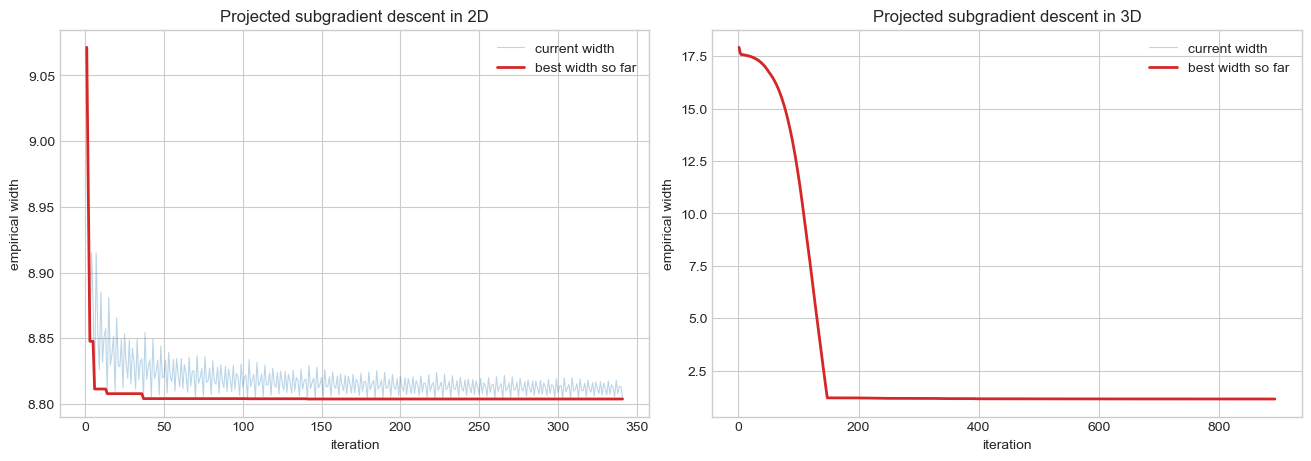

2D minimum width: 8.803727824421523
2D minimizing direction: [0.7343 0.6788]
3D minimum width: 1.1542180589044906
3D minimizing direction: [0.5707 0.6176 0.5412]


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)

for axis, result, dimension in zip(
    axes,
    (subgradient_2d, subgradient_3d),
    (2, 3),
):
    iteration_numbers = np.arange(1, len(result["width_history"]) + 1)
    axis.plot(
        iteration_numbers,
        result["width_history"],
        color="tab:blue",
        alpha=0.3,
        linewidth=0.8,
        label="current width",
    )
    axis.plot(
        iteration_numbers,
        result["best_width_history"],
        color="tab:red",
        linewidth=2.0,
        label="best width so far",
    )
    axis.set(
        title=f"Projected subgradient descent in {dimension}D",
        xlabel="iteration",
        ylabel="empirical width",
    )
    axis.legend()

plt.show()

print("2D minimum width:", subgradient_2d["minimum_width"])
print("2D minimizing direction:", subgradient_2d["direction"])
print("3D minimum width:", subgradient_3d["minimum_width"])
print("3D minimizing direction:", subgradient_3d["direction"])


## Step-size schedule comparison

The following paired experiment compares the two schedules on the same simulated AR(2) series and the same initial directions. It uses five starts for each embedding dimension, 1,000 iterations, $\eta_0=0.2$, and $\beta=0.99$. Thus the only difference within each pair is

$$\eta_t=\frac{\eta_0}{\sqrt{t+1}} \qquad\text{or}\qquad \eta_t=\eta_0\beta^t.$$


In [ ]:
from time import perf_counter
from IPython.display import display

schedule_comparison_dimensions = [2, 3, 5, 10, 25, 100]
schedule_comparison_starts = 5
schedule_comparison_iterations = 1_000
schedule_comparison_initial_step = 0.2
schedule_comparison_geometric_decay = 0.99
schedule_comparison_rng = np.random.default_rng(20260813)
schedule_comparison_rows = []

for dimension in schedule_comparison_dimensions:
    cloud = sliding_window_point_cloud(ar_series, dimension)
    initial_directions = schedule_comparison_rng.normal(
        size=(schedule_comparison_starts, dimension)
    )
    initial_directions /= np.linalg.norm(
        initial_directions, axis=1, keepdims=True
    )

    for start_index, initial_direction in enumerate(initial_directions):
        for step_schedule in ("inverse_sqrt", "geometric"):
            start_time = perf_counter()
            fit = projected_subgradient_empirical_width(
                cloud,
                iterations=schedule_comparison_iterations,
                initial_step=schedule_comparison_initial_step,
                step_schedule=step_schedule,
                geometric_decay=schedule_comparison_geometric_decay,
                patience=schedule_comparison_iterations,
                improvement_tolerance=0.0,
                initial_direction=initial_direction,
                rng=1_000 + dimension + start_index,
            )
            schedule_comparison_rows.append({
                "k": dimension,
                "start": start_index,
                "step_schedule": step_schedule,
                "minimum_width": fit["minimum_width"],
                "seconds": perf_counter() - start_time,
            })

schedule_comparison = pd.DataFrame(schedule_comparison_rows)
paired_widths = schedule_comparison.pivot(
    index=["k", "start"],
    columns="step_schedule",
    values="minimum_width",
)
median_widths = paired_widths.groupby(level="k").median()
schedule_comparison_summary = median_widths.copy()
schedule_comparison_summary["geometric_wins"] = (
    paired_widths["geometric"] < paired_widths["inverse_sqrt"]
).groupby(level="k").sum()
schedule_comparison_summary["relative_improvement_percent"] = (
    100.0
    * (schedule_comparison_summary["inverse_sqrt"]
       - schedule_comparison_summary["geometric"])
    / schedule_comparison_summary["inverse_sqrt"]
)

display(schedule_comparison_summary.round(6))
print(
    "Overall paired wins for the geometric schedule:",
    int((paired_widths["geometric"] < paired_widths["inverse_sqrt"]).sum()),
    "out of",
    len(paired_widths),
)


With seed 20260813, the geometric schedule won all 30 paired trials. The observed median minimum widths were:

| $k$ | Geometric | Inverse square root | Geometric wins |
|---:|---:|---:|---:|
| 2 | 8.803711 | 8.803923 | 5/5 |
| 3 | 1.136173 | 1.157649 | 5/5 |
| 5 | 1.113758 | 1.328418 | 5/5 |
| 10 | 1.153020 | 1.509784 | 5/5 |
| 25 | 1.111650 | 1.809104 | 5/5 |
| 100 | 1.250909 | 2.770756 | 5/5 |

For this fixed iteration budget and tuning, the geometric schedule is clearly better. Its faster decay allows fine local adjustments near a kink, whereas the inverse-square-root step is still approximately $0.0063$ at iteration 1,000 and continues to jump across the nonsmooth minimum. This is an empirical comparison, not a universal guarantee: Theorem 4 is local and its admissible values of $\eta_0$ and $\beta$ depend on the sharpness and initialization constants.


In [10]:
def first_plateau_selector(
    k_values,
    minimized_widths,
    relative_tolerance=0.10,
):
    """Return the first scale within a relative tolerance of the observed minimum."""
    k_values = np.asarray(k_values)
    minimized_widths = np.asarray(minimized_widths, dtype=float)

    if k_values.ndim != 1 or minimized_widths.ndim != 1:
        raise ValueError("k_values and minimized_widths must be one-dimensional.")
    if len(k_values) != len(minimized_widths):
        raise ValueError("k_values and minimized_widths must have equal lengths.")
    if len(k_values) == 0:
        raise ValueError("At least one scale is required.")
    if not np.all(np.isfinite(minimized_widths)):
        raise ValueError("All minimized widths must be finite.")
    if relative_tolerance < 0:
        raise ValueError("relative_tolerance must be nonnegative.")

    minimum_width = np.min(minimized_widths)
    plateau_threshold = minimum_width * (1.0 + relative_tolerance)
    first_plateau_index = np.flatnonzero(
        minimized_widths <= plateau_threshold
    )[0]

    return {
        "selected_k": int(k_values[first_plateau_index]),
        "minimum_width": float(minimum_width),
        "plateau_threshold": float(plateau_threshold),
        "relative_tolerance": float(relative_tolerance),
    }


plateau_relative_tolerance = 0.10


In [11]:
def theoretical_ar_width_in_direction(
    phi,
    direction,
    half_width=1.0,
    history=10_000,
):
    """Evaluate the theoretical AR support width in a supplied direction."""
    direction = np.asarray(direction, dtype=float)
    direction_norm = np.linalg.norm(direction)

    if direction.ndim != 1 or len(direction) == 0:
        raise ValueError("direction must be a nonempty one-dimensional array.")
    if direction_norm == 0:
        raise ValueError("direction must be nonzero.")
    if half_width <= 0 or history < 0:
        raise ValueError("Require half_width > 0 and history >= 0.")

    unit_direction = direction / direction_norm
    psi = ar_impulse_response(phi, maximum_lag=history)

    # The convolution gives <g_j, u> for innovation lags j=0,...,history.
    generator_projections = np.convolve(psi, unit_direction)[: history + 1]

    # The support width is twice the sum of the absolute generator projections.
    return float(2.0 * half_width * np.sum(np.abs(generator_projections)))


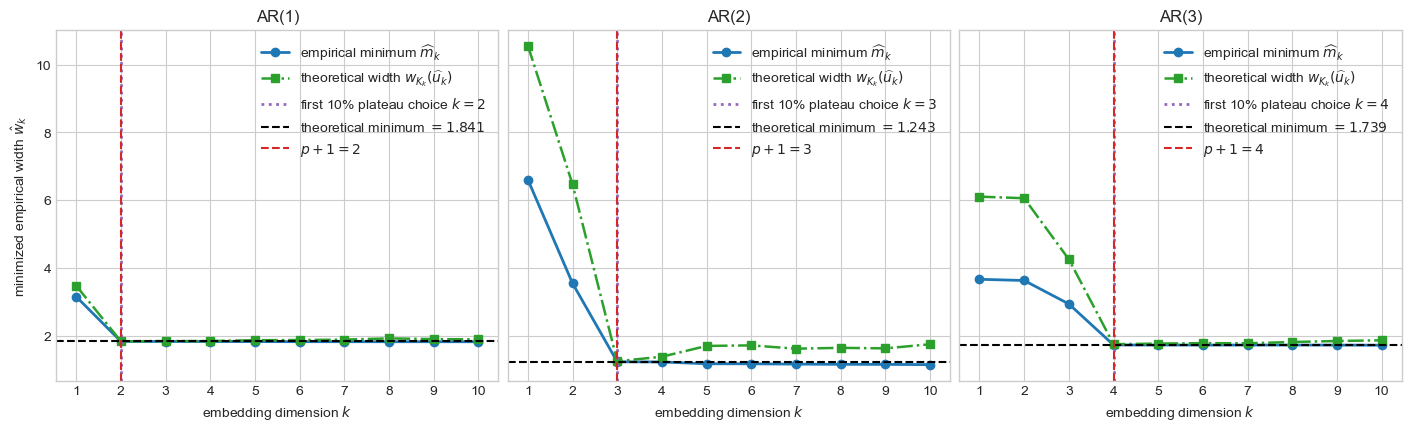

In [12]:
experiment_orders = (1, 2, 3)
experiment_k_max = 10
experiment_sample_size = 2_000
experiment_burnin = 1_000
experiment_half_width = 1.0
experiment_iterations = 2_000
experiment_initial_step = 0.2
experiment_restarts = 8
experiment_seed = 20260808

experiment_rows = []

for order in experiment_orders:
    phi_order = jones_ar_coefficients(
        p=order,
        rng=experiment_seed + order,
    )
    series_order = simulate_uniform_ar(
        phi_order,
        sample_size=experiment_sample_size,
        burnin=experiment_burnin,
        half_width=experiment_half_width,
        rng=experiment_seed + 100 + order,
    )

    for k in range(1, experiment_k_max + 1):
        cloud_k = sliding_window_point_cloud(series_order, embedding_dimension=k)
        restart_fits = [
            projected_subgradient_empirical_width(
                cloud_k,
                iterations=experiment_iterations,
                initial_step=experiment_initial_step,
                rng=experiment_seed + 10_000 * order + 100 * k + restart,
            )
            for restart in range(experiment_restarts)
        ]
        width_fit = min(restart_fits, key=lambda fit: fit["minimum_width"])
        theoretical_direction_width = theoretical_ar_width_in_direction(
            phi_order,
            width_fit["direction"],
            half_width=experiment_half_width,
        )
        experiment_rows.append({
            "p": order,
            "k": k,
            "minimum_width": width_fit["minimum_width"],
            "minimizing_direction": width_fit["direction"].copy(),
            "theoretical_width_at_empirical_direction": theoretical_direction_width,
            "phi": phi_order.copy(),
        })

minimum_width_experiment = pd.DataFrame(experiment_rows)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), constrained_layout=True, sharey=True)

for axis, order in zip(axes, experiment_orders):
    order_results = minimum_width_experiment[
        minimum_width_experiment["p"] == order
    ]
    axis.plot(
        order_results["k"],
        order_results["minimum_width"],
        marker="o",
        linewidth=2.0,
        color="tab:blue",
        label=r"empirical minimum $\widehat{m}_k$",
    )
    axis.plot(
        order_results["k"],
        order_results["theoretical_width_at_empirical_direction"],
        marker="s",
        linestyle="-.",
        linewidth=1.8,
        color="tab:green",
        label=r"theoretical width $w_{K_k}(\widehat{u}_k)$",
    )

    plateau_fit = first_plateau_selector(
        order_results["k"].to_numpy(),
        order_results["minimum_width"].to_numpy(),
        relative_tolerance=plateau_relative_tolerance,
    )
    plateau_choice = plateau_fit["selected_k"]
    axis.axvline(
        plateau_choice,
        color="tab:purple",
        linestyle=":",
        linewidth=2.0,
        label=fr"first 10% plateau choice $k={plateau_choice}$",
    )

    phi_order = order_results["phi"].iloc[0]
    recurrence_vector = np.r_[1.0, -phi_order]
    theoretical_minimum_width = (
        2.0 * experiment_half_width / np.linalg.norm(recurrence_vector)
    )
    axis.axhline(
        theoretical_minimum_width,
        color="black",
        linestyle="--",
        linewidth=1.5,
        label=fr"theoretical minimum $={theoretical_minimum_width:.3f}$",
    )
    axis.axvline(
        order + 1,
        color="tab:red",
        linestyle="--",
        linewidth=1.5,
        label=fr"$p+1={order + 1}$",
    )
    axis.set(
        title=fr"AR({order})",
        xlabel=r"embedding dimension $k$",
        xticks=np.arange(1, experiment_k_max + 1),
    )
    axis.legend()

axes[0].set_ylabel(r"minimized empirical width $\hat{w}_k$")
plt.show()


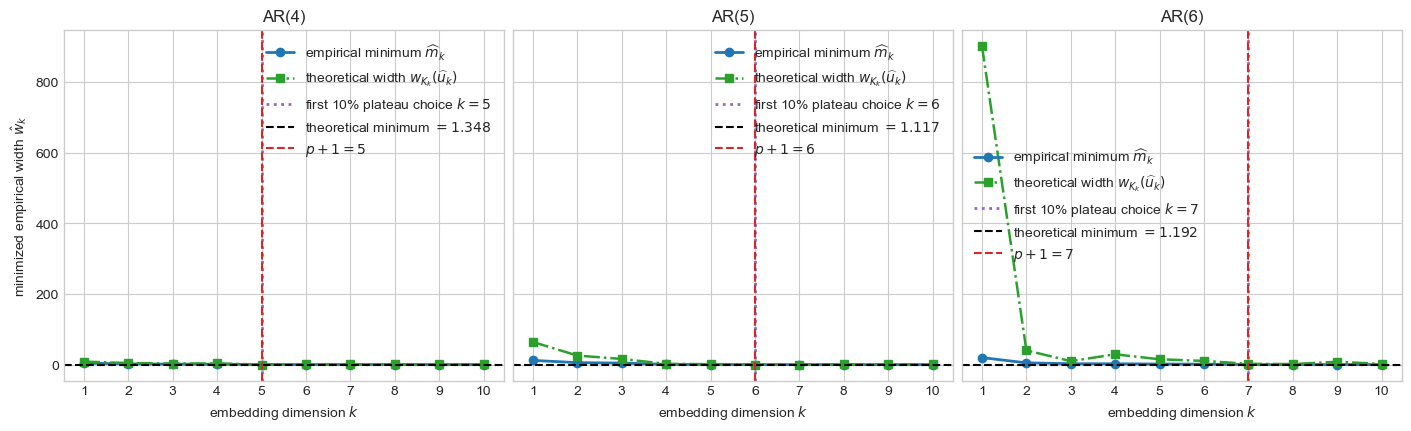

In [13]:
experiment_orders_456 = (4, 5, 6)
experiment_k_max_456 = 10
experiment_seed_456 = 20260809
experiment_rows_456 = []

for order in experiment_orders_456:
    phi_order = jones_ar_coefficients(
        p=order,
        rng=experiment_seed_456 + order,
    )
    series_order = simulate_uniform_ar(
        phi_order,
        sample_size=experiment_sample_size,
        burnin=experiment_burnin,
        half_width=experiment_half_width,
        rng=experiment_seed_456 + 100 + order,
    )

    for k in range(1, experiment_k_max_456 + 1):
        cloud_k = sliding_window_point_cloud(series_order, embedding_dimension=k)
        restart_fits = [
            projected_subgradient_empirical_width(
                cloud_k,
                iterations=experiment_iterations,
                initial_step=experiment_initial_step,
                rng=experiment_seed_456 + 10_000 * order + 100 * k + restart,
            )
            for restart in range(experiment_restarts)
        ]
        width_fit = min(restart_fits, key=lambda fit: fit["minimum_width"])
        theoretical_direction_width = theoretical_ar_width_in_direction(
            phi_order,
            width_fit["direction"],
            half_width=experiment_half_width,
        )
        experiment_rows_456.append({
            "p": order,
            "k": k,
            "minimum_width": width_fit["minimum_width"],
            "minimizing_direction": width_fit["direction"].copy(),
            "theoretical_width_at_empirical_direction": theoretical_direction_width,
            "phi": phi_order.copy(),
        })

minimum_width_experiment_456 = pd.DataFrame(experiment_rows_456)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), constrained_layout=True, sharey=True)

for axis, order in zip(axes, experiment_orders_456):
    order_results = minimum_width_experiment_456[
        minimum_width_experiment_456["p"] == order
    ]
    axis.plot(
        order_results["k"],
        order_results["minimum_width"],
        marker="o",
        linewidth=2.0,
        color="tab:blue",
        label=r"empirical minimum $\widehat{m}_k$",
    )
    axis.plot(
        order_results["k"],
        order_results["theoretical_width_at_empirical_direction"],
        marker="s",
        linestyle="-.",
        linewidth=1.8,
        color="tab:green",
        label=r"theoretical width $w_{K_k}(\widehat{u}_k)$",
    )

    plateau_fit = first_plateau_selector(
        order_results["k"].to_numpy(),
        order_results["minimum_width"].to_numpy(),
        relative_tolerance=plateau_relative_tolerance,
    )
    plateau_choice = plateau_fit["selected_k"]
    axis.axvline(
        plateau_choice,
        color="tab:purple",
        linestyle=":",
        linewidth=2.0,
        label=fr"first 10% plateau choice $k={plateau_choice}$",
    )

    phi_order = order_results["phi"].iloc[0]
    recurrence_vector = np.r_[1.0, -phi_order]
    theoretical_minimum_width = (
        2.0 * experiment_half_width / np.linalg.norm(recurrence_vector)
    )
    axis.axhline(
        theoretical_minimum_width,
        color="black",
        linestyle="--",
        linewidth=1.5,
        label=fr"theoretical minimum $={theoretical_minimum_width:.3f}$",
    )
    axis.axvline(
        order + 1,
        color="tab:red",
        linestyle="--",
        linewidth=1.5,
        label=fr"$p+1={order + 1}$",
    )
    axis.set(
        title=fr"AR({order})",
        xlabel=r"embedding dimension $k$",
        xticks=np.arange(1, experiment_k_max_456 + 1),
    )
    axis.legend()

axes[0].set_ylabel(r"minimized empirical width $\hat{w}_k$")
plt.show()


In [14]:
def aic_bic_ar_order(series, maximum_order):
    """Select conditional least-squares AR orders by Gaussian AIC and BIC."""
    series = np.asarray(series, dtype=float)
    maximum_order = int(maximum_order)
    if series.ndim != 1 or len(series) <= maximum_order + 1:
        raise ValueError("series is too short for the requested maximum_order.")

    # Use the same response times for every candidate so the criteria are comparable.
    response = series[maximum_order:]
    lag_matrix = np.column_stack([
        series[maximum_order - lag:len(series) - lag]
        for lag in range(1, maximum_order + 1)
    ])
    observation_count = len(response)
    criterion_rows = []

    for order in range(maximum_order + 1):
        if order == 0:
            design = np.ones((observation_count, 1))
        else:
            design = np.column_stack([
                np.ones(observation_count),
                lag_matrix[:, :order],
            ])

        coefficients, *_ = np.linalg.lstsq(design, response, rcond=None)
        residuals = response - design @ coefficients
        residual_sum_of_squares = max(
            float(residuals @ residuals),
            np.finfo(float).tiny,
        )
        parameter_count = order + 2  # intercept, AR coefficients, innovation variance
        gaussian_deviance = observation_count * np.log(
            residual_sum_of_squares / observation_count
        )
        criterion_rows.append({
            "order": order,
            "AIC": gaussian_deviance + 2.0 * parameter_count,
            "BIC": gaussian_deviance + np.log(observation_count) * parameter_count,
        })

    criterion_table = pd.DataFrame(criterion_rows)
    aic_order = int(criterion_table.loc[criterion_table["AIC"].idxmin(), "order"])
    bic_order = int(criterion_table.loc[criterion_table["BIC"].idxmin(), "order"])
    return aic_order, bic_order, criterion_table


def yule_walker_pacf(series, maximum_lag):
    """Estimate PACF values with the Durbin-Levinson/Yule-Walker recursion."""
    series = np.asarray(series, dtype=float)
    centered = series - np.mean(series)
    sample_size = len(centered)
    if maximum_lag < 1 or maximum_lag >= sample_size:
        raise ValueError("Require 1 <= maximum_lag < len(series).")

    autocovariance = np.array([
        centered[lag:] @ centered[:sample_size - lag] / sample_size
        for lag in range(maximum_lag + 1)
    ])
    if autocovariance[0] <= np.finfo(float).eps:
        raise ValueError("Cannot estimate PACF from a constant series.")

    pacf_values = np.empty(maximum_lag + 1)
    pacf_values[0] = 1.0
    previous_phi = np.empty(0)

    for order in range(1, maximum_lag + 1):
        if order == 1:
            reflection = autocovariance[1] / autocovariance[0]
        else:
            numerator = autocovariance[order] - (
                previous_phi @ autocovariance[order - 1:0:-1]
            )
            denominator = autocovariance[0] - (
                previous_phi @ autocovariance[1:order]
            )
            reflection = numerator / max(denominator, np.finfo(float).eps)

        pacf_values[order] = reflection
        updated_phi = np.empty(order)
        if order > 1:
            updated_phi[:-1] = previous_phi - reflection * previous_phi[::-1]
        updated_phi[-1] = reflection
        previous_phi = updated_phi

    return pacf_values


def pacf_cutoff_order(series, maximum_order, confidence_multiplier=1.96):
    """Choose the largest lag whose PACF exceeds the approximate confidence band."""
    pacf_values = yule_walker_pacf(series, maximum_order)
    cutoff = confidence_multiplier / np.sqrt(len(series))
    significant_lags = np.flatnonzero(np.abs(pacf_values[1:]) > cutoff) + 1
    selected_order = int(significant_lags[-1]) if len(significant_lags) else 0
    return selected_order, pacf_values, cutoff


def minimum_width_order(
    series,
    maximum_order,
    width_iterations,
    width_restarts,
    width_patience,
    initial_step,
    plateau_tolerance,
    rng,
):
    """Estimate p as one less than the first empirical width plateau scale."""
    minimized_widths = []
    for k in range(1, maximum_order + 2):
        cloud_k = sliding_window_point_cloud(series, embedding_dimension=k)
        restart_fits = [
            projected_subgradient_empirical_width(
                cloud_k,
                iterations=width_iterations,
                initial_step=initial_step,
                patience=width_patience,
                rng=rng,
            )
            for _ in range(width_restarts)
        ]
        best_fit = min(restart_fits, key=lambda fit: fit["minimum_width"])
        minimized_widths.append(best_fit["minimum_width"])

    k_values = np.arange(1, maximum_order + 2)
    plateau_fit = first_plateau_selector(
        k_values,
        minimized_widths,
        relative_tolerance=plateau_tolerance,
    )
    selected_order = plateau_fit["selected_k"] - 1
    return int(selected_order), np.asarray(minimized_widths)


def run_order_selection_comparison(
    orders=range(1, 7),
    replications=50,
    maximum_order=10,
    sample_size=2_000,
    burnin=1_000,
    innovation_half_width=1.0,
    width_iterations=2_000,
    width_restarts=1,
    width_patience=200,
    width_initial_step=0.2,
    plateau_tolerance=0.10,
    seed=20260810,
):
    """Compare minimum width, AIC, BIC, and PACF cutoff over simulated AR models."""
    generator = np.random.default_rng(seed)
    result_rows = []

    for true_order in orders:
        for replication in range(replications):
            # Each replication receives both a new stationary model and new innovations.
            phi = jones_ar_coefficients(true_order, rng=generator)
            series = simulate_uniform_ar(
                phi,
                sample_size=sample_size,
                burnin=burnin,
                half_width=innovation_half_width,
                rng=generator,
            )

            width_order, _ = minimum_width_order(
                series,
                maximum_order=maximum_order,
                width_iterations=width_iterations,
                width_restarts=width_restarts,
                width_patience=width_patience,
                initial_step=width_initial_step,
                plateau_tolerance=plateau_tolerance,
                rng=generator,
            )
            aic_order, bic_order, _ = aic_bic_ar_order(series, maximum_order)
            pacf_order, _, _ = pacf_cutoff_order(series, maximum_order)

            selections = {
                "Minimum width": width_order,
                "AIC": aic_order,
                "BIC": bic_order,
                "PACF cutoff": pacf_order,
            }
            for method, selected_order in selections.items():
                result_rows.append({
                    "true_order": true_order,
                    "replication": replication,
                    "method": method,
                    "selected_order": selected_order,
                    "correct": selected_order == true_order,
                })

        print(f"Completed p={true_order}: {replications} processes")

    return pd.DataFrame(result_rows)


Completed p=1: 50 processes
Completed p=2: 50 processes
Completed p=3: 50 processes
Completed p=4: 50 processes
Completed p=5: 50 processes
Completed p=6: 50 processes
Correct selections out of 50
method      AIC  BIC  Minimum width  PACF cutoff
true_order                                      
1            34   47             42           32
2            41   47             39           36
3            43   48             21           33
4            40   45             25           36
5            35   44             25           30
6            37   47             20           38

Accuracy
method       AIC   BIC  Minimum width  PACF cutoff
true_order                                        
1           0.68  0.94           0.84         0.64
2           0.82  0.94           0.78         0.72
3           0.86  0.96           0.42         0.66
4           0.80  0.90           0.50         0.72
5           0.70  0.88           0.50         0.60
6           0.74  0.94           0.40       

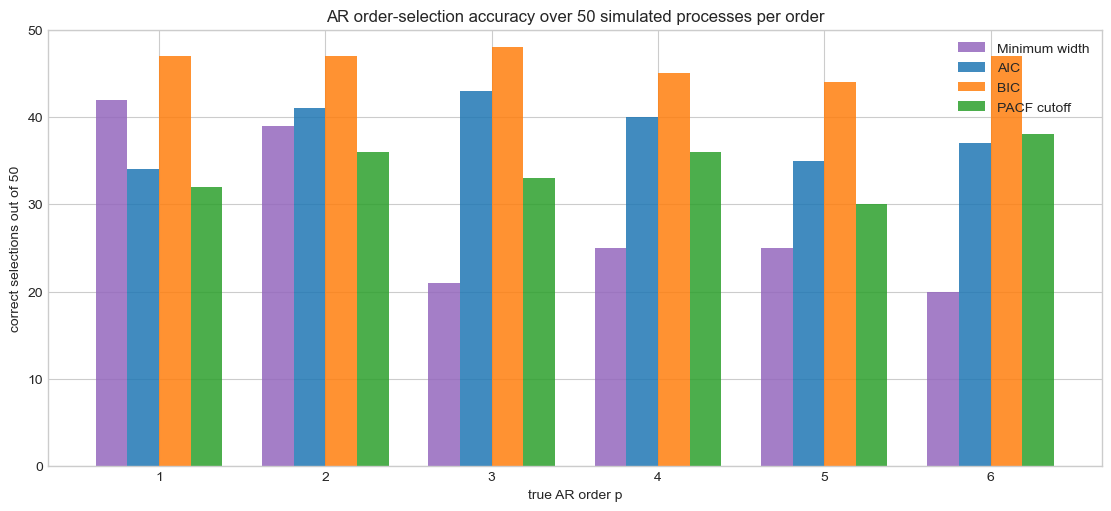

In [15]:
comparison_replications = 50
comparison_maximum_order = 10

order_comparison_results = run_order_selection_comparison(
    orders=range(1, 7),
    replications=comparison_replications,
    maximum_order=comparison_maximum_order,
    sample_size=2_000,
    burnin=1_000,
    innovation_half_width=1.0,
    width_iterations=2_000,
    width_restarts=1,
    width_patience=200,
    width_initial_step=0.2,
    plateau_tolerance=plateau_relative_tolerance,
    seed=20260810,
)

order_comparison_summary = (
    order_comparison_results
    .groupby(["true_order", "method"])["correct"]
    .agg(correct_count="sum", accuracy="mean")
    .reset_index()
)

correct_count_table = order_comparison_summary.pivot(
    index="true_order",
    columns="method",
    values="correct_count",
)
accuracy_table = order_comparison_summary.pivot(
    index="true_order",
    columns="method",
    values="accuracy",
)

print("Correct selections out of", comparison_replications)
print(correct_count_table.to_string())
print("\nAccuracy")
print(accuracy_table.round(3).to_string())

methods = ["Minimum width", "AIC", "BIC", "PACF cutoff"]
colors = ["tab:purple", "tab:blue", "tab:orange", "tab:green"]
true_orders = np.arange(1, 7)
bar_width = 0.19

fig, ax = plt.subplots(figsize=(11, 5), constrained_layout=True)
for method_index, (method, color) in enumerate(zip(methods, colors)):
    offset = (method_index - (len(methods) - 1) / 2) * bar_width
    counts = correct_count_table.loc[true_orders, method].to_numpy()
    ax.bar(
        true_orders + offset,
        counts,
        width=bar_width,
        label=method,
        color=color,
        alpha=0.85,
    )

ax.set(
    title="AR order-selection accuracy over 50 simulated processes per order",
    xlabel="true AR order p",
    ylabel="correct selections out of 50",
    xticks=true_orders,
    ylim=(0, comparison_replications),
)
ax.legend()
plt.show()


## Exact empirical-minimum selector for 100 AR(1) processes

This experiment deliberately uses the simplest selector
[
widehat{k}=minoperatorname*{arg,min}_{1leq kleq K}widehat{m}_k,
qquad
widehat{p}=widehat{k}-1.
]
Every replication draws a new stationary AR(1) coefficient and new uniform innovations. The width optimizer and its settings are held fixed across dimensions.

In [ ]:
def first_minimum_selector(k_values, minimized_widths):
    """Select the first dimension attaining the exact empirical minimum."""
    k_values = np.asarray(k_values)
    minimized_widths = np.asarray(minimized_widths, dtype=float)
    if k_values.ndim != 1 or minimized_widths.ndim != 1:
        raise ValueError("k_values and minimized_widths must be one-dimensional.")
    if len(k_values) == 0 or len(k_values) != len(minimized_widths):
        raise ValueError("Inputs must have the same positive length.")
    if not np.all(np.isfinite(minimized_widths)):
        raise ValueError("All minimized widths must be finite.")

    minimum_index = int(np.argmin(minimized_widths))
    return {
        "selected_k": int(k_values[minimum_index]),
        "selected_order": int(k_values[minimum_index]) - 1,
        "minimum_width": float(minimized_widths[minimum_index]),
    }


minimum_selector_replications = 100
minimum_selector_true_order = 1
minimum_selector_maximum_k = 10
minimum_selector_sample_size = 2_000
minimum_selector_burnin = 1_000
minimum_selector_half_width = 1.0
minimum_selector_iterations = 500
minimum_selector_patience = 100
minimum_selector_initial_step = 0.2
minimum_selector_seed = 20260813

minimum_selector_k_values = np.arange(
    1, minimum_selector_maximum_k + 1
)
minimum_selector_rows = []
minimum_selector_width_rows = []

for replication in range(minimum_selector_replications):
    process_generator = np.random.default_rng(np.random.SeedSequence([
        minimum_selector_seed, replication, 0
    ]))
    phi_replication = jones_ar_coefficients(
        minimum_selector_true_order,
        rng=process_generator,
    )
    series_replication = simulate_uniform_ar(
        phi_replication,
        sample_size=minimum_selector_sample_size,
        burnin=minimum_selector_burnin,
        half_width=minimum_selector_half_width,
        rng=process_generator,
    )

    minimized_widths = []
    for k in minimum_selector_k_values:
        cloud_k = sliding_window_point_cloud(
            series_replication,
            embedding_dimension=k,
        )

        # Use the smallest-covariance direction as a deterministic,
        # dimension-appropriate initialization for every width fit.
        if k == 1:
            initial_direction = np.ones(1)
        else:
            centered_cloud_k = cloud_k - np.mean(cloud_k, axis=0)
            covariance_k = (
                centered_cloud_k.T @ centered_cloud_k / len(centered_cloud_k)
            )
            _, covariance_eigenvectors_k = np.linalg.eigh(covariance_k)
            initial_direction = covariance_eigenvectors_k[:, 0]

        optimizer_generator = np.random.default_rng(np.random.SeedSequence([
            minimum_selector_seed, replication, int(k), 1
        ]))
        width_fit = projected_subgradient_empirical_width(
            cloud_k,
            iterations=minimum_selector_iterations,
            initial_step=minimum_selector_initial_step,
            patience=minimum_selector_patience,
            initial_direction=initial_direction,
            rng=optimizer_generator,
        )
        minimized_widths.append(width_fit["minimum_width"])
        minimum_selector_width_rows.append({
            "replication": replication,
            "phi": float(phi_replication[0]),
            "k": int(k),
            "minimum_width": width_fit["minimum_width"],
        })

    selector_fit = first_minimum_selector(
        minimum_selector_k_values,
        minimized_widths,
    )
    minimum_selector_rows.append({
        "replication": replication,
        "phi": float(phi_replication[0]),
        "selected_k": selector_fit["selected_k"],
        "selected_order": selector_fit["selected_order"],
        "correct": (
            selector_fit["selected_order"]
            == minimum_selector_true_order
        ),
    })

    if (replication + 1) % 10 == 0:
        print(
            f"Completed {replication + 1}/"
            f"{minimum_selector_replications} AR(1) processes"
        )

minimum_selector_results = pd.DataFrame(minimum_selector_rows)
minimum_selector_widths = pd.DataFrame(minimum_selector_width_rows)
minimum_selector_distribution = (
    minimum_selector_results["selected_order"]
    .value_counts()
    .sort_index()
    .rename_axis("selected_order")
    .reset_index(name="count")
)
minimum_selector_accuracy = float(
    minimum_selector_results["correct"].mean()
)

print(
    f"\nExact empirical-minimum selector accuracy: "
    f"{minimum_selector_results['correct'].sum()}/"
    f"{minimum_selector_replications} "
    f"({100.0 * minimum_selector_accuracy:.1f}%)"
)
print("\nSelected-order distribution")
print(minimum_selector_distribution.to_string(index=False))

minimum_selector_widths = minimum_selector_widths.merge(
    minimum_selector_widths.groupby("replication")["minimum_width"]
    .min()
    .rename("replication_minimum"),
    on="replication",
)
minimum_selector_widths["relative_to_replication_minimum"] = (
    minimum_selector_widths["minimum_width"]
    / minimum_selector_widths["replication_minimum"]
)
minimum_selector_mean_curve = (
    minimum_selector_widths
    .groupby("k")["relative_to_replication_minimum"]
    .agg(mean="mean", lower=lambda x: np.quantile(x, 0.10),
         upper=lambda x: np.quantile(x, 0.90))
    .reset_index()
)

fig, axes = plt.subplots(
    1, 2, figsize=(13, 4.6), constrained_layout=True
)
for replication in range(min(20, minimum_selector_replications)):
    replication_curve = minimum_selector_widths[
        minimum_selector_widths["replication"] == replication
    ]
    axes[0].plot(
        replication_curve["k"],
        replication_curve["relative_to_replication_minimum"],
        color="tab:blue",
        alpha=0.12,
        linewidth=1.0,
    )
axes[0].fill_between(
    minimum_selector_mean_curve["k"],
    minimum_selector_mean_curve["lower"],
    minimum_selector_mean_curve["upper"],
    color="tab:blue",
    alpha=0.18,
    label="10th–90th percentile",
)
axes[0].plot(
    minimum_selector_mean_curve["k"],
    minimum_selector_mean_curve["mean"],
    color="tab:blue",
    marker="o",
    linewidth=2.3,
    label="mean normalized width",
)
axes[0].axvline(
    minimum_selector_true_order + 1,
    color="tab:red",
    linestyle="--",
    linewidth=2,
    label=r"correct plateau onset $p+1=2$",
)
axes[0].set(
    title="Empirical minimum-width curves",
    xlabel=r"embedding dimension $k$",
    ylabel=r"$\widehat m_k/\min_j\widehat m_j$",
    xticks=minimum_selector_k_values,
)
axes[0].legend()

all_selected_orders = np.arange(
    0, minimum_selector_maximum_k
)
selected_counts = (
    minimum_selector_results["selected_order"]
    .value_counts()
    .reindex(all_selected_orders, fill_value=0)
)
bar_colors = [
    "tab:green" if order == minimum_selector_true_order else "tab:gray"
    for order in all_selected_orders
]
axes[1].bar(
    all_selected_orders,
    selected_counts.to_numpy(),
    color=bar_colors,
    alpha=0.85,
)
axes[1].set(
    title=(
        "First exact empirical minimum: "
        f"{100.0 * minimum_selector_accuracy:.1f}% correct"
    ),
    xlabel=r"selected AR order $\widehat p=\widehat k-1$",
    ylabel="number of processes",
    xticks=all_selected_orders,
    ylim=(0, minimum_selector_replications),
)
plt.show()

## Comparison with BIC and the PACF cutoff

The following comparison reuses exactly the same 100 AR(1) processes through their deterministic replication seeds. BIC and the PACF cutoff search orders 0 through 9, matching the range available to the geometric selectors. The 2% plateau result is included as exploratory because that tolerance was inspected after seeing these simulations; the pre-existing 10% rule is the prespecified geometric comparison.

In [ ]:
minimum_selector_comparison_maximum_order = (
    minimum_selector_maximum_k - 1
)
minimum_selector_method_rows = []

for replication in range(minimum_selector_replications):
    process_generator = np.random.default_rng(np.random.SeedSequence([
        minimum_selector_seed, replication, 0
    ]))
    phi_replication = jones_ar_coefficients(
        minimum_selector_true_order,
        rng=process_generator,
    )
    series_replication = simulate_uniform_ar(
        phi_replication,
        sample_size=minimum_selector_sample_size,
        burnin=minimum_selector_burnin,
        half_width=minimum_selector_half_width,
        rng=process_generator,
    )

    _, bic_order, _ = aic_bic_ar_order(
        series_replication,
        maximum_order=minimum_selector_comparison_maximum_order,
    )
    pacf_order, _, _ = pacf_cutoff_order(
        series_replication,
        maximum_order=minimum_selector_comparison_maximum_order,
    )

    replication_widths = (
        minimum_selector_widths[
            minimum_selector_widths["replication"] == replication
        ]
        .sort_values("k")
    )
    exact_minimum_order = int(
        minimum_selector_results.loc[
            minimum_selector_results["replication"] == replication,
            "selected_order",
        ].iloc[0]
    )
    plateau_10_order = (
        first_plateau_selector(
            replication_widths["k"].to_numpy(),
            replication_widths["minimum_width"].to_numpy(),
            relative_tolerance=0.10,
        )["selected_k"] - 1
    )
    plateau_02_order = (
        first_plateau_selector(
            replication_widths["k"].to_numpy(),
            replication_widths["minimum_width"].to_numpy(),
            relative_tolerance=0.02,
        )["selected_k"] - 1
    )

    selections = {
        "Exact minimum width": exact_minimum_order,
        "First 10% plateau": plateau_10_order,
        "First 2% plateau (exploratory)": plateau_02_order,
        "BIC": bic_order,
        "PACF cutoff": pacf_order,
    }
    for method, selected_order in selections.items():
        minimum_selector_method_rows.append({
            "replication": replication,
            "phi": float(phi_replication[0]),
            "method": method,
            "selected_order": int(selected_order),
            "correct": (
                selected_order == minimum_selector_true_order
            ),
        })

minimum_selector_method_comparison = pd.DataFrame(
    minimum_selector_method_rows
)
minimum_selector_method_summary = (
    minimum_selector_method_comparison
    .groupby("method")["correct"]
    .agg(correct_count="sum", accuracy="mean")
    .reset_index()
    .sort_values("accuracy", ascending=False)
)
minimum_selector_method_distribution = (
    minimum_selector_method_comparison
    .groupby(["method", "selected_order"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=np.arange(
        0, minimum_selector_comparison_maximum_order + 1
    ), fill_value=0)
)

print("Comparison on the same 100 AR(1) processes")
print(
    minimum_selector_method_summary.assign(
        accuracy_percent=lambda table: 100.0 * table["accuracy"]
    )[["method", "correct_count", "accuracy_percent"]]
    .round({"accuracy_percent": 1})
    .to_string(index=False)
)
print("\nSelected-order distributions")
print(minimum_selector_method_distribution.to_string())

comparison_method_order = [
    "Exact minimum width",
    "First 10% plateau",
    "First 2% plateau (exploratory)",
    "BIC",
    "PACF cutoff",
]
comparison_colors = [
    "tab:gray",
    "tab:purple",
    "tab:pink",
    "tab:blue",
    "tab:green",
]

fig, axes = plt.subplots(
    1, 2, figsize=(15, 5), constrained_layout=True
)
summary_for_plot = (
    minimum_selector_method_summary
    .set_index("method")
    .loc[comparison_method_order]
)
axes[0].bar(
    np.arange(len(comparison_method_order)),
    summary_for_plot["correct_count"],
    color=comparison_colors,
    alpha=0.88,
)
for method_index, correct_count in enumerate(
    summary_for_plot["correct_count"]
):
    axes[0].text(
        method_index,
        correct_count + 1.5,
        f"{int(correct_count)}/100",
        ha="center",
        va="bottom",
    )
axes[0].set(
    title="AR(1) order-selection accuracy",
    ylabel="correct selections out of 100",
    xticks=np.arange(len(comparison_method_order)),
    xticklabels=comparison_method_order,
    ylim=(0, 108),
)
axes[0].tick_params(axis="x", rotation=25)

selected_orders = np.arange(
    0, minimum_selector_comparison_maximum_order + 1
)
bar_width = 0.16
for method_index, (method, color) in enumerate(zip(
    comparison_method_order, comparison_colors
)):
    offset = (
        method_index - (len(comparison_method_order) - 1) / 2
    ) * bar_width
    counts = (
        minimum_selector_method_distribution
        .loc[method, selected_orders]
        .to_numpy()
    )
    axes[1].bar(
        selected_orders + offset,
        counts,
        width=bar_width,
        label=method,
        color=color,
        alpha=0.82,
    )

axes[1].axvline(
    minimum_selector_true_order,
    color="black",
    linestyle="--",
    linewidth=1.5,
)
axes[1].set(
    title="Distribution of selected orders",
    xlabel=r"selected order $\widehat p$",
    ylabel="number of processes",
    xticks=selected_orders,
)
axes[1].legend(fontsize=8)
plt.show()

## Selector comparison for 100 AR(2) processes

This repeats the AR(1) design for independently generated stationary AR(2) models. The correct population plateau onset is (k=p+1=3). All geometric selectors, BIC, and the PACF cutoff search the same effective order range 0 through 9.

In [ ]:
ar2_selector_replications = 100
ar2_selector_true_order = 2
ar2_selector_maximum_k = 10
ar2_selector_sample_size = 2_000
ar2_selector_burnin = 1_000
ar2_selector_half_width = 1.0
ar2_selector_iterations = 500
ar2_selector_patience = 100
ar2_selector_initial_step = 0.2
ar2_selector_seed = 20260814
ar2_selector_k_values = np.arange(1, ar2_selector_maximum_k + 1)

ar2_selector_rows = []
ar2_selector_width_rows = []

for replication in range(ar2_selector_replications):
    process_generator = np.random.default_rng(np.random.SeedSequence([
        ar2_selector_seed, replication, 0
    ]))
    phi_replication = jones_ar_coefficients(
        ar2_selector_true_order,
        rng=process_generator,
    )
    series_replication = simulate_uniform_ar(
        phi_replication,
        sample_size=ar2_selector_sample_size,
        burnin=ar2_selector_burnin,
        half_width=ar2_selector_half_width,
        rng=process_generator,
    )

    minimized_widths = []
    for k in ar2_selector_k_values:
        cloud_k = sliding_window_point_cloud(
            series_replication,
            embedding_dimension=k,
        )
        if k == 1:
            initial_direction = np.ones(1)
        else:
            centered_cloud_k = cloud_k - np.mean(cloud_k, axis=0)
            covariance_k = (
                centered_cloud_k.T @ centered_cloud_k / len(centered_cloud_k)
            )
            _, covariance_eigenvectors_k = np.linalg.eigh(covariance_k)
            initial_direction = covariance_eigenvectors_k[:, 0]

        optimizer_generator = np.random.default_rng(np.random.SeedSequence([
            ar2_selector_seed, replication, int(k), 1
        ]))
        width_fit = projected_subgradient_empirical_width(
            cloud_k,
            iterations=ar2_selector_iterations,
            initial_step=ar2_selector_initial_step,
            patience=ar2_selector_patience,
            initial_direction=initial_direction,
            rng=optimizer_generator,
        )
        minimized_widths.append(width_fit["minimum_width"])
        ar2_selector_width_rows.append({
            "replication": replication,
            "phi_1": float(phi_replication[0]),
            "phi_2": float(phi_replication[1]),
            "k": int(k),
            "minimum_width": width_fit["minimum_width"],
        })

    exact_fit = first_minimum_selector(
        ar2_selector_k_values,
        minimized_widths,
    )
    plateau_10_fit = first_plateau_selector(
        ar2_selector_k_values,
        minimized_widths,
        relative_tolerance=0.10,
    )
    plateau_02_fit = first_plateau_selector(
        ar2_selector_k_values,
        minimized_widths,
        relative_tolerance=0.02,
    )
    _, bic_order, _ = aic_bic_ar_order(
        series_replication,
        maximum_order=ar2_selector_maximum_k - 1,
    )
    pacf_order, _, _ = pacf_cutoff_order(
        series_replication,
        maximum_order=ar2_selector_maximum_k - 1,
    )

    selections = {
        "Exact minimum width": exact_fit["selected_order"],
        "First 10% plateau": plateau_10_fit["selected_k"] - 1,
        "First 2% plateau (exploratory)": plateau_02_fit["selected_k"] - 1,
        "BIC": bic_order,
        "PACF cutoff": pacf_order,
    }
    for method, selected_order in selections.items():
        ar2_selector_rows.append({
            "replication": replication,
            "phi_1": float(phi_replication[0]),
            "phi_2": float(phi_replication[1]),
            "method": method,
            "selected_order": int(selected_order),
            "correct": selected_order == ar2_selector_true_order,
        })

    if (replication + 1) % 10 == 0:
        print(
            f"Completed {replication + 1}/"
            f"{ar2_selector_replications} AR(2) processes"
        )

ar2_selector_comparison = pd.DataFrame(ar2_selector_rows)
ar2_selector_widths = pd.DataFrame(ar2_selector_width_rows)
ar2_selector_summary = (
    ar2_selector_comparison
    .groupby("method")["correct"]
    .agg(correct_count="sum", accuracy="mean")
    .reset_index()
    .sort_values("accuracy", ascending=False)
)
ar2_selector_distribution = (
    ar2_selector_comparison
    .groupby(["method", "selected_order"])
    .size()
    .unstack(fill_value=0)
    .reindex(
        columns=np.arange(0, ar2_selector_maximum_k),
        fill_value=0,
    )
)

print("\nComparison on the same 100 AR(2) processes")
print(
    ar2_selector_summary.assign(
        accuracy_percent=lambda table: 100.0 * table["accuracy"]
    )[["method", "correct_count", "accuracy_percent"]]
    .round({"accuracy_percent": 1})
    .to_string(index=False)
)
print("\nSelected-order distributions")
print(ar2_selector_distribution.to_string())

ar2_method_order = [
    "Exact minimum width",
    "First 10% plateau",
    "First 2% plateau (exploratory)",
    "BIC",
    "PACF cutoff",
]
ar2_method_colors = [
    "tab:gray",
    "tab:purple",
    "tab:pink",
    "tab:blue",
    "tab:green",
]

fig, axes = plt.subplots(
    1, 2, figsize=(15, 5), constrained_layout=True
)
ar2_summary_for_plot = (
    ar2_selector_summary
    .set_index("method")
    .loc[ar2_method_order]
)
axes[0].bar(
    np.arange(len(ar2_method_order)),
    ar2_summary_for_plot["correct_count"],
    color=ar2_method_colors,
    alpha=0.88,
)
for method_index, correct_count in enumerate(
    ar2_summary_for_plot["correct_count"]
):
    axes[0].text(
        method_index,
        correct_count + 1.5,
        f"{int(correct_count)}/100",
        ha="center",
        va="bottom",
    )
axes[0].set(
    title="AR(2) order-selection accuracy",
    ylabel="correct selections out of 100",
    xticks=np.arange(len(ar2_method_order)),
    xticklabels=ar2_method_order,
    ylim=(0, 108),
)
axes[0].tick_params(axis="x", rotation=25)

ar2_selected_orders = np.arange(0, ar2_selector_maximum_k)
bar_width = 0.16
for method_index, (method, color) in enumerate(zip(
    ar2_method_order, ar2_method_colors
)):
    offset = (
        method_index - (len(ar2_method_order) - 1) / 2
    ) * bar_width
    axes[1].bar(
        ar2_selected_orders + offset,
        ar2_selector_distribution
        .loc[method, ar2_selected_orders]
        .to_numpy(),
        width=bar_width,
        label=method,
        color=color,
        alpha=0.82,
    )

axes[1].axvline(
    ar2_selector_true_order,
    color="black",
    linestyle="--",
    linewidth=1.5,
)
axes[1].set(
    title="Distribution of selected orders",
    xlabel=r"selected order $\widehat p$",
    ylabel="number of processes",
    xticks=ar2_selected_orders,
)
axes[1].legend(fontsize=8)
plt.show()

## Robust flat-tail selectors for uniform AR processes

This experiment implements all three proposed improvements: three optimizer starts per embedding dimension, a decreasing isotonic projection of the width curve, and a 95% simultaneous flat-tail threshold estimated by a moving-block bootstrap. For context it also evaluates the established L-method and Kneedle's normalized chord-distance rule. The AR(1) guardrail is essential: with two points required on either side of its breakpoint, the standard L-method cannot select order one.

The bootstrap below is a computationally inexpensive pilot. It holds each optimized direction fixed and resamples its projected series; it therefore captures serial and range variability but not the additional variability from re-optimizing every bootstrap sample. A thesis-level inferential claim would require a full block bootstrap with re-optimization or a separate proof of validity.

In [ ]:
def decreasing_isotonic_projection(values):
    """Least-squares projection onto non-increasing sequences (PAVA)."""
    values = np.asarray(values, dtype=float)
    block_values, block_weights = [], []
    block_starts, block_ends = [], []
    for index, value in enumerate(values):
        block_values.append(float(value))
        block_weights.append(1.0)
        block_starts.append(index)
        block_ends.append(index)
        while (
            len(block_values) >= 2
            and block_values[-2] < block_values[-1]
        ):
            merged_weight = block_weights[-2] + block_weights[-1]
            merged_value = (
                block_weights[-2] * block_values[-2]
                + block_weights[-1] * block_values[-1]
            ) / merged_weight
            block_values[-2:] = [merged_value]
            block_weights[-2:] = [merged_weight]
            block_starts[-2:] = [block_starts[-2]]
            block_ends[-2:] = [block_ends[-1]]

    fitted = np.empty(len(values))
    for value, start, end in zip(
        block_values, block_starts, block_ends
    ):
        fitted[start:end + 1] = value
    return fitted


def multistart_width_curve(
    series, k_values, *, seed, replication, starts=3, iterations=500
):
    """Return best widths and projections from several starts per k."""
    widths, projections = [], []
    for k in k_values:
        cloud_k = sliding_window_point_cloud(series, int(k))
        if k == 1:
            initial_directions = [np.ones(1)]
        else:
            covariance_k = np.cov(cloud_k, rowvar=False)
            _, eigenvectors_k = np.linalg.eigh(covariance_k)
            initial_directions = [eigenvectors_k[:, 0]]

        initial_generator = np.random.default_rng(
            np.random.SeedSequence([seed, replication, int(k), 20])
        )
        initial_directions.extend(
            initial_generator.normal(size=int(k))
            for _ in range(starts - 1)
        )
        fits = []
        for start, initial_direction in enumerate(initial_directions):
            fits.append(projected_subgradient_empirical_width(
                cloud_k,
                iterations=iterations,
                initial_step=0.2,
                patience=100,
                initial_direction=initial_direction,
                rng=np.random.default_rng(np.random.SeedSequence([
                    seed, replication, int(k), 21, start
                ])),
            ))
        best_fit = min(fits, key=lambda fit: fit["minimum_width"])
        widths.append(best_fit["minimum_width"])
        projections.append(cloud_k @ best_fit["direction"])
    return np.asarray(widths), projections


def projected_block_bootstrap_flat_tail(
    widths, projections, *, rng, bootstrap_replications=50, alpha=0.05
):
    """Select the first suffix statistically indistinguishable from flat."""
    isotonic_widths = decreasing_isotonic_projection(widths)
    bootstrap_widths = np.empty((
        bootstrap_replications, len(widths)
    ))
    for column, projection in enumerate(projections):
        sample_count = len(projection)
        block_length = max(2, int(round(sample_count ** (1 / 3))))
        block_count = int(np.ceil(sample_count / block_length))
        for batch_start in range(0, bootstrap_replications, 10):
            batch_end = min(bootstrap_replications, batch_start + 10)
            starts = rng.integers(
                0, sample_count, size=(batch_end - batch_start, block_count)
            )
            indices = (
                starts[:, :, None] + np.arange(block_length)
            ) % sample_count
            indices = indices.reshape(batch_end - batch_start, -1)[
                :, :sample_count
            ]
            resampled = projection[indices]
            bootstrap_widths[batch_start:batch_end, column] = (
                resampled.max(axis=1) - resampled.min(axis=1)
            )

    bootstrap_isotonic = np.vstack([
        decreasing_isotonic_projection(row)
        for row in bootstrap_widths
    ])
    bootstrap_contrasts = (
        bootstrap_isotonic - bootstrap_isotonic[:, -1, None]
    )
    centered_contrasts = (
        bootstrap_contrasts
        - bootstrap_contrasts.mean(axis=0, keepdims=True)
    )
    simultaneous_critical_value = float(np.quantile(
        np.max(np.abs(centered_contrasts), axis=1),
        1.0 - alpha,
    ))
    observed_tail_contrasts = isotonic_widths - isotonic_widths[-1]
    selected_k = int(np.flatnonzero(
        observed_tail_contrasts <= simultaneous_critical_value
    )[0]) + 1
    return {
        "selected_k": selected_k,
        "selected_order": selected_k - 1,
        "isotonic_widths": isotonic_widths,
        "critical_value": simultaneous_critical_value,
    }


def l_method_order(k_values, widths):
    """Two-line L-method; requires at least two points per segment."""
    def line_rmse(x_values, y_values):
        coefficients = np.polyfit(x_values, y_values, 1)
        residuals = y_values - np.polyval(coefficients, x_values)
        return float(np.sqrt(np.mean(residuals**2)))

    scores = []
    point_count = len(k_values)
    for split_index in range(1, point_count - 2):
        left_count = split_index + 1
        right_count = point_count - left_count
        score = (
            left_count / point_count
            * line_rmse(
                k_values[:left_count], widths[:left_count]
            )
            + right_count / point_count
            * line_rmse(
                k_values[left_count:], widths[left_count:]
            )
        )
        scores.append((score, int(k_values[split_index])))
    return min(scores)[1]


def kneedle_chord_order(k_values, widths):
    """Knee from maximum normalized distance below the endpoint chord."""
    normalized_k = (
        (k_values - k_values[0]) / (k_values[-1] - k_values[0])
    )
    normalized_widths = (
        (widths - np.min(widths)) / (np.max(widths) - np.min(widths))
    )
    selected_k = int(k_values[np.argmax(
        (1.0 - normalized_k) - normalized_widths
    )])
    return selected_k - 1


In [ ]:
robust_selector_rows = []
robust_selector_k_values = np.arange(1, 11)
robust_selector_settings = [
    {"true_order": 1, "seed": 20260813},
    {"true_order": 2, "seed": 20260814},
]

for setting in robust_selector_settings:
    true_order = setting["true_order"]
    experiment_seed = setting["seed"]
    for replication in range(100):
        process_generator = np.random.default_rng(np.random.SeedSequence([
            experiment_seed, replication, 0
        ]))
        phi_replication = jones_ar_coefficients(
            true_order, rng=process_generator
        )
        series_replication = simulate_uniform_ar(
            phi_replication,
            sample_size=2_000,
            burnin=1_000,
            half_width=1.0,
            rng=process_generator,
        )
        widths, projections = multistart_width_curve(
            series_replication,
            robust_selector_k_values,
            seed=experiment_seed,
            replication=replication,
            starts=3,
            iterations=500,
        )
        isotonic_widths = decreasing_isotonic_projection(widths)
        bootstrap_fit = projected_block_bootstrap_flat_tail(
            widths,
            projections,
            rng=np.random.default_rng(np.random.SeedSequence([
                experiment_seed, replication, 30
            ])),
            bootstrap_replications=50,
            alpha=0.05,
        )
        selections = {
            "10% plateau, three starts": (
                first_plateau_selector(
                    robust_selector_k_values, widths, 0.10
                )["selected_k"] - 1
            ),
            "Isotonic + 10%": (
                first_plateau_selector(
                    robust_selector_k_values, isotonic_widths, 0.10
                )["selected_k"] - 1
            ),
            "Bootstrap flat tail": bootstrap_fit["selected_order"],
            "L-method breakpoint": l_method_order(
                robust_selector_k_values, widths
            ),
            "Kneedle chord": kneedle_chord_order(
                robust_selector_k_values, widths
            ),
        }
        for method, selected_order in selections.items():
            robust_selector_rows.append({
                "true_order": true_order,
                "replication": replication,
                "method": method,
                "selected_order": int(selected_order),
                "correct": selected_order == true_order,
            })

robust_selector_results = pd.DataFrame(robust_selector_rows)
robust_selector_summary = (
    robust_selector_results
    .groupby(["method", "true_order"])["correct"]
    .sum()
    .unstack()
    .rename(columns={1: "AR(1)", 2: "AR(2)"})
)
robust_selector_summary["combined"] = (
    robust_selector_summary["AR(1)"]
    + robust_selector_summary["AR(2)"]
)
robust_selector_summary = robust_selector_summary.sort_values(
    "combined", ascending=False
)
print("Correct selections (100 processes per order)")
print(robust_selector_summary.to_string())

fig, axis = plt.subplots(figsize=(10, 5), constrained_layout=True)
plot_table = robust_selector_summary[["AR(1)", "AR(2)"]]
x_positions = np.arange(len(plot_table))
axis.bar(
    x_positions - 0.2, plot_table["AR(1)"], width=0.4, label="AR(1)"
)
axis.bar(
    x_positions + 0.2, plot_table["AR(2)"], width=0.4, label="AR(2)"
)
axis.set(
    title="Robust geometric selector comparison",
    ylabel="correct selections out of 100",
    xticks=x_positions,
    xticklabels=plot_table.index,
    ylim=(0, 105),
)
axis.tick_params(axis="x", rotation=20)
axis.legend()
plt.show()

## L-method guardrail for AR(3) and AR(4)

This applies the same standard two-line L-method to 100 independently generated stationary AR(3) processes and 100 AR(4) processes with uniform innovations. The sample size, embedding range, and three-start width optimization match the preceding robust-selector experiment.

In [ ]:
l_method_higher_order_rows = []
l_method_higher_order_k_values = np.arange(1, 11)
l_method_higher_order_settings = [
    {"true_order": 3, "seed": 20260816},
    {"true_order": 4, "seed": 20260817},
]

for setting in l_method_higher_order_settings:
    true_order = setting["true_order"]
    experiment_seed = setting["seed"]
    for replication in range(100):
        process_generator = np.random.default_rng(np.random.SeedSequence([
            experiment_seed, replication, 0
        ]))
        phi_replication = jones_ar_coefficients(
            true_order, rng=process_generator
        )
        series_replication = simulate_uniform_ar(
            phi_replication,
            sample_size=2_000,
            burnin=1_000,
            half_width=1.0,
            rng=process_generator,
        )
        widths, _ = multistart_width_curve(
            series_replication,
            l_method_higher_order_k_values,
            seed=experiment_seed,
            replication=replication,
            starts=3,
            iterations=500,
        )
        selected_order = l_method_order(
            l_method_higher_order_k_values, widths
        )
        l_method_higher_order_rows.append({
            "true_order": true_order,
            "replication": replication,
            "selected_order": selected_order,
            "correct": selected_order == true_order,
            "absolute_final_coefficient": abs(phi_replication[-1]),
        })

l_method_higher_order_results = pd.DataFrame(
    l_method_higher_order_rows
)
l_method_higher_order_summary = (
    l_method_higher_order_results
    .groupby("true_order")["correct"]
    .agg(correct_count="sum", accuracy="mean")
)
l_method_higher_order_distribution = (
    l_method_higher_order_results
    .groupby(["true_order", "selected_order"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=np.arange(10), fill_value=0)
)
print("L-method accuracy")
print(l_method_higher_order_summary.to_string())
print("\nSelected-order distributions")
print(l_method_higher_order_distribution.to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
axes[0].bar(
    ["AR(3)", "AR(4)"],
    l_method_higher_order_summary["correct_count"],
    color=["tab:green", "tab:orange"],
)
for position, count in enumerate(
    l_method_higher_order_summary["correct_count"]
):
    axes[0].text(position, count + 2, str(count), ha="center")
axes[0].set(
    title="L-method accuracy at higher orders",
    ylabel="correct selections out of 100",
    ylim=(0, 105),
)

selected_orders = np.arange(10)
bar_width = 0.38
for offset, true_order, color in [
    (-bar_width / 2, 3, "tab:green"),
    (bar_width / 2, 4, "tab:orange"),
]:
    axes[1].bar(
        selected_orders + offset,
        l_method_higher_order_distribution.loc[
            true_order, selected_orders
        ],
        width=bar_width,
        color=color,
        label=fr"true $p={true_order}$",
    )
axes[1].set(
    title="L-method selected-order distributions",
    xlabel=r"selected order $\widehat p$",
    ylabel="number of processes",
    xticks=selected_orders,
)
axes[1].legend()
plt.show()

## Common selector comparison for AR(1) through AR(4)

The table below summarizes a common experiment with 100 independently generated stationary processes per order, uniform innovations, sample size 2,000, embedding dimensions 1 through 10, and 500 projected-subgradient iterations per start. The multi-start methods use the covariance direction and two random starts.

| selector | AR(1) | AR(2) | AR(3) | AR(4) | total / 400 |
|---|---:|---:|---:|---:|---:|
| BIC | 95 | 93 | 90 | 91 | 369 |
| first 10% plateau, three starts | 95 | 86 | 62 | 71 | 314 |
| isotonic + 10% | 95 | 86 | 63 | 70 | 314 |
| bootstrap flat tail | 98 | 87 | 53 | 59 | 297 |
| first 10% plateau, one start | 95 | 79 | 50 | 64 | 288 |
| PACF cutoff | 61 | 70 | 65 | 69 | 265 |
| Kneedle chord | 99 | 84 | 42 | 36 | 261 |
| line + flat tail | 99 | 76 | 35 | 40 | 250 |
| first 2% plateau, one start | 97 | 56 | 40 | 44 | 237 |
| L-method breakpoint | 0 | 98 | 45 | 39 | 182 |
| exact minimum, one start | 15 | 10 | 8 | 11 | 44 |

The fixed-level projected bootstrap is the pilot version described above: it resamples the optimized projections without re-optimizing each bootstrap sample.

In [ ]:
def single_and_multistart_width_curves(
    series, k_values, *, seed, replication, starts=3, iterations=500,
    step_schedule="inverse_sqrt", geometric_decay=0.99, patience=100,
):
    """Return covariance-start widths and best multi-start widths."""
    single_widths, best_widths, best_projections = [], [], []
    for k in k_values:
        cloud_k = sliding_window_point_cloud(series, int(k))
        if k == 1:
            initial_directions = [np.ones(1)]
        else:
            covariance_k = np.cov(cloud_k, rowvar=False)
            _, eigenvectors_k = np.linalg.eigh(covariance_k)
            initial_directions = [eigenvectors_k[:, 0]]
        initial_generator = np.random.default_rng(
            np.random.SeedSequence([seed, replication, int(k), 20])
        )
        initial_directions.extend(
            initial_generator.normal(size=int(k))
            for _ in range(starts - 1)
        )
        fits = []
        for start, initial_direction in enumerate(initial_directions):
            fits.append(projected_subgradient_empirical_width(
                cloud_k,
                iterations=iterations,
                initial_step=0.2,
                step_schedule=step_schedule,
                geometric_decay=geometric_decay,
                patience=patience,
                initial_direction=initial_direction,
                rng=np.random.default_rng(np.random.SeedSequence([
                    seed, replication, int(k), 21, start
                ])),
            ))
        single_widths.append(fits[0]["minimum_width"])
        best_fit = min(fits, key=lambda fit: fit["minimum_width"])
        best_widths.append(best_fit["minimum_width"])
        best_projections.append(cloud_k @ best_fit["direction"])
    return (
        np.asarray(single_widths),
        np.asarray(best_widths),
        best_projections,
    )


def line_plus_flat_tail_order(k_values, widths):
    """Least-squares line before the candidate and constant tail after it."""
    scores = []
    for breakpoint_index in range(1, len(k_values) - 1):
        left_k = k_values[:breakpoint_index + 1]
        left_widths = widths[:breakpoint_index + 1]
        tail_widths = widths[breakpoint_index:]
        coefficients = np.polyfit(left_k, left_widths, 1)
        score = float(
            np.sum((
                left_widths - np.polyval(coefficients, left_k)
            )**2)
            + np.sum((tail_widths - np.mean(tail_widths))**2)
        )
        scores.append((score, int(k_values[breakpoint_index]) - 1))
    return min(scores)[1]


all_selector_rows = []
all_selector_k_values = np.arange(1, 11)
all_selector_settings = [
    {"true_order": 1, "seed": 20260813},
    {"true_order": 2, "seed": 20260814},
    {"true_order": 3, "seed": 20260816},
    {"true_order": 4, "seed": 20260817},
]

for setting in all_selector_settings:
    true_order = setting["true_order"]
    experiment_seed = setting["seed"]
    for replication in range(100):
        process_generator = np.random.default_rng(np.random.SeedSequence([
            experiment_seed, replication, 0
        ]))
        phi_replication = jones_ar_coefficients(
            true_order, rng=process_generator
        )
        series_replication = simulate_uniform_ar(
            phi_replication, 2_000, 1_000, 1.0, rng=process_generator
        )
        single_widths, best_widths, best_projections = (
            single_and_multistart_width_curves(
                series_replication,
                all_selector_k_values,
                seed=experiment_seed,
                replication=replication,
                starts=3,
                iterations=500,
            )
        )
        isotonic_widths = decreasing_isotonic_projection(best_widths)
        bootstrap_fit = projected_block_bootstrap_flat_tail(
            best_widths,
            best_projections,
            rng=np.random.default_rng(np.random.SeedSequence([
                experiment_seed, replication, 30
            ])),
            bootstrap_replications=50,
            alpha=0.05,
        )
        _, bic_order, _ = aic_bic_ar_order(series_replication, 9)
        pacf_order, _, _ = pacf_cutoff_order(series_replication, 9)
        selections = {
            "Exact minimum (one start)": first_minimum_selector(
                all_selector_k_values, single_widths
            )["selected_order"],
            "First 2% plateau (one start)": first_plateau_selector(
                all_selector_k_values, single_widths, 0.02
            )["selected_k"] - 1,
            "First 10% plateau (one start)": first_plateau_selector(
                all_selector_k_values, single_widths, 0.10
            )["selected_k"] - 1,
            "First 10% plateau (three starts)": first_plateau_selector(
                all_selector_k_values, best_widths, 0.10
            )["selected_k"] - 1,
            "Isotonic + 10%": first_plateau_selector(
                all_selector_k_values, isotonic_widths, 0.10
            )["selected_k"] - 1,
            "Bootstrap flat tail": bootstrap_fit["selected_order"],
            "Kneedle chord": kneedle_chord_order(
                all_selector_k_values, best_widths
            ),
            "Line + flat tail": line_plus_flat_tail_order(
                all_selector_k_values, best_widths
            ),
            "L-method breakpoint": l_method_order(
                all_selector_k_values, best_widths
            ),
            "BIC": bic_order,
            "PACF cutoff": pacf_order,
        }
        for method, selected_order in selections.items():
            all_selector_rows.append({
                "true_order": true_order,
                "replication": replication,
                "method": method,
                "selected_order": int(selected_order),
                "correct": selected_order == true_order,
            })

all_selector_results = pd.DataFrame(all_selector_rows)
all_selector_summary = (
    all_selector_results
    .groupby(["method", "true_order"])["correct"]
    .sum()
    .unstack(fill_value=0)
)
all_selector_summary.columns = [
    f"AR({order})" for order in all_selector_summary.columns
]
all_selector_summary["total"] = all_selector_summary.sum(axis=1)
all_selector_summary = all_selector_summary.sort_values(
    "total", ascending=False
)
print("Correct selections out of 100 per order")
print(all_selector_summary.to_string())

fig, axis = plt.subplots(figsize=(9, 7), constrained_layout=True)
heatmap_values = all_selector_summary[
    ["AR(1)", "AR(2)", "AR(3)", "AR(4)"]
].to_numpy()
image = axis.imshow(
    heatmap_values, cmap="RdYlGn", vmin=0, vmax=100, aspect="auto"
)
for row in range(heatmap_values.shape[0]):
    for column in range(heatmap_values.shape[1]):
        axis.text(
            column, row, str(heatmap_values[row, column]),
            ha="center", va="center", color="black"
        )
axis.set(
    title="Order-selection accuracy across uniform AR processes",
    xticks=np.arange(4),
    xticklabels=["AR(1)", "AR(2)", "AR(3)", "AR(4)"],
    yticks=np.arange(len(all_selector_summary)),
    yticklabels=all_selector_summary.index,
)
fig.colorbar(image, ax=axis, label="correct selections out of 100")
plt.show()

## BIC experiment for AR orders 1 through 10

For each true order, this experiment generates 100 independently parameterized stationary AR processes with uniform innovations, sample size 2,000, and burn-in 1,000. BIC searches candidate orders 0 through 15 so that the experiment at true order 10 is not artificially helped by a search boundary at 10.

In [ ]:
bic_all_order_rows = []
bic_all_order_replications = 100
bic_all_order_sample_size = 2_000
bic_all_order_burnin = 1_000
bic_all_order_maximum_candidate = 15

for true_order in range(1, 11):
    experiment_seed = 20260820 + true_order
    for replication in range(bic_all_order_replications):
        process_generator = np.random.default_rng(np.random.SeedSequence([
            experiment_seed, replication, 0
        ]))
        phi_replication = jones_ar_coefficients(
            true_order, rng=process_generator
        )
        series_replication = simulate_uniform_ar(
            phi_replication,
            sample_size=bic_all_order_sample_size,
            burnin=bic_all_order_burnin,
            half_width=1.0,
            rng=process_generator,
        )
        _, selected_order, _ = aic_bic_ar_order(
            series_replication,
            maximum_order=bic_all_order_maximum_candidate,
        )
        bic_all_order_rows.append({
            "true_order": true_order,
            "replication": replication,
            "selected_order": selected_order,
            "correct": selected_order == true_order,
            "absolute_final_coefficient": abs(phi_replication[-1]),
        })

bic_all_order_results = pd.DataFrame(bic_all_order_rows)
bic_all_order_summary = (
    bic_all_order_results
    .groupby("true_order")["correct"]
    .agg(correct_count="sum", accuracy="mean")
)
bic_all_order_distribution = (
    bic_all_order_results
    .groupby(["true_order", "selected_order"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=np.arange(16), fill_value=0)
)
print("BIC accuracy by true AR order")
print(bic_all_order_summary.to_string())
print(
    f"\nOverall: {bic_all_order_summary['correct_count'].sum()}/"
    f"{10 * bic_all_order_replications}"
)
print("\nSelected-order distributions")
print(bic_all_order_distribution.to_string())

fig, axes = plt.subplots(1, 2, figsize=(16, 5), constrained_layout=True)
axes[0].plot(
    bic_all_order_summary.index,
    bic_all_order_summary["correct_count"],
    marker="o",
    linewidth=2,
    color="tab:blue",
)
for order, count in bic_all_order_summary["correct_count"].items():
    axes[0].text(order, count + 1.5, str(count), ha="center")
axes[0].set(
    title="BIC order-selection accuracy",
    xlabel=r"true AR order $p$",
    ylabel="correct selections out of 100",
    xticks=np.arange(1, 11),
    ylim=(0, 105),
)

confusion_values = bic_all_order_distribution.to_numpy()
image = axes[1].imshow(
    confusion_values,
    cmap="Blues",
    vmin=0,
    vmax=100,
    aspect="auto",
)
for row in range(confusion_values.shape[0]):
    for column in range(confusion_values.shape[1]):
        if confusion_values[row, column] > 0:
            axes[1].text(
                column, row, str(confusion_values[row, column]),
                ha="center", va="center",
                color=(
                    "white" if confusion_values[row, column] > 50
                    else "black"
                ),
            )
axes[1].set(
    title="BIC selected-order distribution",
    xlabel=r"selected order $\widehat p$",
    ylabel=r"true order $p$",
    xticks=np.arange(16),
    yticks=np.arange(10),
    yticklabels=np.arange(1, 11),
)
fig.colorbar(image, ax=axes[1], label="number of processes")
plt.show()

## Selector comparison for AR(1), AR(2), and AR(3) with geometric steps

This exploratory experiment reruns the common selector suite on 30 independently simulated uniform-innovation processes per order. All geometric methods use the same three-start width curves, 150 Riemannian subgradient iterations, $\eta_t=0.2(0.97)^t$, sample size 2,000, and candidate embedding dimensions 1 through 10. The three starts are updated together in one batched implementation. The new common-level tail selector fits a constant to every candidate suffix and calibrates its maximum deviation by circular block bootstrap.


In [ ]:
def bootstrap_common_level_tail_order(
    widths, projections, *, rng, bootstrap_replications=100, alpha=0.05
):
    """Select the first suffix compatible with one common level."""
    widths = np.asarray(widths, dtype=float)
    bootstrap_widths = np.empty((bootstrap_replications, len(widths)))

    for column, projection in enumerate(projections):
        sample_count = len(projection)
        block_length = max(2, int(round(sample_count ** (1 / 3))))
        block_count = int(np.ceil(sample_count / block_length))
        for batch_start in range(0, bootstrap_replications, 10):
            batch_end = min(bootstrap_replications, batch_start + 10)
            starts = rng.integers(
                0, sample_count, size=(batch_end - batch_start, block_count)
            )
            indices = (
                starts[:, :, None] + np.arange(block_length)
            ) % sample_count
            indices = indices.reshape(batch_end - batch_start, -1)[
                :, :sample_count
            ]
            resampled = projection[indices]
            bootstrap_widths[batch_start:batch_end, column] = (
                resampled.max(axis=1) - resampled.min(axis=1)
            )

    bootstrap_errors = bootstrap_widths - widths[None, :]
    observed_statistics = np.empty(len(widths))
    critical_values = np.empty(len(widths))
    for candidate_index in range(len(widths)):
        observed_tail = widths[candidate_index:]
        observed_statistics[candidate_index] = np.max(np.abs(
            observed_tail - np.mean(observed_tail)
        ))
        tail_errors = bootstrap_errors[:, candidate_index:]
        centered_tail_errors = (
            tail_errors - tail_errors.mean(axis=1, keepdims=True)
        )
        bootstrap_statistics = np.max(
            np.abs(centered_tail_errors), axis=1
        )
        critical_values[candidate_index] = np.quantile(
            bootstrap_statistics, 1.0 - alpha
        )

    selected_index = int(np.flatnonzero(
        observed_statistics <= critical_values
    )[0])
    return {
        "selected_k": selected_index + 1,
        "selected_order": selected_index,
        "tail_statistics": observed_statistics,
        "critical_values": critical_values,
    }


def batched_geometric_width_curves(
    series, k_values, *, seed, replication, starts=3, iterations=150,
    initial_step=0.2, geometric_decay=0.97, return_directions=False,
):
    """Update several Riemannian subgradient starts together."""
    single_widths, best_widths, best_projections = [], [], []
    best_directions = []
    for k in k_values:
        cloud_k = sliding_window_point_cloud(series, int(k))
        if k == 1:
            initial_directions = [np.ones(1)]
        else:
            covariance_k = np.cov(cloud_k, rowvar=False)
            _, eigenvectors_k = np.linalg.eigh(covariance_k)
            initial_directions = [eigenvectors_k[:, 0]]
        initial_generator = np.random.default_rng(np.random.SeedSequence([
            seed, replication, int(k), 20
        ]))
        initial_directions.extend(
            initial_generator.normal(size=int(k))
            for _ in range(starts - 1)
        )
        directions = np.asarray(initial_directions, dtype=float)
        directions /= np.linalg.norm(directions, axis=1, keepdims=True)
        best_start_widths = np.full(starts, np.inf)
        best_start_directions = directions.copy()

        for iteration in range(iterations):
            projections = cloud_k @ directions.T
            maximum_indices = np.argmax(projections, axis=0)
            minimum_indices = np.argmin(projections, axis=0)
            current_widths = (
                projections[maximum_indices, np.arange(starts)]
                - projections[minimum_indices, np.arange(starts)]
            )
            improved = current_widths < best_start_widths
            best_start_widths[improved] = current_widths[improved]
            best_start_directions[improved] = directions[improved]

            subgradients = (
                cloud_k[maximum_indices] - cloud_k[minimum_indices]
            )
            tangent_subgradients = subgradients - (
                np.sum(directions * subgradients, axis=1, keepdims=True)
                * directions
            )
            step = initial_step * geometric_decay**iteration
            candidates = directions - step * tangent_subgradients
            candidate_norms = np.linalg.norm(
                candidates, axis=1, keepdims=True
            )
            valid = candidate_norms[:, 0] > np.finfo(float).eps
            directions[valid] = (
                candidates[valid] / candidate_norms[valid]
            )

        single_widths.append(best_start_widths[0])
        best_start = int(np.argmin(best_start_widths))
        best_widths.append(best_start_widths[best_start])
        best_projections.append(
            cloud_k @ best_start_directions[best_start]
        )
        best_directions.append(
            best_start_directions[best_start].copy()
        )

    standard_result = (
        np.asarray(single_widths),
        np.asarray(best_widths),
        best_projections,
    )
    if return_directions:
        return (*standard_result, best_directions)
    return standard_result


geometric_selector_rows = []
geometric_selector_k_values = np.arange(1, 11)
geometric_selector_settings = [
    {"true_order": 1, "seed": 20260813},
    {"true_order": 2, "seed": 20260814},
    {"true_order": 3, "seed": 20260816},
]

for setting in geometric_selector_settings:
    true_order = setting["true_order"]
    experiment_seed = setting["seed"]
    for replication in range(30):
        process_generator = np.random.default_rng(np.random.SeedSequence([
            experiment_seed, replication, 0
        ]))
        phi_replication = jones_ar_coefficients(
            true_order, rng=process_generator
        )
        series_replication = simulate_uniform_ar(
            phi_replication, 2_000, 1_000, 1.0, rng=process_generator
        )
        single_widths, best_widths, best_projections = (
            batched_geometric_width_curves(
                series_replication,
                geometric_selector_k_values,
                seed=experiment_seed,
                replication=replication,
                starts=3,
                iterations=150,
                geometric_decay=0.97,
            )
        )
        isotonic_widths = decreasing_isotonic_projection(best_widths)
        bootstrap_rng = np.random.default_rng(np.random.SeedSequence([
            experiment_seed, replication, 30
        ]))
        bootstrap_fit = projected_block_bootstrap_flat_tail(
            best_widths,
            best_projections,
            rng=bootstrap_rng,
            bootstrap_replications=100,
            alpha=0.05,
        )
        common_level_fit = bootstrap_common_level_tail_order(
            best_widths,
            best_projections,
            rng=np.random.default_rng(np.random.SeedSequence([
                experiment_seed, replication, 31
            ])),
            bootstrap_replications=100,
            alpha=0.05,
        )
        _, bic_order, _ = aic_bic_ar_order(series_replication, 9)
        pacf_order, _, _ = pacf_cutoff_order(series_replication, 9)

        selections = {
            "Exact minimum (one start)": first_minimum_selector(
                geometric_selector_k_values, single_widths
            )["selected_order"],
            "First 2% plateau (one start)": first_plateau_selector(
                geometric_selector_k_values, single_widths, 0.02
            )["selected_k"] - 1,
            "First 10% plateau (one start)": first_plateau_selector(
                geometric_selector_k_values, single_widths, 0.10
            )["selected_k"] - 1,
            "First 10% plateau (three starts)": first_plateau_selector(
                geometric_selector_k_values, best_widths, 0.10
            )["selected_k"] - 1,
            "Isotonic + 10%": first_plateau_selector(
                geometric_selector_k_values, isotonic_widths, 0.10
            )["selected_k"] - 1,
            "Bootstrap flat tail": bootstrap_fit["selected_order"],
            "Bootstrap common-level tail": common_level_fit[
                "selected_order"
            ],
            "Kneedle chord": kneedle_chord_order(
                geometric_selector_k_values, best_widths
            ),
            "Line + flat tail": line_plus_flat_tail_order(
                geometric_selector_k_values, best_widths
            ),
            "L-method breakpoint": l_method_order(
                geometric_selector_k_values, best_widths
            ),
            "BIC": bic_order,
            "PACF cutoff": pacf_order,
        }
        for method, selected_order in selections.items():
            geometric_selector_rows.append({
                "true_order": true_order,
                "replication": replication,
                "method": method,
                "selected_order": int(selected_order),
                "correct": selected_order == true_order,
            })

        if (replication + 1) % 5 == 0:
            print(
                f"Completed {replication + 1}/30 AR({true_order}) processes"
            )

geometric_selector_results = pd.DataFrame(geometric_selector_rows)
geometric_selector_summary = (
    geometric_selector_results
    .groupby(["method", "true_order"])["correct"]
    .sum()
    .unstack(fill_value=0)
    .rename(columns={1: "AR(1)", 2: "AR(2)", 3: "AR(3)"})
)
geometric_selector_summary["total"] = (
    geometric_selector_summary.sum(axis=1)
)
geometric_selector_summary = geometric_selector_summary.sort_values(
    "total", ascending=False
)
print("Correct selections out of 30 per order")
print(geometric_selector_summary.to_string())

fig, axis = plt.subplots(figsize=(9, 7), constrained_layout=True)
heatmap_values = geometric_selector_summary[
    ["AR(1)", "AR(2)", "AR(3)"]
].to_numpy()
image = axis.imshow(
    heatmap_values, cmap="RdYlGn", vmin=0, vmax=30, aspect="auto"
)
for row in range(heatmap_values.shape[0]):
    for column in range(heatmap_values.shape[1]):
        axis.text(
            column, row, str(heatmap_values[row, column]),
            ha="center", va="center", color="black"
        )
axis.set(
    title="Selectors with geometric Riemannian subgradient descent",
    xticks=np.arange(3),
    xticklabels=["AR(1)", "AR(2)", "AR(3)"],
    yticks=np.arange(len(geometric_selector_summary)),
    yticklabels=geometric_selector_summary.index,
)
fig.colorbar(image, ax=axis, label="correct selections out of 30")
plt.show()


### Results and interpretation

Correct selections out of 30 independently simulated processes per order:

| Selector | AR(1) | AR(2) | AR(3) | Total / 90 |
|---|---:|---:|---:|---:|
| BIC | 29 | 27 | 25 | 81 |
| Bootstrap flat tail | 29 | 24 | 16 | 69 |
| Kneedle chord | 30 | 25 | 14 | 69 |
| First 10% plateau (three starts) | 28 | 26 | 14 | 68 |
| First 10% plateau (one start) | 28 | 25 | 14 | 67 |
| Isotonic + 10% | 28 | 25 | 14 | 67 |
| First 2% plateau (one start) | 29 | 20 | 15 | 64 |
| Line + flat tail | 29 | 24 | 11 | 64 |
| PACF cutoff | 23 | 20 | 21 | 64 |
| L-method breakpoint | 0 | 29 | 11 | 40 |
| Bootstrap common-level tail | 13 | 10 | 10 | 33 |
| Exact minimum (one start) | 10 | 7 | 6 | 23 |

BIC is the clear winner in this exploratory run. Among the geometric rules, the earlier bootstrap flat-tail rule, Kneedle, and the three-start 10% plateau form the leading group. The new bootstrap common-level test is too conservative: it frequently rejects every early suffix and falls back to the mechanically flat one-point tail at $k=10$, selecting order 9 in 10/30 AR(2) and 8/30 AR(3) trials. Thus fitting the theoretical shape is appealing, but this particular projected block-bootstrap calibration does not yet estimate the relevant joint tail noise well enough. The reduced AR(3) performance across most geometric selectors also shows that better numerical minimization alone does not remove the finite-sample plateau-identification problem. Because this run has only 30 processes per order, differences of one or two successes should not be overinterpreted.


## Ten empirical minimum-width curves for uniform AR(3) processes

Here $T=2{,}000$ denotes the number of retained observations in each independently generated process; an additional 1,000 observations are discarded as burn-in. Each process has an independently generated stationary AR(3) coefficient vector and independent $\operatorname{Uniform}[-1,1]$ innovations. The curves use three starts, 500 batched Riemannian subgradient iterations, and the geometric step sequence $\eta_t=0.2(0.99)^t$.


In [ ]:
ar3_curve_process_count = 10
ar3_curve_sample_size_T = 2_000
ar3_curve_burnin = 1_000
ar3_curve_k_values = np.arange(1, 11)
ar3_curve_seed = 20260814
ar3_curve_rows = []
ar3_curve_coefficients = []

fig, axes = plt.subplots(
    2, 5, figsize=(18, 8), sharex=True, constrained_layout=True
)
for replication, axis in enumerate(axes.flat):
    process_generator = np.random.default_rng(np.random.SeedSequence([
        ar3_curve_seed, replication, 0
    ]))
    phi_replication = jones_ar_coefficients(
        3, rng=process_generator
    )
    series_replication = simulate_uniform_ar(
        phi_replication,
        sample_size=ar3_curve_sample_size_T,
        burnin=ar3_curve_burnin,
        half_width=1.0,
        rng=process_generator,
    )
    _, minimized_widths, _ = batched_geometric_width_curves(
        series_replication,
        ar3_curve_k_values,
        seed=ar3_curve_seed,
        replication=replication,
        starts=3,
        iterations=500,
        initial_step=0.2,
        geometric_decay=0.99,
    )
    population_plateau = 2.0 / np.linalg.norm(
        np.concatenate(([1.0], -phi_replication))
    )
    ar3_curve_coefficients.append(phi_replication)
    for k, width in zip(ar3_curve_k_values, minimized_widths):
        ar3_curve_rows.append({
            "process": replication + 1,
            "k": int(k),
            "minimum_width": float(width),
        })

    axis.plot(
        ar3_curve_k_values, minimized_widths,
        marker="o", linewidth=2.0, color="tab:blue",
        label=r"empirical $\widehat m_k$",
    )
    axis.axvline(
        4, color="black", linestyle="--", linewidth=1.3,
        label=r"plateau onset $p+1=4$",
    )
    axis.axhline(
        population_plateau, color="tab:green", linestyle=":",
        linewidth=1.5, label=r"population $m^*$",
    )
    axis.set_title(f"Process {replication + 1}")
    axis.set_xticks(ar3_curve_k_values)
    axis.set_xlabel(r"embedding dimension $k$")
    axis.set_ylabel(r"$\widehat m_k$")

handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(
    handles, labels, loc="outside lower center", ncol=3, frameon=False
)
fig.suptitle(
    r"Ten uniform-innovation AR(3) minimum-width curves ($T=2{,}000$)",
    fontsize=16,
)
ar3_curve_results = pd.DataFrame(ar3_curve_rows)
ar3_curve_figure_path = (
    "Code/Code_AR_processes/ar3_ten_minimum_width_curves.png"
)
fig.savefig(ar3_curve_figure_path, dpi=180, bbox_inches="tight")
plt.show()

print(f"T = {ar3_curve_sample_size_T} retained observations per process")
print("AR coefficient vectors:")
print(np.asarray(ar3_curve_coefficients))


## Maximum-distance-to-chord selector on the ten AR(3) curves

For each curve, the chord joins $(1,\widehat m_1)$ and $(K,\widehat m_K)$ with $K=10$. The selector maximizes the signed perpendicular distance below this chord over the interior indices $k=2,\ldots,K-1$. The selected plateau onset is $\widehat q$, and the estimated AR order is $\widehat p=\widehat q-1$. The sample size remains $T=2{,}000$ retained observations per process, with 1,000 additional burn-in observations.


In [ ]:
def maximum_chord_distance_selector(k_values, widths):
    """Select the point with greatest signed distance below the endpoint chord."""
    k_values = np.asarray(k_values, dtype=float)
    widths = np.asarray(widths, dtype=float)
    chord_slope = (widths[-1] - widths[0]) / (k_values[-1] - k_values[0])
    chord = widths[0] + chord_slope * (k_values - k_values[0])
    signed_distances = (chord - widths) / np.sqrt(1.0 + chord_slope**2)
    selected_index = 1 + int(np.argmax(signed_distances[1:-1]))
    return {
        "selected_k": int(k_values[selected_index]),
        "selected_order": int(k_values[selected_index] - 1),
        "chord": chord,
        "signed_distances": signed_distances,
    }

chord_selector_rows = []
fig, axes = plt.subplots(
    2, 5, figsize=(18, 8), sharex=True, constrained_layout=True
)
for process, axis in zip(range(1, 11), axes.flat):
    process_results = ar3_curve_results.loc[
        ar3_curve_results["process"] == process
    ].sort_values("k")
    k_values = process_results["k"].to_numpy()
    widths = process_results["minimum_width"].to_numpy()
    selection = maximum_chord_distance_selector(k_values, widths)
    selected_k = selection["selected_k"]
    selected_width = widths[np.flatnonzero(k_values == selected_k)[0]]
    chord_selector_rows.append({
        "process": process,
        "selected_q": selected_k,
        "selected_order": selection["selected_order"],
        "correct_order": selection["selected_order"] == 3,
    })

    axis.plot(
        k_values, widths, marker="o", linewidth=2.0,
        color="tab:blue", label=r"empirical $\widehat m_k$",
    )
    axis.plot(
        k_values, selection["chord"], linestyle="-.", linewidth=1.5,
        color="tab:gray", label="endpoint chord",
    )
    axis.scatter(
        [selected_k], [selected_width], marker="*", s=190,
        color="tab:red", edgecolor="black", linewidth=0.5, zorder=5,
        label=r"selected $\widehat q$",
    )
    axis.axvline(
        4, color="black", linestyle="--", linewidth=1.2,
        label=r"true $q=p+1=4$",
    )
    axis.set_title(
        rf"Process {process}: $\widehat q={selected_k}$, "
        rf"$\widehat p={selection['selected_order']}$"
    )
    axis.set_xticks(k_values)
    axis.set_xlabel(r"embedding dimension $k$")
    axis.set_ylabel(r"$\widehat m_k$")

handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=4, frameon=False)
fig.suptitle(
    r"Maximum-distance-to-chord selections for ten AR(3) curves "
    r"($T=2{,}000$, $K=10$)",
    fontsize=16,
)
chord_selector_results = pd.DataFrame(chord_selector_rows)
chord_selector_figure_path = (
    "Code/Code_AR_processes/ar3_ten_chord_selector.png"
)
fig.savefig(chord_selector_figure_path, dpi=180, bbox_inches="tight")
plt.show()

print("T = 2000 retained observations per process; K = 10")
print(chord_selector_results.to_string(index=False))
print(
    f"Correct AR(3) selections: "
    f"{int(chord_selector_results['correct_order'].sum())}/10"
)


## Original two-line L-method on the ten AR(3) curves

This applies the original Salvador--Chan L-method to the same ten curves with $T=2{,}000$ and $K=10$. For every admissible boundary, separate unrestricted least-squares lines are fitted to the points on its left and right, with at least two points assigned to each line. The score is the segment-size-weighted average of the two RMSE values. If $c$ is the last embedding dimension assigned to the left line, the estimated AR order is $\widehat p=c$ and the estimated plateau onset is $\widehat q=c+1$. Unlike the specialized method below, the two lines need not meet and the right-hand line is not forced to be horizontal.


In [ ]:
def original_l_method_selector(k_values, widths):
    """Salvador--Chan two-line L-method with weighted RMSE."""
    k_values = np.asarray(k_values, dtype=float)
    widths = np.asarray(widths, dtype=float)
    if len(k_values) < 4:
        raise ValueError("The L-method requires at least four points.")

    candidate_rows = []
    point_count = len(k_values)
    for left_count in range(2, point_count - 1):
        right_count = point_count - left_count
        left_coefficients = np.polyfit(
            k_values[:left_count], widths[:left_count], 1
        )
        right_coefficients = np.polyfit(
            k_values[left_count:], widths[left_count:], 1
        )
        left_fitted = np.polyval(
            left_coefficients, k_values[:left_count]
        )
        right_fitted = np.polyval(
            right_coefficients, k_values[left_count:]
        )
        left_rmse = float(np.sqrt(np.mean(
            (widths[:left_count] - left_fitted) ** 2
        )))
        right_rmse = float(np.sqrt(np.mean(
            (widths[left_count:] - right_fitted) ** 2
        )))
        weighted_rmse = (
            left_count / point_count * left_rmse
            + right_count / point_count * right_rmse
        )
        candidate_rows.append({
            "selected_order": int(k_values[left_count - 1]),
            "selected_q": int(k_values[left_count]),
            "score": weighted_rmse,
            "left_rmse": left_rmse,
            "right_rmse": right_rmse,
            "left_count": left_count,
            "left_coefficients": left_coefficients,
            "right_coefficients": right_coefficients,
        })

    best = min(
        candidate_rows,
        key=lambda row: (row["score"], row["selected_order"]),
    )
    return {
        **best,
        "candidate_scores": pd.DataFrame(candidate_rows).drop(
            columns=["left_coefficients", "right_coefficients"]
        ),
    }


original_l_method_rows = []
fig, axes = plt.subplots(
    2, 5, figsize=(18, 8), sharex=True, constrained_layout=True
)
for process, axis in zip(range(1, 11), axes.flat):
    process_results = ar3_curve_results.loc[
        ar3_curve_results["process"] == process
    ].sort_values("k")
    k_values = process_results["k"].to_numpy()
    widths = process_results["minimum_width"].to_numpy()
    selection = original_l_method_selector(k_values, widths)
    selected_order = selection["selected_order"]
    selected_q = selection["selected_q"]
    left_mask = k_values <= selected_order
    right_mask = k_values >= selected_q
    original_l_method_rows.append({
        "process": process,
        "selected_q": selected_q,
        "selected_order": selected_order,
        "correct_order": selected_order == 3,
        "weighted_rmse": selection["score"],
    })

    axis.plot(
        k_values, widths, marker="o", linewidth=2.0,
        color="tab:blue", label=r"empirical $\widehat m_k$",
    )
    axis.plot(
        k_values[left_mask],
        np.polyval(
            selection["left_coefficients"], k_values[left_mask]
        ),
        linestyle="-.", linewidth=1.8, color="tab:orange",
        label="left least-squares line",
    )
    axis.plot(
        k_values[right_mask],
        np.polyval(
            selection["right_coefficients"], k_values[right_mask]
        ),
        linestyle="-.", linewidth=1.8, color="tab:green",
        label="right least-squares line",
    )
    selected_width = widths[np.flatnonzero(k_values == selected_q)[0]]
    axis.scatter(
        [selected_q], [selected_width], marker="*", s=190,
        color="tab:red", edgecolor="black", linewidth=0.5, zorder=5,
        label=r"selected $\widehat q$",
    )
    axis.axvline(
        4, color="black", linestyle="--", linewidth=1.2,
        label=r"true $q=p+1=4$",
    )
    axis.set_title(
        rf"Process {process}: $\widehat q={selected_q}$, "
        rf"$\widehat p={selected_order}$"
    )
    axis.set_xticks(k_values)
    axis.set_xlabel(r"embedding dimension $k$")
    axis.set_ylabel(r"$\widehat m_k$")

handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(
    handles, labels, loc="outside lower center", ncol=5, frameon=False
)
fig.suptitle(
    r"Original two-line L-method for ten AR(3) curves "
    r"($T=2{,}000$, $K=10$)",
    fontsize=16,
)
original_l_method_results = pd.DataFrame(original_l_method_rows)
original_l_method_figure_path = (
    "Code/Code_AR_processes/ar3_ten_original_l_method_T2000.png"
)
fig.savefig(
    original_l_method_figure_path, dpi=180, bbox_inches="tight"
)
plt.show()

print("T = 2000 retained observations per process; K = 10")
print(original_l_method_results.to_string(index=False))
print(
    f"Correct AR(3) selections: "
    f"{int(original_l_method_results['correct_order'].sum())}/10"
)


**Result.** The original L-method selects the correct AR(3) order in 6 of the 10 replications. It selects $\widehat p=3$ (equivalently $\widehat q=4$) for processes 1, 2, 3, 6, 7, and 10, and underestimates by one with $\widehat p=2$ for processes 4, 5, 8, and 9. The four failures occur when the first three decreasing values are less compatible with one straight line than the first two; the unrestricted right-hand line can then absorb the point at $k=3$ and place the segment boundary too early.


## Constrained horizontal-tail L-method on the ten AR(3) curves

This is a tailored L-method: for every candidate $q$, it fits the continuous shape $f_q(k)=c+s(q-k)_+$ with $s\geq0$ by least absolute deviations. Thus the segment from $q$ onward is forced to be horizontal. The candidate with the smallest absolute residual sum is selected, with $\widehat p=\widehat q-1$. No smoothing or threshold is used. The same curves with $T=2{,}000$ and $K=10$ are reused.


In [ ]:
from scipy.optimize import linprog

def horizontal_tail_lad_selector(k_values, widths):
    """Fit c + s(q-k)_+ by LAD for each q, subject to s >= 0."""
    k_values = np.asarray(k_values, dtype=float)
    widths = np.asarray(widths, dtype=float)
    candidate_rows = []

    for selected_q in k_values[1:-1].astype(int):
        hinge = np.maximum(selected_q - k_values, 0.0)
        sample_count = len(widths)
        identity = np.eye(sample_count)
        # Variables are (c, s, u_1, ..., u_K), with u_k >= |residual_k|.
        objective = np.concatenate(([0.0, 0.0], np.ones(sample_count)))
        constraints = np.vstack((
            np.column_stack((-np.ones(sample_count), -hinge, -identity)),
            np.column_stack(( np.ones(sample_count),  hinge, -identity)),
        ))
        bounds = [(None, None), (0.0, None)] + [(0.0, None)] * sample_count
        fit = linprog(
            objective,
            A_ub=constraints,
            b_ub=np.concatenate((-widths, widths)),
            bounds=bounds,
            method="highs",
        )
        if not fit.success:
            raise RuntimeError(f"LAD fit failed for q={selected_q}: {fit.message}")
        level, slope = fit.x[:2]
        fitted_values = level + slope * hinge
        candidate_rows.append({
            "selected_q": selected_q,
            "score": float(np.sum(np.abs(widths - fitted_values))),
            "level": float(level),
            "slope": float(slope),
            "fitted_values": fitted_values,
        })

    best = min(candidate_rows, key=lambda row: (row["score"], row["selected_q"]))
    return {
        **best,
        "selected_order": best["selected_q"] - 1,
        "candidate_scores": pd.DataFrame(candidate_rows).drop(
            columns="fitted_values"
        ),
    }

horizontal_tail_lad_rows = []
fig, axes = plt.subplots(
    2, 5, figsize=(18, 8), sharex=True, constrained_layout=True
)
for process, axis in zip(range(1, 11), axes.flat):
    process_results = ar3_curve_results.loc[
        ar3_curve_results["process"] == process
    ].sort_values("k")
    k_values = process_results["k"].to_numpy()
    widths = process_results["minimum_width"].to_numpy()
    selection = horizontal_tail_lad_selector(k_values, widths)
    selected_q = selection["selected_q"]
    selected_width = widths[np.flatnonzero(k_values == selected_q)[0]]
    horizontal_tail_lad_rows.append({
        "process": process,
        "selected_q": selected_q,
        "selected_order": selection["selected_order"],
        "correct_order": selection["selected_order"] == 3,
        "absolute_residual_score": selection["score"],
    })

    axis.plot(
        k_values, widths, marker="o", linewidth=2.0, color="tab:blue",
        label=r"empirical $\widehat m_k$",
    )
    axis.plot(
        k_values, selection["fitted_values"], linestyle="-.",
        linewidth=1.8, color="tab:orange",
        label="selected horizontal-tail LAD fit",
    )
    axis.scatter(
        [selected_q], [selected_width], marker="*", s=190,
        color="tab:red", edgecolor="black", linewidth=0.5, zorder=5,
        label=r"selected $\widehat q$",
    )
    axis.axvline(
        4, color="black", linestyle="--", linewidth=1.2,
        label=r"true $q=p+1=4$",
    )
    axis.set_title(
        rf"Process {process}: $\widehat q={selected_q}$, "
        rf"$\widehat p={selection['selected_order']}$"
    )
    axis.set_xticks(k_values)
    axis.set_xlabel(r"embedding dimension $k$")
    axis.set_ylabel(r"$\widehat m_k$")

handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=4, frameon=False)
fig.suptitle(
    r"Constrained horizontal-tail L-method for ten AR(3) curves "
    r"($T=2{,}000$, $K=10$)",
    fontsize=16,
)
horizontal_tail_lad_results = pd.DataFrame(horizontal_tail_lad_rows)
horizontal_tail_lad_figure_path = (
    "Code/Code_AR_processes/ar3_ten_horizontal_tail_lad.png"
)
fig.savefig(
    horizontal_tail_lad_figure_path, dpi=180, bbox_inches="tight"
)
plt.show()

print("T = 2000 retained observations per process; K = 10")
print(horizontal_tail_lad_results.to_string(index=False))
print(
    f"Correct AR(3) selections: "
    f"{int(horizontal_tail_lad_results['correct_order'].sum())}/10"
)


## Constrained horizontal-tail L-method with $T=5{,}000$

This repeats the preceding ten-process experiment with the same AR(3) coefficient vectors, random seeds, burn-in of 1,000, $K=10$, and optimization settings. Only the retained sample size changes from $T=2{,}000$ to $T=5{,}000$.


In [ ]:
ar3_lad_T5000_sample_size = 5_000
ar3_lad_T5000_rows = []
ar3_lad_T5000_curve_rows = []
ar3_lad_T5000_coefficients = []

fig, axes = plt.subplots(
    2, 5, figsize=(18, 8), sharex=True, constrained_layout=True
)
for replication, axis in enumerate(axes.flat):
    process_generator = np.random.default_rng(np.random.SeedSequence([
        ar3_curve_seed, replication, 0
    ]))
    phi_replication = jones_ar_coefficients(3, rng=process_generator)
    series_replication = simulate_uniform_ar(
        phi_replication,
        sample_size=ar3_lad_T5000_sample_size,
        burnin=ar3_curve_burnin,
        half_width=1.0,
        rng=process_generator,
    )
    _, minimized_widths, _ = batched_geometric_width_curves(
        series_replication,
        ar3_curve_k_values,
        seed=ar3_curve_seed,
        replication=replication,
        starts=3,
        iterations=500,
        initial_step=0.2,
        geometric_decay=0.99,
    )
    selection = horizontal_tail_lad_selector(
        ar3_curve_k_values, minimized_widths
    )
    selected_q = selection["selected_q"]
    selected_width = minimized_widths[
        np.flatnonzero(ar3_curve_k_values == selected_q)[0]
    ]
    ar3_lad_T5000_coefficients.append(phi_replication)
    ar3_lad_T5000_rows.append({
        "process": replication + 1,
        "selected_q": selected_q,
        "selected_order": selection["selected_order"],
        "correct_order": selection["selected_order"] == 3,
        "absolute_residual_score": selection["score"],
    })
    for k, width in zip(ar3_curve_k_values, minimized_widths):
        ar3_lad_T5000_curve_rows.append({
            "process": replication + 1,
            "k": int(k),
            "minimum_width": float(width),
        })

    axis.plot(
        ar3_curve_k_values, minimized_widths, marker="o", linewidth=2.0,
        color="tab:blue", label=r"empirical $\widehat m_k$",
    )
    axis.plot(
        ar3_curve_k_values, selection["fitted_values"], linestyle="-.",
        linewidth=1.8, color="tab:orange",
        label="selected horizontal-tail LAD fit",
    )
    axis.scatter(
        [selected_q], [selected_width], marker="*", s=190,
        color="tab:red", edgecolor="black", linewidth=0.5, zorder=5,
        label=r"selected $\widehat q$",
    )
    axis.axvline(
        4, color="black", linestyle="--", linewidth=1.2,
        label=r"true $q=p+1=4$",
    )
    axis.set_title(
        rf"Process {replication + 1}: $\widehat q={selected_q}$, "
        rf"$\widehat p={selection['selected_order']}$"
    )
    axis.set_xticks(ar3_curve_k_values)
    axis.set_xlabel(r"embedding dimension $k$")
    axis.set_ylabel(r"$\widehat m_k$")

handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=4, frameon=False)
fig.suptitle(
    r"Constrained horizontal-tail L-method for ten AR(3) curves "
    r"($T=5{,}000$, $K=10$)",
    fontsize=16,
)
ar3_lad_T5000_results = pd.DataFrame(ar3_lad_T5000_rows)
ar3_lad_T5000_curve_results = pd.DataFrame(ar3_lad_T5000_curve_rows)
ar3_lad_T5000_figure_path = (
    "Code/Code_AR_processes/ar3_ten_horizontal_tail_lad_T5000.png"
)
fig.savefig(ar3_lad_T5000_figure_path, dpi=180, bbox_inches="tight")
plt.show()

ar3_lad_sample_size_comparison = horizontal_tail_lad_results[[
    "process", "selected_order"
]].rename(columns={"selected_order": "selected_order_T2000"}).merge(
    ar3_lad_T5000_results[["process", "selected_order"]].rename(
        columns={"selected_order": "selected_order_T5000"}
    ),
    on="process",
)
print("T = 5000 retained observations per process; burn-in = 1000; K = 10")
print(ar3_lad_sample_size_comparison.to_string(index=False))
print(
    f"Correct AR(3) selections at T=5000: "
    f"{int(ar3_lad_T5000_results['correct_order'].sum())}/10"
)


## Adjacent-drop curves for the ten AR(3) processes at $T=2{,}000$

For each of the original ten curves, calculate $\widehat\Delta_k=\widehat m_k-\widehat m_{k+1}$ for $k=1,\ldots,9$. Proposition 3 and monotonicity identify $p=3$ as the final population index with a strictly positive drop; the dashed line therefore marks $k=p=3$.


In [ ]:
ar3_delta_rows = []
fig, axes = plt.subplots(
    2, 5, figsize=(18, 8), sharex=True, constrained_layout=True
)
for process, axis in zip(range(1, 11), axes.flat):
    process_results = ar3_curve_results.loc[
        ar3_curve_results["process"] == process
    ].sort_values("k")
    widths = process_results["minimum_width"].to_numpy()
    drop_indices = process_results["k"].to_numpy()[:-1]
    adjacent_drops = widths[:-1] - widths[1:]
    for k, drop in zip(drop_indices, adjacent_drops):
        ar3_delta_rows.append({
            "process": process,
            "k": int(k),
            "adjacent_drop": float(drop),
        })

    axis.axhline(0.0, color="tab:gray", linewidth=1.0)
    axis.plot(
        drop_indices, adjacent_drops, marker="o", linewidth=2.0,
        color="tab:purple", label=r"$\widehat\Delta_k$",
    )
    axis.axvline(
        3, color="black", linestyle="--", linewidth=1.2,
        label=r"true final drop $p=3$",
    )
    axis.scatter(
        [3], [adjacent_drops[2]], marker="*", s=160,
        color="tab:red", edgecolor="black", linewidth=0.5, zorder=5,
        label=r"$\widehat\Delta_3$",
    )
    axis.set_title(
        rf"Process {process}: $\widehat\Delta_3={adjacent_drops[2]:.3f}$"
    )
    axis.set_xticks(drop_indices)
    axis.set_xlabel(r"drop index $k$")
    axis.set_ylabel(r"$\widehat\Delta_k=\widehat m_k-\widehat m_{k+1}$")

handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=3, frameon=False)
fig.suptitle(
    r"Adjacent empirical minimum-width drops for ten AR(3) processes "
    r"($T=2{,}000$, $K=10$)",
    fontsize=16,
)
ar3_delta_results = pd.DataFrame(ar3_delta_rows)
ar3_delta_figure_path = (
    "Code/Code_AR_processes/ar3_ten_adjacent_drops_T2000.png"
)
fig.savefig(ar3_delta_figure_path, dpi=180, bbox_inches="tight")
plt.show()

print("T = 2000 retained observations per process; K = 10")
print(ar3_delta_results.to_string(index=False))


## Power--plateau generalized specialized L-method

The counterexample $m=(9,6,2.6,1.6,1.6,1.6)$ has true plateau onset $q_0=4$, but the linear horizontal-tail LAD model selects $q=3$. Here the decreasing segment is generalized to a fitted power law,

$$f_q(k)=c+a(q-k)_+^\gamma,\qquad a\geq0,\quad\gamma>0.$$

For each candidate $q$, the exponent $\gamma$ is estimated jointly with the level and scale by minimizing the absolute residual sum. The numerical search uses a broad exponent interval $0.05\leq\gamma\leq10$; the selected exponent is far from either boundary. Setting $\gamma=1$ recovers the preceding linear specialization.


In [ ]:
from scipy.optimize import linprog, minimize_scalar

def power_plateau_lad_selector(
    k_values, widths, *, gamma_bounds=(0.05, 10.0), gamma_grid_size=240
):
    """Fit c + a(q-k)_+**gamma by LAD for every candidate q."""
    k_values = np.asarray(k_values, dtype=float)
    widths = np.asarray(widths, dtype=float)
    gamma_lower, gamma_upper = map(float, gamma_bounds)
    if not 0.0 < gamma_lower < gamma_upper:
        raise ValueError("gamma_bounds must satisfy 0 < lower < upper.")

    def fixed_gamma_fit(selected_q, gamma):
        power_hinge = np.maximum(selected_q - k_values, 0.0) ** gamma
        point_count = len(widths)
        identity = np.eye(point_count)
        objective = np.concatenate(([0.0, 0.0], np.ones(point_count)))
        constraints = np.vstack((
            np.column_stack((
                -np.ones(point_count), -power_hinge, -identity
            )),
            np.column_stack((
                np.ones(point_count), power_hinge, -identity
            )),
        ))
        fit = linprog(
            objective,
            A_ub=constraints,
            b_ub=np.concatenate((-widths, widths)),
            bounds=[(None, None), (0.0, None)]
            + [(0.0, None)] * point_count,
            method="highs",
        )
        if not fit.success:
            return np.inf, None
        level, scale = fit.x[:2]
        fitted_values = level + scale * power_hinge
        return float(fit.fun), {
            "level": float(level),
            "scale": float(scale),
            "fitted_values": fitted_values,
        }

    log_gamma_grid = np.linspace(
        np.log(gamma_lower), np.log(gamma_upper), gamma_grid_size
    )
    candidate_rows = []
    for selected_q in k_values[1:-1].astype(int):
        grid_scores = np.asarray([
            fixed_gamma_fit(selected_q, np.exp(log_gamma))[0]
            for log_gamma in log_gamma_grid
        ])
        best_grid_index = int(np.argmin(grid_scores))
        bracket_lower = log_gamma_grid[max(best_grid_index - 2, 0)]
        bracket_upper = log_gamma_grid[min(
            best_grid_index + 2, gamma_grid_size - 1
        )]
        exponent_fit = minimize_scalar(
            lambda log_gamma: fixed_gamma_fit(
                selected_q, np.exp(log_gamma)
            )[0],
            bounds=(bracket_lower, bracket_upper),
            method="bounded",
            options={"xatol": 1e-12},
        )
        gamma = float(np.exp(exponent_fit.x))
        score, coefficient_fit = fixed_gamma_fit(selected_q, gamma)
        candidate_rows.append({
            "selected_q": selected_q,
            "selected_order": selected_q - 1,
            "score": score,
            "gamma": gamma,
            **coefficient_fit,
        })

    best = min(
        candidate_rows,
        key=lambda row: (row["score"], row["selected_q"]),
    )
    return {
        **best,
        "candidate_scores": pd.DataFrame(candidate_rows).drop(
            columns="fitted_values"
        ),
    }


counterexample_k = np.arange(1, 7)
counterexample_m = np.array([9.0, 6.0, 2.6, 1.6, 1.6, 1.6])
linear_counterexample_fit = horizontal_tail_lad_selector(
    counterexample_k, counterexample_m
)
power_counterexample_fit = power_plateau_lad_selector(
    counterexample_k, counterexample_m
)
comparison_scores = (
    linear_counterexample_fit["candidate_scores"]
    [["selected_q", "score"]]
    .rename(columns={"score": "linear_LAD_score"})
    .merge(
        power_counterexample_fit["candidate_scores"]
        [["selected_q", "score", "gamma"]]
        .rename(columns={"score": "power_LAD_score"}),
        on="selected_q",
    )
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
axes[0].plot(
    counterexample_k, counterexample_m, marker="o", linewidth=2.2,
    color="tab:blue", label=r"population sequence $m_k$",
)
axes[0].plot(
    counterexample_k, linear_counterexample_fit["fitted_values"],
    linestyle="--", linewidth=2.0, color="tab:orange",
    label=(
        rf"linear fit: $\widehat q={linear_counterexample_fit['selected_q']}$"
    ),
)
axes[0].plot(
    counterexample_k, power_counterexample_fit["fitted_values"],
    linestyle="-.", linewidth=2.0, color="tab:green",
    label=(
        rf"power fit: $\widehat q={power_counterexample_fit['selected_q']}$, "
        rf"$\widehat\gamma={power_counterexample_fit['gamma']:.3f}$"
    ),
)
axes[0].axvline(
    4, color="black", linestyle=":", linewidth=1.5,
    label=r"true $q_0=4$",
)
axes[0].set(
    title="Counterexample and selected fits",
    xlabel=r"embedding dimension $k$", ylabel=r"$m_k$",
    xticks=counterexample_k,
)
axes[0].legend(frameon=False)

axes[1].plot(
    comparison_scores["selected_q"],
    comparison_scores["linear_LAD_score"],
    marker="o", linewidth=2.0, color="tab:orange",
    label=r"linear ($\gamma=1$)",
)
axes[1].plot(
    comparison_scores["selected_q"],
    comparison_scores["power_LAD_score"],
    marker="o", linewidth=2.0, color="tab:green",
    label=r"fitted power $\gamma$",
)
axes[1].axvline(
    4, color="black", linestyle=":", linewidth=1.5,
    label=r"true $q_0=4$",
)
axes[1].set(
    title="LAD criterion by candidate plateau onset",
    xlabel=r"candidate $q$", ylabel="absolute residual sum",
    xticks=comparison_scores["selected_q"],
)
axes[1].legend(frameon=False)
fig.suptitle("Power--plateau generalization on the population counterexample")
power_counterexample_figure_path = (
    "Code/Code_AR_processes/power_plateau_counterexample.png"
)
fig.savefig(
    power_counterexample_figure_path, dpi=180, bbox_inches="tight"
)
plt.show()

print(comparison_scores.to_string(index=False))
print(
    f"Linear specialization: q = {linear_counterexample_fit['selected_q']}, "
    f"score = {linear_counterexample_fit['score']:.6f}"
)
print(
    f"Power generalization: q = {power_counterexample_fit['selected_q']}, "
    f"gamma = {power_counterexample_fit['gamma']:.6f}, "
    f"score = {power_counterexample_fit['score']:.6f}"
)


**Result.** The fitted-power criterion correctly selects $q=4$. Its optimum is $\widehat\gamma\approx1.438$ with LAD score $0.794$, compared with the best competing power fit at $q=3$, whose score is $1.000$. The linear specialization instead selects the incorrect $q=3$ because its score $1.700$ is below the linear score $2.000$ at $q=4$. Thus the additional curvature parameter repairs this particular population counterexample. It does not, by itself, establish population correctness under Proposition 3: an arbitrary strictly-above-then-flat prefix need not follow any single power law, and the extra exponent can increase finite-sample flexibility.


## Power--plateau L-method on the ten AR(3) curves

The fitted-power selector is now applied to the same ten independently generated AR(3) processes used in the preceding $T=2{,}000$ visual experiments. For every candidate plateau onset $q$, it fits $f_q(k)=c+a(q-k)_+^\gamma$ by least absolute deviations and selects the smallest-loss candidate. The empirical curve and fitted power--plateau curve are drawn separately with high visual contrast; the red dash-dot line is the selected onset and the black dotted line is the true onset $q_0=4$.


In [ ]:
import matplotlib.patheffects as path_effects

power_l_method_rows = []
fig, axes = plt.subplots(
    2, 5, figsize=(20, 9), sharex=True, constrained_layout=True
)
for process, axis in zip(range(1, 11), axes.flat):
    process_results = ar3_curve_results.loc[
        ar3_curve_results["process"] == process
    ].sort_values("k")
    k_values = process_results["k"].to_numpy()
    widths = process_results["minimum_width"].to_numpy()
    selection = power_plateau_lad_selector(
        k_values, widths, gamma_grid_size=160
    )
    selected_q = selection["selected_q"]
    selected_order = selection["selected_order"]
    selected_width = widths[np.flatnonzero(k_values == selected_q)[0]]
    power_l_method_rows.append({
        "process": process,
        "selected_q": selected_q,
        "selected_order": selected_order,
        "correct_order": selected_order == 3,
        "gamma": selection["gamma"],
        "absolute_residual_score": selection["score"],
    })

    axis.plot(
        k_values, widths, marker="o", markersize=5.5,
        linewidth=1.9, color="tab:blue", zorder=3,
        label=r"empirical $\widehat m_k$",
    )
    fitted_line, = axis.plot(
        k_values, selection["fitted_values"],
        linestyle="--", linewidth=3.2, color="darkorange", zorder=4,
        label=r"fitted power--plateau curve",
    )
    fitted_line.set_path_effects([
        path_effects.Stroke(linewidth=5.6, foreground="white"),
        path_effects.Normal(),
    ])
    axis.axvline(
        selected_q, color="tab:red", linestyle="-.", linewidth=2.0,
        zorder=2, label=r"selected $\widehat q$",
    )
    axis.axvline(
        4, color="black", linestyle=":", linewidth=2.0,
        zorder=2, label=r"true $q_0=4$",
    )
    axis.scatter(
        [selected_q], [selected_width], marker="*", s=190,
        color="tab:red", edgecolor="black", linewidth=0.6, zorder=6,
    )
    axis.set_title(
        rf"Process {process}: $\widehat q={selected_q}$, "
        rf"$\widehat p={selected_order}$, "
        rf"$\widehat\gamma={selection['gamma']:.2f}$"
    )
    axis.set_xticks(k_values)
    axis.set_xlabel(r"embedding dimension $k$")
    axis.set_ylabel(r"$\widehat m_k$")

handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(
    handles, labels, loc="outside lower center", ncol=4, frameon=False
)
fig.suptitle(
    r"Power--plateau L-method for ten AR(3) curves "
    r"($T=2{,}000$, $K=10$)",
    fontsize=17,
)
power_l_method_results = pd.DataFrame(power_l_method_rows)
power_l_method_figure_path = (
    "Code/Code_AR_processes/ar3_ten_power_l_method_T2000.png"
)
fig.savefig(
    power_l_method_figure_path, dpi=200, bbox_inches="tight"
)
plt.show()

print("T = 2000 retained observations per process; K = 10")
print(power_l_method_results.to_string(index=False))
print(
    f"Correct AR(3) selections: "
    f"{int(power_l_method_results['correct_order'].sum())}/10"
)


**Result.** The power--plateau L-method correctly selects AR order 3 for processes 1, 2, 3, 6, and 10, giving 5 correct selections out of 10. It underestimates with $\widehat p=2$ for processes 5, 7, 8, and 9, and overestimates with $\widehat p=4$ for process 4. Therefore the extra exponent repairs the constructed population counterexample but does not improve this ten-process experiment: the original unrestricted two-line L-method obtained 6/10. The fitted exponent also reaches its imposed lower bound $\gamma=0.05$ for process 8, showing that the additional shape parameter can favor an almost step-like pre-plateau fit. This is evidence of extra flexibility rather than a generally better selector.


## Shrinkage-regularized power--plateau L-method

To prevent the fitted exponent from becoming nearly step-like or excessively convex, the profiled criterion is regularized toward the linear value $\gamma=1$:

$$C_\lambda(q)=\min_{c,\,a\geq0,\,\gamma>0}\left\{\frac{\sum_{k=1}^K|\widehat m_k-c-a(q-k)_+^\gamma|}{\max_k\widehat m_k-\min_k\widehat m_k}+\lambda(\log\gamma)^2\right\}.$$

Normalizing by the range makes the same $\lambda$ comparable across curves with very different width scales. The prespecified exploratory grid $\lambda\in\{0,0.01,0.025,0.05,0.1,0.2,0.5\}$ includes the unregularized method at $\lambda=0$. All grid results are reported to avoid presenting only the most favorable penalty.


In [ ]:
def shrunk_power_plateau_lad_selector(
    k_values, widths, *, lambda_gamma, gamma_bounds=(0.05, 10.0),
    gamma_grid_size=160,
):
    """Power--plateau LAD fit with shrinkage toward gamma = 1."""
    k_values = np.asarray(k_values, dtype=float)
    widths = np.asarray(widths, dtype=float)
    if lambda_gamma < 0.0:
        raise ValueError("lambda_gamma must be nonnegative.")
    gamma_lower, gamma_upper = map(float, gamma_bounds)
    if not 0.0 < gamma_lower < gamma_upper:
        raise ValueError("gamma_bounds must satisfy 0 < lower < upper.")
    width_scale = max(float(np.ptp(widths)), np.finfo(float).eps)

    def fixed_gamma_fit(selected_q, log_gamma):
        gamma = float(np.exp(log_gamma))
        power_hinge = np.maximum(selected_q - k_values, 0.0) ** gamma
        point_count = len(widths)
        identity = np.eye(point_count)
        objective = np.concatenate(([0.0, 0.0], np.ones(point_count)))
        constraints = np.vstack((
            np.column_stack((
                -np.ones(point_count), -power_hinge, -identity
            )),
            np.column_stack((
                np.ones(point_count), power_hinge, -identity
            )),
        ))
        fit = linprog(
            objective,
            A_ub=constraints,
            b_ub=np.concatenate((-widths, widths)),
            bounds=[(None, None), (0.0, None)]
            + [(0.0, None)] * point_count,
            method="highs",
        )
        if not fit.success:
            return np.inf, None
        level, scale = fit.x[:2]
        fitted_values = level + scale * power_hinge
        raw_lad = float(fit.fun)
        penalized_score = (
            raw_lad / width_scale + lambda_gamma * log_gamma**2
        )
        return penalized_score, {
            "gamma": gamma,
            "level": float(level),
            "scale": float(scale),
            "raw_lad": raw_lad,
            "penalty": float(lambda_gamma * log_gamma**2),
            "fitted_values": fitted_values,
        }

    log_gamma_grid = np.linspace(
        np.log(gamma_lower), np.log(gamma_upper), gamma_grid_size
    )
    candidate_rows = []
    for selected_q in k_values[1:-1].astype(int):
        grid_scores = np.asarray([
            fixed_gamma_fit(selected_q, log_gamma)[0]
            for log_gamma in log_gamma_grid
        ])
        best_grid_index = int(np.argmin(grid_scores))
        bracket_lower = log_gamma_grid[max(best_grid_index - 2, 0)]
        bracket_upper = log_gamma_grid[min(
            best_grid_index + 2, gamma_grid_size - 1
        )]
        exponent_fit = minimize_scalar(
            lambda log_gamma: fixed_gamma_fit(
                selected_q, log_gamma
            )[0],
            bounds=(bracket_lower, bracket_upper),
            method="bounded",
            options={"xatol": 1e-10},
        )
        score, coefficient_fit = fixed_gamma_fit(
            selected_q, exponent_fit.x
        )
        candidate_rows.append({
            "selected_q": selected_q,
            "selected_order": selected_q - 1,
            "score": float(score),
            **coefficient_fit,
        })

    best = min(
        candidate_rows,
        key=lambda row: (row["score"], row["selected_q"]),
    )
    return {
        **best,
        "lambda_gamma": float(lambda_gamma),
        "candidate_scores": pd.DataFrame(candidate_rows).drop(
            columns="fitted_values"
        ),
    }


shrinkage_lambda_values = [0.0, 0.01, 0.025, 0.05, 0.1, 0.2, 0.5]
shrinkage_rows = []
shrinkage_fits = {}
for process in range(1, 11):
    process_results = ar3_curve_results.loc[
        ar3_curve_results["process"] == process
    ].sort_values("k")
    k_values = process_results["k"].to_numpy()
    widths = process_results["minimum_width"].to_numpy()
    for lambda_gamma in shrinkage_lambda_values:
        selection = shrunk_power_plateau_lad_selector(
            k_values, widths, lambda_gamma=lambda_gamma
        )
        shrinkage_fits[(process, lambda_gamma)] = selection
        shrinkage_rows.append({
            "process": process,
            "lambda_gamma": lambda_gamma,
            "selected_q": selection["selected_q"],
            "selected_order": selection["selected_order"],
            "correct_order": selection["selected_order"] == 3,
            "gamma": selection["gamma"],
            "raw_lad": selection["raw_lad"],
            "penalized_score": selection["score"],
        })

shrinkage_results = pd.DataFrame(shrinkage_rows)
shrinkage_accuracy = (
    shrinkage_results.groupby("lambda_gamma")["correct_order"]
    .sum().rename("correct_out_of_10").reset_index()
)
shrinkage_selected_orders = shrinkage_results.pivot(
    index="process", columns="lambda_gamma", values="selected_order"
)
print("Selected AR orders by shrinkage strength")
print(shrinkage_selected_orders.to_string())
print("\nCorrect selections out of 10")
print(shrinkage_accuracy.to_string(index=False))

fig, axis = plt.subplots(figsize=(8, 4.8), constrained_layout=True)
lambda_positions = np.arange(len(shrinkage_accuracy))
axis.plot(
    lambda_positions,
    shrinkage_accuracy["correct_out_of_10"],
    marker="o", linewidth=2.2, color="tab:purple",
)
axis.scatter([3], [7], marker="*", s=220, color="tab:red", zorder=5)
axis.set(
    title=r"Shrinkage sensitivity on ten AR(3) curves ($T=2{,}000$)",
    xlabel=r"shrinkage strength $\lambda$",
    ylabel="correct selections out of 10",
    xticks=lambda_positions,
    xticklabels=[str(value) for value in shrinkage_lambda_values],
    ylim=(4.5, 7.5),
)
shrinkage_sensitivity_figure_path = (
    "Code/Code_AR_processes/ar3_shrinkage_lambda_sensitivity_T2000.png"
)
fig.savefig(
    shrinkage_sensitivity_figure_path, dpi=200, bbox_inches="tight"
)
plt.show()

display_lambda = 0.05
fig, axes = plt.subplots(
    2, 5, figsize=(20, 9), sharex=True, constrained_layout=True
)
for process, axis in zip(range(1, 11), axes.flat):
    process_results = ar3_curve_results.loc[
        ar3_curve_results["process"] == process
    ].sort_values("k")
    k_values = process_results["k"].to_numpy()
    widths = process_results["minimum_width"].to_numpy()
    selection = shrinkage_fits[(process, display_lambda)]
    selected_q = selection["selected_q"]
    selected_width = widths[np.flatnonzero(k_values == selected_q)[0]]
    axis.plot(
        k_values, widths, marker="o", markersize=5.5, linewidth=1.9,
        color="tab:blue", zorder=3, label=r"empirical $\widehat m_k$",
    )
    fitted_line, = axis.plot(
        k_values, selection["fitted_values"], linestyle="--",
        linewidth=3.2, color="darkorange", zorder=4,
        label=r"regularized power--plateau fit",
    )
    fitted_line.set_path_effects([
        path_effects.Stroke(linewidth=5.6, foreground="white"),
        path_effects.Normal(),
    ])
    axis.axvline(
        selected_q, color="tab:red", linestyle="-.", linewidth=2.0,
        zorder=2, label=r"selected $\widehat q$",
    )
    axis.axvline(
        4, color="black", linestyle=":", linewidth=2.0,
        zorder=2, label=r"true $q_0=4$",
    )
    axis.scatter(
        [selected_q], [selected_width], marker="*", s=190,
        color="tab:red", edgecolor="black", linewidth=0.6, zorder=6,
    )
    axis.set_title(
        rf"Process {process}: $\widehat q={selected_q}$, "
        rf"$\widehat p={selection['selected_order']}$, "
        rf"$\widehat\gamma={selection['gamma']:.2f}$"
    )
    axis.set_xticks(k_values)
    axis.set_xlabel(r"embedding dimension $k$")
    axis.set_ylabel(r"$\widehat m_k$")

handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(
    handles, labels, loc="outside lower center", ncol=4, frameon=False
)
fig.suptitle(
    r"Shrinkage-regularized power--plateau L-method "
    r"($\lambda=0.05$, $T=2{,}000$, $K=10$)",
    fontsize=17,
)
shrunk_power_figure_path = (
    "Code/Code_AR_processes/ar3_ten_shrunk_power_lambda005_T2000.png"
)
fig.savefig(shrunk_power_figure_path, dpi=200, bbox_inches="tight")
plt.show()


**Result.** The unregularized method and the two weakest penalties select the correct order in 5/10 processes. The count rises to 7/10 at $\lambda=0.05$ and equals 6/10 at $\lambda\in\{0.1,0.2,0.5\}$. At $\lambda=0.05$, processes 4 and 7 change to the correct order while the five initially correct selections remain correct; processes 5, 8, and 9 still underestimate with $\widehat p=2$. This is an exploratory improvement, not evidence that $\lambda=0.05$ generalizes: it is the best value on the same ten curves used for evaluation and must be fixed in advance and tested on new simulations before reporting an unbiased success rate.


## Specialized linear horizontal-tail L-method on ten AR(1) processes

Ten independently generated stationary AR(1) processes with $\operatorname{Uniform}[-1,1]$ innovations are simulated using $T=2{,}000$ retained observations, burn-in 1,000, and embedding dimensions $k=1,\ldots,10$. Minimum widths use three optimizer starts, 500 projected-subgradient iterations, and $\eta_t=0.2(0.99)^t$. For every curve, the selector fits $f_q(k)=c+s(q-k)_+$ with $s\geq0$ by least absolute deviations. The correct plateau onset is $q_0=p+1=2$.


In [ ]:
ar1_curve_process_count = 10
ar1_curve_sample_size_T = 2_000
ar1_curve_burnin = 1_000
ar1_curve_k_values = np.arange(1, 11)
ar1_curve_seed = 20260813
ar1_specialized_l_rows = []
ar1_curve_rows = []

fig, axes = plt.subplots(
    2, 5, figsize=(20, 9), sharex=True, constrained_layout=True
)
for replication, axis in enumerate(axes.flat):
    process_generator = np.random.default_rng(np.random.SeedSequence([
        ar1_curve_seed, replication, 0
    ]))
    phi_replication = jones_ar_coefficients(
        1, rng=process_generator
    )
    series_replication = simulate_uniform_ar(
        phi_replication,
        sample_size=ar1_curve_sample_size_T,
        burnin=ar1_curve_burnin,
        half_width=1.0,
        rng=process_generator,
    )
    _, minimized_widths, _ = batched_geometric_width_curves(
        series_replication,
        ar1_curve_k_values,
        seed=ar1_curve_seed,
        replication=replication,
        starts=3,
        iterations=500,
        initial_step=0.2,
        geometric_decay=0.99,
    )
    selection = horizontal_tail_lad_selector(
        ar1_curve_k_values, minimized_widths
    )
    selected_q = selection["selected_q"]
    selected_order = selection["selected_order"]
    selected_width = minimized_widths[
        np.flatnonzero(ar1_curve_k_values == selected_q)[0]
    ]
    population_plateau = 2.0 / np.linalg.norm(
        np.concatenate(([1.0], -phi_replication))
    )
    ar1_specialized_l_rows.append({
        "process": replication + 1,
        "phi_1": float(phi_replication[0]),
        "selected_q": selected_q,
        "selected_order": selected_order,
        "correct_order": selected_order == 1,
        "absolute_residual_score": selection["score"],
    })
    for k, width in zip(ar1_curve_k_values, minimized_widths):
        ar1_curve_rows.append({
            "process": replication + 1,
            "k": int(k),
            "minimum_width": float(width),
        })

    axis.plot(
        ar1_curve_k_values, minimized_widths, marker="o",
        markersize=5.5, linewidth=1.9, color="tab:blue", zorder=3,
        label=r"empirical $\widehat m_k$",
    )
    fitted_line, = axis.plot(
        ar1_curve_k_values, selection["fitted_values"],
        linestyle="--", linewidth=3.2, color="darkorange", zorder=4,
        label=r"fitted $c+s(q-k)_+$",
    )
    fitted_line.set_path_effects([
        path_effects.Stroke(linewidth=5.6, foreground="white"),
        path_effects.Normal(),
    ])
    axis.axhline(
        population_plateau, color="tab:green", linestyle="--",
        linewidth=1.3, alpha=0.8, label=r"population $m^*$",
    )
    axis.axvline(
        selected_q, color="tab:red", linestyle="-.", linewidth=2.0,
        zorder=2, label=r"selected $\widehat q$",
    )
    axis.axvline(
        2, color="black", linestyle=":", linewidth=2.0, zorder=2,
        label=r"true $q_0=2$",
    )
    axis.scatter(
        [selected_q], [selected_width], marker="*", s=190,
        color="tab:red", edgecolor="black", linewidth=0.6, zorder=6,
    )
    axis.set_title(
        rf"Process {replication + 1}: $\phi_1={phi_replication[0]:.2f}$, "
        rf"$\widehat q={selected_q}$, $\widehat p={selected_order}$"
    )
    axis.set_xticks(ar1_curve_k_values)
    axis.set_xlabel(r"embedding dimension $k$")
    axis.set_ylabel(r"$\widehat m_k$")

handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(
    handles, labels, loc="outside lower center", ncol=5, frameon=False
)
fig.suptitle(
    r"Specialized linear horizontal-tail L-method for ten AR(1) curves "
    r"($T=2{,}000$, $K=10$)",
    fontsize=17,
)
ar1_specialized_l_results = pd.DataFrame(ar1_specialized_l_rows)
ar1_curve_results = pd.DataFrame(ar1_curve_rows)
ar1_specialized_l_figure_path = (
    "Code/Code_AR_processes/ar1_ten_specialized_linear_l_T2000.png"
)
fig.savefig(
    ar1_specialized_l_figure_path, dpi=200, bbox_inches="tight"
)
plt.show()

print("T = 2000 retained observations per process; K = 10")
print(ar1_specialized_l_results.to_string(index=False))
print(
    f"Correct AR(1) selections: "
    f"{int(ar1_specialized_l_results['correct_order'].sum())}/10"
)


**Result.** The specialized linear horizontal-tail method selects $\widehat q=2$ and therefore $\widehat p=1$ in all ten processes. This includes the comparatively difficult processes 3 and 8, whose coefficients are close to the stationarity boundary at $-0.984$ and $0.991$. Thus the inability to select AR(1) is specific to the original disjoint two-line L-method; the specialized continuous model has no such guardrail because the candidate $q=2$ is well defined. The 10/10 outcome is encouraging but is only a small visual experiment, not an independently calibrated selection-rate estimate.


## Fifty-process AR(1) experiment for the specialized linear L-method

The preceding visual experiment is extended to 50 independently generated stationary AR(1) processes. All settings remain fixed: $T=2{,}000$, burn-in 1,000, $K=10$, $\operatorname{Uniform}[-1,1]$ innovations, three optimizer starts, 500 projected-subgradient iterations, and geometric steps $\eta_t=0.2(0.99)^t$. Replications 1--10 use the same seeds as the preceding figure and replications 11--50 are new.


In [ ]:
ar1_fifty_process_count = 50
ar1_fifty_rows = []
ar1_fifty_width_rows = []
for replication in range(ar1_fifty_process_count):
    process_generator = np.random.default_rng(np.random.SeedSequence([
        ar1_curve_seed, replication, 0
    ]))
    phi_replication = jones_ar_coefficients(
        1, rng=process_generator
    )
    series_replication = simulate_uniform_ar(
        phi_replication,
        sample_size=ar1_curve_sample_size_T,
        burnin=ar1_curve_burnin,
        half_width=1.0,
        rng=process_generator,
    )
    _, minimized_widths, _ = batched_geometric_width_curves(
        series_replication,
        ar1_curve_k_values,
        seed=ar1_curve_seed,
        replication=replication,
        starts=3,
        iterations=500,
        initial_step=0.2,
        geometric_decay=0.99,
    )
    selection = horizontal_tail_lad_selector(
        ar1_curve_k_values, minimized_widths
    )
    ar1_fifty_rows.append({
        "replication": replication + 1,
        "phi_1": float(phi_replication[0]),
        "selected_q": selection["selected_q"],
        "selected_order": selection["selected_order"],
        "correct_order": selection["selected_order"] == 1,
        "absolute_residual_score": selection["score"],
        "population_gap": float(
            2.0 - 2.0 / np.sqrt(1.0 + phi_replication[0] ** 2)
        ),
    })
    for k, width in zip(ar1_curve_k_values, minimized_widths):
        ar1_fifty_width_rows.append({
            "replication": replication + 1,
            "k": int(k),
            "minimum_width": float(width),
        })
    if (replication + 1) % 10 == 0:
        print(f"Completed {replication + 1}/50 AR(1) processes")

ar1_fifty_results = pd.DataFrame(ar1_fifty_rows)
ar1_fifty_width_results = pd.DataFrame(ar1_fifty_width_rows)
ar1_fifty_order_counts = (
    ar1_fifty_results["selected_order"].value_counts()
    .reindex(np.arange(1, 10), fill_value=0).sort_index()
)
ar1_fifty_correct_count = int(ar1_fifty_results["correct_order"].sum())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), constrained_layout=True)
bar_colors = [
    "tab:green" if order == 1 else "tab:gray"
    for order in ar1_fifty_order_counts.index
]
axes[0].bar(
    ar1_fifty_order_counts.index, ar1_fifty_order_counts.values,
    color=bar_colors, edgecolor="black", linewidth=0.5,
)
for order, count in ar1_fifty_order_counts.items():
    if count:
        axes[0].text(order, count + 0.7, str(count), ha="center")
axes[0].set(
    title="Selected-order distribution",
    xlabel=r"selected AR order $\widehat p$",
    ylabel="number of processes",
    xticks=ar1_fifty_order_counts.index,
    ylim=(0, max(ar1_fifty_order_counts.max() + 5, 10)),
)

point_colors = np.where(
    ar1_fifty_results["correct_order"], "tab:green", "tab:red"
)
axes[1].scatter(
    ar1_fifty_results["phi_1"],
    ar1_fifty_results["selected_order"],
    c=point_colors, s=55, edgecolor="black", linewidth=0.4, alpha=0.85,
)
axes[1].axhline(
    1, color="black", linestyle=":", linewidth=1.6,
    label=r"true $p=1$",
)
axes[1].set(
    title=r"Selections across AR coefficients $\phi_1$",
    xlabel=r"AR coefficient $\phi_1$",
    ylabel=r"selected order $\widehat p$",
    yticks=np.arange(1, 10), ylim=(0.6, 9.4),
)
axes[1].legend(frameon=False)
fig.suptitle(
    rf"Specialized linear L-method for 50 AR(1) processes: "
    rf"{ar1_fifty_correct_count}/50 correct "
    rf"($T=2{{,}}000$, $K=10$)",
    fontsize=16,
)
ar1_fifty_figure_path = (
    "Code/Code_AR_processes/ar1_specialized_linear_l_50_T2000.png"
)
fig.savefig(ar1_fifty_figure_path, dpi=200, bbox_inches="tight")
plt.show()

print("Selected-order counts")
print(ar1_fifty_order_counts.to_string())
print(f"Correct AR(1) selections: {ar1_fifty_correct_count}/50")
if ar1_fifty_correct_count < ar1_fifty_process_count:
    print("Incorrect replications")
    print(ar1_fifty_results.loc[
        ~ar1_fifty_results["correct_order"]
    ].to_string(index=False))


**Result.** The specialized linear horizontal-tail L-method selects the correct AR(1) order in 49 of 50 processes. The sole failure is replication 27, where $\phi_1=0.004569$ and the method selects $\widehat q=9$, hence $\widehat p=8$. This coefficient is extremely close to zero, so the nominal AR(1) process is practically white noise. Its population separation between the first width and the plateau is only $2-2/\sqrt{1+\phi_1^2}\approx2.1\times10^{-5}$, which is far smaller than the empirical width fluctuations at $T=2{,}000$. The failure therefore reflects a near-nonidentifiable order boundary rather than the original L-method's AR(1) guardrail. Pointwise consistency for a fixed nonzero coefficient would not imply uniform reliability when $\phi_1$ is allowed to approach zero.


## Fifty-process AR(2) experiment for the specialized linear L-method

Fifty independently generated stationary AR(2) processes with $\operatorname{Uniform}[-1,1]$ innovations are evaluated using the unregularized specialized linear model $f_q(k)=c+s(q-k)_+$. The design matches the AR(1) experiment: $T=2{,}000$, burn-in 1,000, $K=10$, three optimizer starts, 500 projected-subgradient iterations, and $\eta_t=0.2(0.99)^t$. The correct plateau onset is now $q_0=p+1=3$.


In [ ]:
ar2_fifty_process_count = 50
ar2_fifty_seed = 20260814
ar2_fifty_k_values = np.arange(1, 11)
ar2_fifty_rows = []
ar2_fifty_width_rows = []
for replication in range(ar2_fifty_process_count):
    process_generator = np.random.default_rng(np.random.SeedSequence([
        ar2_fifty_seed, replication, 0
    ]))
    phi_replication, pacf_replication = jones_ar_coefficients(
        2, rng=process_generator, return_pacf=True
    )
    series_replication = simulate_uniform_ar(
        phi_replication,
        sample_size=2_000,
        burnin=1_000,
        half_width=1.0,
        rng=process_generator,
    )
    _, minimized_widths, _ = batched_geometric_width_curves(
        series_replication,
        ar2_fifty_k_values,
        seed=ar2_fifty_seed,
        replication=replication,
        starts=3,
        iterations=500,
        initial_step=0.2,
        geometric_decay=0.99,
    )
    selection = horizontal_tail_lad_selector(
        ar2_fifty_k_values, minimized_widths
    )
    ar2_fifty_rows.append({
        "replication": replication + 1,
        "phi_1": float(phi_replication[0]),
        "phi_2": float(phi_replication[1]),
        "pacf_2": float(pacf_replication[1]),
        "selected_q": selection["selected_q"],
        "selected_order": selection["selected_order"],
        "correct_order": selection["selected_order"] == 2,
        "absolute_residual_score": selection["score"],
    })
    for k, width in zip(ar2_fifty_k_values, minimized_widths):
        ar2_fifty_width_rows.append({
            "replication": replication + 1,
            "k": int(k),
            "minimum_width": float(width),
        })
    if (replication + 1) % 10 == 0:
        print(f"Completed {replication + 1}/50 AR(2) processes")

ar2_fifty_results = pd.DataFrame(ar2_fifty_rows)
ar2_fifty_width_results = pd.DataFrame(ar2_fifty_width_rows)
ar2_fifty_order_counts = (
    ar2_fifty_results["selected_order"].value_counts()
    .reindex(np.arange(1, 10), fill_value=0).sort_index()
)
ar2_fifty_correct_count = int(ar2_fifty_results["correct_order"].sum())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), constrained_layout=True)
bar_colors = [
    "tab:green" if order == 2 else "tab:gray"
    for order in ar2_fifty_order_counts.index
]
axes[0].bar(
    ar2_fifty_order_counts.index, ar2_fifty_order_counts.values,
    color=bar_colors, edgecolor="black", linewidth=0.5,
)
for order, count in ar2_fifty_order_counts.items():
    if count:
        axes[0].text(order, count + 0.5, str(count), ha="center")
axes[0].set(
    title="Selected-order distribution",
    xlabel=r"selected AR order $\widehat p$",
    ylabel="number of processes",
    xticks=ar2_fifty_order_counts.index,
    ylim=(0, max(ar2_fifty_order_counts.max() + 4, 10)),
)

point_colors = np.where(
    ar2_fifty_results["correct_order"], "tab:green", "tab:red"
)
axes[1].scatter(
    ar2_fifty_results["pacf_2"],
    ar2_fifty_results["selected_order"],
    c=point_colors, s=55, edgecolor="black", linewidth=0.4, alpha=0.85,
)
axes[1].axhline(
    2, color="black", linestyle=":", linewidth=1.6,
    label=r"true $p=2$",
)
axes[1].set(
    title=r"Selections across final PACF coefficient $\kappa_2$",
    xlabel=r"final PACF coefficient $\kappa_2$",
    ylabel=r"selected order $\widehat p$",
    yticks=np.arange(1, 10), ylim=(0.6, 9.4),
)
axes[1].legend(frameon=False)
fig.suptitle(
    rf"Specialized linear L-method for 50 AR(2) processes: "
    rf"{ar2_fifty_correct_count}/50 correct "
    rf"($T=2{{,}}000$, $K=10$)",
    fontsize=16,
)
ar2_fifty_figure_path = (
    "Code/Code_AR_processes/ar2_specialized_linear_l_50_T2000.png"
)
fig.savefig(ar2_fifty_figure_path, dpi=200, bbox_inches="tight")
plt.show()

print("Selected-order counts")
print(ar2_fifty_order_counts.to_string())
print(f"Correct AR(2) selections: {ar2_fifty_correct_count}/50")
print("Incorrect replications")
print(ar2_fifty_results.loc[
    ~ar2_fifty_results["correct_order"]
][
    ["replication", "phi_1", "phi_2", "pacf_2",
     "selected_q", "selected_order", "absolute_residual_score"]
].to_string(index=False))


**Result.** The specialized linear horizontal-tail L-method selects the correct AR(2) order in 36 of 50 processes (72%). All 14 errors are underselections to $\widehat q=2$, hence $\widehat p=1$; no order larger than 2 is selected. Unlike the sole AR(1) failure, these errors are not confined to nearly unidentified models: failed replications include final PACF coefficients as large as $0.533$ and $-0.783$ in magnitude. For the correct candidate $q=3$, the linear model imposes $f(1)-f(2)=f(2)-c=s$. Proposition 3 does not require these two population drops to be equal. The competing $q=2$ model can therefore obtain a smaller LAD score by treating $m_2$ as a tail deviation whenever the two pre-plateau drops are insufficiently linear. This is evidence of population-shape approximation bias, in addition to finite-sample width noise.


## Linear least-squares specialized L-method on the 50 AR(2) curves

This reuses exactly the same 50 empirical width curves as the preceding LAD experiment. For every candidate $q$, the continuous linear horizontal-tail model $f_q(k)=c+s(q-k)_+$ is fitted by least squares subject to $s\geq0$. Thus only the loss function changes: the pre-plateau shape, candidate set, and all simulated data remain identical.


In [ ]:
def horizontal_tail_least_squares_selector(k_values, widths):
    """Fit c + s(q-k)_+ by least squares for each q, with s >= 0."""
    k_values = np.asarray(k_values, dtype=float)
    widths = np.asarray(widths, dtype=float)
    candidate_rows = []
    for selected_q in k_values[1:-1].astype(int):
        hinge = np.maximum(selected_q - k_values, 0.0)
        design = np.column_stack((np.ones(len(k_values)), hinge))
        level, slope = np.linalg.lstsq(design, widths, rcond=None)[0]
        if slope < 0.0:
            slope = 0.0
            level = float(np.mean(widths))
        fitted_values = level + slope * hinge
        residual_sum_squares = float(np.sum(
            (widths - fitted_values) ** 2
        ))
        candidate_rows.append({
            "selected_q": selected_q,
            "selected_order": selected_q - 1,
            "score": residual_sum_squares,
            "level": float(level),
            "slope": float(slope),
            "fitted_values": fitted_values,
        })
    best = min(
        candidate_rows,
        key=lambda row: (row["score"], row["selected_q"]),
    )
    return {
        **best,
        "candidate_scores": pd.DataFrame(candidate_rows).drop(
            columns="fitted_values"
        ),
    }


ar2_least_squares_rows = []
for replication in range(1, ar2_fifty_process_count + 1):
    curve = ar2_fifty_width_results.loc[
        ar2_fifty_width_results["replication"] == replication
    ].sort_values("k")
    selection = horizontal_tail_least_squares_selector(
        curve["k"].to_numpy(), curve["minimum_width"].to_numpy()
    )
    process_metadata = ar2_fifty_results.loc[
        ar2_fifty_results["replication"] == replication
    ].iloc[0]
    ar2_least_squares_rows.append({
        "replication": replication,
        "phi_1": process_metadata["phi_1"],
        "phi_2": process_metadata["phi_2"],
        "pacf_2": process_metadata["pacf_2"],
        "selected_q": selection["selected_q"],
        "selected_order": selection["selected_order"],
        "correct_order": selection["selected_order"] == 2,
        "residual_sum_squares": selection["score"],
    })

ar2_least_squares_results = pd.DataFrame(ar2_least_squares_rows)
ar2_least_squares_correct = int(
    ar2_least_squares_results["correct_order"].sum()
)
ar2_least_squares_counts = (
    ar2_least_squares_results["selected_order"].value_counts()
    .reindex(np.arange(1, 10), fill_value=0).sort_index()
)
ar2_loss_comparison = (
    ar2_fifty_results[["replication", "selected_order"]]
    .rename(columns={"selected_order": "LAD_order"})
    .merge(
        ar2_least_squares_results[["replication", "selected_order"]]
        .rename(columns={"selected_order": "LS_order"}),
        on="replication",
    )
)
ar2_loss_transition_table = pd.crosstab(
    ar2_loss_comparison["LAD_order"],
    ar2_loss_comparison["LS_order"],
    rownames=["LAD selected order"],
    colnames=["least-squares selected order"],
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), constrained_layout=True)
orders = np.arange(1, 10)
bar_width = 0.38
axes[0].bar(
    orders - bar_width / 2, ar2_fifty_order_counts.reindex(orders),
    width=bar_width, color="tab:blue", alpha=0.8, label="LAD",
)
axes[0].bar(
    orders + bar_width / 2, ar2_least_squares_counts.reindex(orders),
    width=bar_width, color="tab:orange", alpha=0.8,
    label="least squares",
)
axes[0].set(
    title="Selected-order distributions",
    xlabel=r"selected AR order $\widehat p$",
    ylabel="number of processes", xticks=orders,
)
axes[0].legend(frameon=False)

point_colors = np.where(
    ar2_least_squares_results["correct_order"],
    "tab:green", "tab:red",
)
axes[1].scatter(
    ar2_least_squares_results["pacf_2"],
    ar2_least_squares_results["selected_order"],
    c=point_colors, s=55, edgecolor="black", linewidth=0.4, alpha=0.85,
)
axes[1].axhline(
    2, color="black", linestyle=":", linewidth=1.6,
    label=r"true $p=2$",
)
axes[1].set(
    title=r"Least-squares selections across $\kappa_2$",
    xlabel=r"final PACF coefficient $\kappa_2$",
    ylabel=r"selected order $\widehat p$",
    yticks=orders, ylim=(0.6, 9.4),
)
axes[1].legend(frameon=False)
fig.suptitle(
    rf"Linear horizontal-tail loss comparison on 50 AR(2) processes: "
    rf"LAD {ar2_fifty_correct_count}/50, "
    rf"least squares {ar2_least_squares_correct}/50",
    fontsize=16,
)
ar2_least_squares_figure_path = (
    "Code/Code_AR_processes/ar2_linear_lad_vs_least_squares_50_T2000.png"
)
fig.savefig(
    ar2_least_squares_figure_path, dpi=200, bbox_inches="tight"
)
plt.show()

print("Least-squares selected-order counts")
print(ar2_least_squares_counts.to_string())
print(
    f"Correct AR(2) selections: LAD {ar2_fifty_correct_count}/50; "
    f"least squares {ar2_least_squares_correct}/50"
)
print("Transition table")
print(ar2_loss_transition_table.to_string())


**Result.** Linear least squares selects the correct AR(2) order in 37 of 50 processes, compared with 36/50 for LAD. It changes exactly one LAD underselection from $\widehat p=1$ to the correct $\widehat p=2$ and does not change any correct LAD selection into an error. Nevertheless, 13 processes still select $\widehat p=1$. The one-case improvement agrees with the population calculation that squared loss moves the underselection boundary only slightly; the dominant limitation is the imposed equal-drop linear shape before the plateau, not the choice between absolute and squared residuals.


## Unregularized power--plateau L-method on the 50 AR(2) curves

The same 50 empirical AR(2) width curves are fitted with $f_q(k)=c+a(q-k)_+^\gamma$, where $a\geq0$ and $\gamma>0$. The exponent is profiled separately for every candidate $q$ using LAD, with the broad numerical range $0.05\leq\gamma\leq10$. No shrinkage or other penalty is applied. This isolates whether relaxing the equal-drop linear shape corrects the systematic underselection observed above.


In [ ]:
ar2_power_l_rows = []
for replication in range(1, ar2_fifty_process_count + 1):
    curve = ar2_fifty_width_results.loc[
        ar2_fifty_width_results["replication"] == replication
    ].sort_values("k")
    selection = power_plateau_lad_selector(
        curve["k"].to_numpy(),
        curve["minimum_width"].to_numpy(),
        gamma_bounds=(0.05, 10.0),
        gamma_grid_size=160,
    )
    process_metadata = ar2_fifty_results.loc[
        ar2_fifty_results["replication"] == replication
    ].iloc[0]
    ar2_power_l_rows.append({
        "replication": replication,
        "phi_1": process_metadata["phi_1"],
        "phi_2": process_metadata["phi_2"],
        "pacf_2": process_metadata["pacf_2"],
        "selected_q": selection["selected_q"],
        "selected_order": selection["selected_order"],
        "correct_order": selection["selected_order"] == 2,
        "gamma": selection["gamma"],
        "absolute_residual_score": selection["score"],
        "gamma_at_boundary": (
            selection["gamma"] <= 0.0501
            or selection["gamma"] >= 9.99
        ),
    })
    if replication % 10 == 0:
        print(f"Completed power fits for {replication}/50 AR(2) curves")

ar2_power_l_results = pd.DataFrame(ar2_power_l_rows)
ar2_power_l_correct = int(ar2_power_l_results["correct_order"].sum())
ar2_power_l_counts = (
    ar2_power_l_results["selected_order"].value_counts()
    .reindex(np.arange(1, 10), fill_value=0).sort_index()
)
ar2_power_transition_table = pd.crosstab(
    ar2_fifty_results["selected_order"],
    ar2_power_l_results["selected_order"],
    rownames=["linear LAD order"],
    colnames=["power LAD order"],
)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8), constrained_layout=True)
orders = np.arange(1, 10)
bar_width = 0.25
axes[0].bar(
    orders - bar_width, ar2_fifty_order_counts.reindex(orders),
    width=bar_width, color="tab:blue", alpha=0.8, label="linear LAD",
)
axes[0].bar(
    orders, ar2_least_squares_counts.reindex(orders),
    width=bar_width, color="tab:orange", alpha=0.8,
    label="linear least squares",
)
axes[0].bar(
    orders + bar_width, ar2_power_l_counts.reindex(orders),
    width=bar_width, color="tab:green", alpha=0.8,
    label="unregularized power LAD",
)
axes[0].set(
    title="Selected-order distributions",
    xlabel=r"selected AR order $\widehat p$",
    ylabel="number of processes", xticks=orders,
)
axes[0].legend(frameon=False)

point_colors = np.where(
    ar2_power_l_results["correct_order"], "tab:green", "tab:red"
)
axes[1].scatter(
    ar2_power_l_results["pacf_2"],
    ar2_power_l_results["selected_order"],
    c=point_colors, s=55, edgecolor="black", linewidth=0.4, alpha=0.85,
)
axes[1].axhline(
    2, color="black", linestyle=":", linewidth=1.6,
    label=r"true $p=2$",
)
axes[1].set(
    title=r"Power-LAD selections across $\kappa_2$",
    xlabel=r"final PACF coefficient $\kappa_2$",
    ylabel=r"selected order $\widehat p$",
    yticks=orders, ylim=(0.6, 9.4),
)
axes[1].legend(frameon=False)
fig.suptitle(
    rf"Specialized L-method comparison on 50 AR(2) processes: "
    rf"linear LAD {ar2_fifty_correct_count}/50, "
    rf"linear LS {ar2_least_squares_correct}/50, "
    rf"power LAD {ar2_power_l_correct}/50",
    fontsize=15,
)
ar2_power_l_figure_path = (
    "Code/Code_AR_processes/ar2_unregularized_power_l_50_T2000.png"
)
fig.savefig(ar2_power_l_figure_path, dpi=200, bbox_inches="tight")
plt.show()

print("Unregularized power-LAD selected-order counts")
print(ar2_power_l_counts.to_string())
print(
    f"Correct AR(2) selections: linear LAD {ar2_fifty_correct_count}/50; "
    f"linear LS {ar2_least_squares_correct}/50; "
    f"power LAD {ar2_power_l_correct}/50"
)
print("Linear-LAD to power-LAD transition table")
print(ar2_power_transition_table.to_string())
print(
    "Selected fits at an exponent boundary:",
    int(ar2_power_l_results["gamma_at_boundary"].sum()),
)


**Result.** The unregularized power--plateau LAD method selects the correct AR(2) order in 44 of 50 processes (88%), compared with 36/50 for linear LAD and 37/50 for linear least squares. Its selected-order counts are 44 at $\widehat p=2$, one at $\widehat p=3$, three at $\widehat p=4$, and two at $\widehat p=5$. It completely removes the linear method's 14 underselections to order 1: nine become correct and five become overestimates. Of the 36 curves that linear LAD selected correctly, 35 remain correct and one is overestimated as order 5. Thus relaxing the equal-drop restriction produces a substantial improvement, but the unpenalized exponent changes the error direction from underfitting to occasional overfitting. Three selected fits reach an exponent-search boundary, providing an additional warning that some fitted power shapes are numerically degenerate.


## Unregularized power L-method for $p=1,2,3$: 50 processes per order

The unregularized power--plateau LAD selector is evaluated on 50 independently generated processes at each true order $p\in\{1,2,3\}$. Every design uses $T=2{,}000$, burn-in 1,000, $K=10$, $\operatorname{Uniform}[-1,1]$ innovations, three width-optimizer starts, 500 projected-subgradient iterations, and $\eta_t=0.2(0.99)^t$. The exponent search is unchanged at $0.05\leq\gamma\leq10$. The AR(1) and AR(2) curves are reused from the preceding experiments; 50 new AR(3) curves are generated with the established AR(3) seed family.


In [ ]:
ar1_power_l_rows = []
for replication in range(1, 51):
    curve = ar1_fifty_width_results.loc[
        ar1_fifty_width_results["replication"] == replication
    ].sort_values("k")
    selection = power_plateau_lad_selector(
        curve["k"].to_numpy(),
        curve["minimum_width"].to_numpy(),
        gamma_bounds=(0.05, 10.0),
        gamma_grid_size=160,
    )
    ar1_power_l_rows.append({
        "true_order": 1,
        "replication": replication,
        "selected_q": selection["selected_q"],
        "selected_order": selection["selected_order"],
        "correct_order": selection["selected_order"] == 1,
        "gamma": selection["gamma"],
        "absolute_residual_score": selection["score"],
    })
    if replication % 10 == 0:
        print(f"Completed AR(1) power fits: {replication}/50")
ar1_power_l_results = pd.DataFrame(ar1_power_l_rows)

ar3_power_fifty_seed = 20260816
ar3_power_l_rows = []
for replication_index in range(50):
    process_generator = np.random.default_rng(np.random.SeedSequence([
        ar3_power_fifty_seed, replication_index, 0
    ]))
    phi_replication = jones_ar_coefficients(
        3, rng=process_generator
    )
    series_replication = simulate_uniform_ar(
        phi_replication, 2_000, 1_000, 1.0, rng=process_generator
    )
    _, minimized_widths, _ = batched_geometric_width_curves(
        series_replication,
        np.arange(1, 11),
        seed=ar3_power_fifty_seed,
        replication=replication_index,
        starts=3,
        iterations=500,
        initial_step=0.2,
        geometric_decay=0.99,
    )
    selection = power_plateau_lad_selector(
        np.arange(1, 11), minimized_widths,
        gamma_bounds=(0.05, 10.0), gamma_grid_size=160,
    )
    ar3_power_l_rows.append({
        "true_order": 3,
        "replication": replication_index + 1,
        "selected_q": selection["selected_q"],
        "selected_order": selection["selected_order"],
        "correct_order": selection["selected_order"] == 3,
        "gamma": selection["gamma"],
        "absolute_residual_score": selection["score"],
    })
    if (replication_index + 1) % 10 == 0:
        print(
            f"Completed AR(3) simulation and power fit: "
            f"{replication_index + 1}/50"
        )
ar3_power_l_results = pd.DataFrame(ar3_power_l_rows)

ar2_power_for_combination = ar2_power_l_results.assign(true_order=2)[
    ["true_order", "replication", "selected_q",
     "selected_order", "correct_order", "gamma",
     "absolute_residual_score"]
]
power_l_three_order_results = pd.concat(
    [ar1_power_l_results, ar2_power_for_combination, ar3_power_l_results],
    ignore_index=True,
)
power_l_three_order_accuracy = (
    power_l_three_order_results.groupby("true_order")["correct_order"]
    .sum().reindex([1, 2, 3])
)
power_l_three_order_confusion = pd.crosstab(
    power_l_three_order_results["true_order"],
    power_l_three_order_results["selected_order"],
).reindex(index=[1, 2, 3], columns=np.arange(1, 10), fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), constrained_layout=True)
accuracy_colors = ["tab:blue", "tab:orange", "tab:green"]
axes[0].bar(
    power_l_three_order_accuracy.index,
    power_l_three_order_accuracy.values,
    color=accuracy_colors, edgecolor="black", linewidth=0.5,
)
for true_order, count in power_l_three_order_accuracy.items():
    axes[0].text(true_order, count + 0.7, f"{int(count)}/50", ha="center")
axes[0].set(
    title="Correct selections by true order",
    xlabel=r"true AR order $p$",
    ylabel="correct selections out of 50",
    xticks=[1, 2, 3], ylim=(0, 55),
)

confusion_values = power_l_three_order_confusion.to_numpy()
image = axes[1].imshow(
    confusion_values, cmap="Blues", vmin=0, vmax=50, aspect="auto"
)
for row in range(confusion_values.shape[0]):
    for column in range(confusion_values.shape[1]):
        value = confusion_values[row, column]
        if value:
            axes[1].text(
                column, row, str(value), ha="center", va="center",
                color="white" if value >= 25 else "black",
            )
axes[1].set(
    title="Selected-order confusion matrix",
    xlabel=r"selected order $\widehat p$",
    ylabel=r"true order $p$",
    xticks=np.arange(9), xticklabels=np.arange(1, 10),
    yticks=np.arange(3), yticklabels=[1, 2, 3],
)
fig.colorbar(image, ax=axes[1], label="number of processes")
fig.suptitle(
    r"Unregularized power--plateau L-method "
    r"($50$ processes per order, $T=2{,}000$, $K=10$)",
    fontsize=16,
)
power_l_three_order_figure_path = (
    "Code/Code_AR_processes/power_l_p1_p2_p3_50_each_T2000.png"
)
fig.savefig(
    power_l_three_order_figure_path, dpi=200, bbox_inches="tight"
)
plt.show()

print("Correct selections out of 50")
print(power_l_three_order_accuracy.to_string())
print("Selected-order confusion matrix")
print(power_l_three_order_confusion.to_string())


**Result.** The unregularized power L-method obtains 11/50 correct selections for AR(1), 44/50 for AR(2), and 22/50 for AR(3), or 77/150 overall. For AR(1), it selects order 2 in 33/50 cases and order 3 in 5/50, despite the linear specialized method having obtained 49/50. This happens because the exponent is unidentifiable for the correct $q=2$ candidate: $(2-1)^\gamma=1$ for every $\gamma$, whereas incorrect candidates $q\geq3$ can exploit the extra exponent to fit empirical fluctuations. For AR(3), 16/50 processes are underestimated as order 2, while the remaining errors are spread over orders 4--8. Hence the excellent AR(2) result is special to $q=3$, where the power parameters can reproduce two arbitrary pre-plateau values. Without regularization or a candidate-specific complexity correction, the power method is not a viable order-uniform selector.


## Vanishing tie-breaking penalty for $p=1,2,3$: 50 processes per order

The selector minimizes a scale-free penalized width,

$$C_T(k)=\frac{\widehat m_k-\min_j\widehat m_j}{\max_j\widehat m_j-\min_j\widehat m_j}+\lambda_T\frac{k-1}{K-1},\qquad k=2,\ldots,K,$$

with $\lambda_T=T^{-1/4}$. At $T=2{,}000$, the total penalty difference across the full embedding range is approximately $0.1495$, or $0.0166$ per adjacent dimension when $K=10$. This choice is motivated by a provisional root-$T$ normalized estimation-error rate: $T^{-1/4}\to0$ but dominates $T^{-1/2}$. The normalization makes the penalty comparable across processes with very different width scales. Fifty new evaluations use the same fixed seed families and simulation settings as the preceding order-specific experiments.


In [ ]:
def vanishing_tie_breaking_selector(k_values, widths, sample_size_T):
    """Earliest-minimum selector stabilized by a T^{-1/4} penalty."""
    k_values = np.asarray(k_values, dtype=float)
    widths = np.asarray(widths, dtype=float)
    width_range = float(np.ptp(widths))
    if width_range <= np.finfo(float).eps:
        normalized_widths = np.zeros_like(widths)
    else:
        normalized_widths = (widths - np.min(widths)) / width_range
    lambda_T = float(sample_size_T ** (-0.25))
    normalized_indices = (
        (k_values - k_values[0]) / (k_values[-1] - k_values[0])
    )
    criterion = normalized_widths + lambda_T * normalized_indices
    # Exclude q=1 because the simulated orders start at p=1.
    candidate_indices = np.arange(1, len(k_values))
    selected_index = candidate_indices[np.argmin(criterion[candidate_indices])]
    selected_q = int(k_values[selected_index])
    return {
        "selected_q": selected_q,
        "selected_order": selected_q - 1,
        "lambda_T": lambda_T,
        "criterion": criterion,
        "normalized_widths": normalized_widths,
    }


vanishing_penalty_settings = [
    {"true_order": 1, "seed": 20260813},
    {"true_order": 2, "seed": 20260814},
    {"true_order": 3, "seed": 20260816},
]
vanishing_penalty_rows = []
vanishing_penalty_width_rows = []
vanishing_penalty_sample_size_T = 2_000
vanishing_penalty_k_values = np.arange(1, 11)
for setting in vanishing_penalty_settings:
    true_order = setting["true_order"]
    experiment_seed = setting["seed"]
    for replication in range(50):
        process_generator = np.random.default_rng(np.random.SeedSequence([
            experiment_seed, replication, 0
        ]))
        phi_replication = jones_ar_coefficients(
            true_order, rng=process_generator
        )
        series_replication = simulate_uniform_ar(
            phi_replication,
            sample_size=vanishing_penalty_sample_size_T,
            burnin=1_000,
            half_width=1.0,
            rng=process_generator,
        )
        _, minimized_widths, _ = batched_geometric_width_curves(
            series_replication,
            vanishing_penalty_k_values,
            seed=experiment_seed,
            replication=replication,
            starts=3,
            iterations=500,
            initial_step=0.2,
            geometric_decay=0.99,
        )
        selection = vanishing_tie_breaking_selector(
            vanishing_penalty_k_values, minimized_widths,
            vanishing_penalty_sample_size_T,
        )
        vanishing_penalty_rows.append({
            "true_order": true_order,
            "replication": replication + 1,
            "selected_q": selection["selected_q"],
            "selected_order": selection["selected_order"],
            "correct_order": selection["selected_order"] == true_order,
            "lambda_T": selection["lambda_T"],
        })
        for k, width in zip(vanishing_penalty_k_values, minimized_widths):
            vanishing_penalty_width_rows.append({
                "true_order": true_order,
                "replication": replication + 1,
                "k": int(k),
                "minimum_width": float(width),
            })
        if (replication + 1) % 10 == 0:
            print(
                f"Completed {replication + 1}/50 AR({true_order}) processes"
            )

vanishing_penalty_results = pd.DataFrame(vanishing_penalty_rows)
vanishing_penalty_width_results = pd.DataFrame(
    vanishing_penalty_width_rows
)
vanishing_penalty_accuracy = (
    vanishing_penalty_results.groupby("true_order")["correct_order"]
    .sum().reindex([1, 2, 3])
)
vanishing_penalty_confusion = pd.crosstab(
    vanishing_penalty_results["true_order"],
    vanishing_penalty_results["selected_order"],
).reindex(index=[1, 2, 3], columns=np.arange(1, 10), fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), constrained_layout=True)
axes[0].bar(
    vanishing_penalty_accuracy.index,
    vanishing_penalty_accuracy.values,
    color=["tab:blue", "tab:orange", "tab:green"],
    edgecolor="black", linewidth=0.5,
)
for true_order, count in vanishing_penalty_accuracy.items():
    axes[0].text(true_order, count + 0.7, f"{int(count)}/50", ha="center")
axes[0].set(
    title="Correct selections by true order",
    xlabel=r"true AR order $p$",
    ylabel="correct selections out of 50",
    xticks=[1, 2, 3], ylim=(0, 55),
)

confusion_values = vanishing_penalty_confusion.to_numpy()
image = axes[1].imshow(
    confusion_values, cmap="Blues", vmin=0, vmax=50, aspect="auto"
)
for row in range(confusion_values.shape[0]):
    for column in range(confusion_values.shape[1]):
        value = confusion_values[row, column]
        if value:
            axes[1].text(
                column, row, str(value), ha="center", va="center",
                color="white" if value >= 25 else "black",
            )
axes[1].set(
    title="Selected-order confusion matrix",
    xlabel=r"selected order $\widehat p$",
    ylabel=r"true order $p$",
    xticks=np.arange(9), xticklabels=np.arange(1, 10),
    yticks=np.arange(3), yticklabels=[1, 2, 3],
)
fig.colorbar(image, ax=axes[1], label="number of processes")
fig.suptitle(
    rf"Vanishing tie-breaking penalty $\lambda_T=T^{{-1/4}}$ "
    rf"($50$ processes per order, $T=2{{,}}000$, $K=10$)",
    fontsize=16,
)
vanishing_penalty_figure_path = (
    "Code/Code_AR_processes/vanishing_penalty_p1_p2_p3_50_each_T2000.png"
)
fig.savefig(
    vanishing_penalty_figure_path, dpi=200, bbox_inches="tight"
)
plt.show()

print("lambda_T =", vanishing_penalty_sample_size_T ** (-0.25))
print("Correct selections out of 50")
print(vanishing_penalty_accuracy.to_string())
print("Selected-order confusion matrix")
print(vanishing_penalty_confusion.to_string())


**Result.** With $\lambda_T=T^{-1/4}=0.1495$, the vanishing tie-breaking selector obtains 48/50 correct selections for AR(1), 45/50 for AR(2), and 35/50 for AR(3), or 128/150 (85.3%) overall. The AR(1) errors select orders 7 and 8. For AR(2), two processes are underestimated as order 1, two are overestimated as order 3, and one as order 5. For AR(3), two select order 1, nine select order 2, and four select order 4. The method is therefore much more order-balanced than the unregularized power selector, which obtained 11/50, 44/50, and 22/50. Its remaining AR(3) error pattern is primarily early selection, consistent with the positive increasing penalty. The numerical result is promising but the choice $T^{-1/4}$ remains provisional: a thesis consistency result would require a proved normalized error rate, and empirical reporting should include sensitivity to the multiplicative constant and new simulation seeds.


## Linear LAD versus squared loss for $p=1,2,3$: 50 processes each

Both selectors are applied to exactly the same 150 empirical minimum-width curves generated in the preceding experiment. Each candidate uses the identical continuous horizontal-tail model $f_q(k)=c+s(q-k)_+$ with $s\geq0$. The LAD selector minimizes $\sum_k|\widehat m_k-f_q(k)|$, while the least-squares selector minimizes $\sum_k(\widehat m_k-f_q(k))^2$. This isolates the effect of the loss function from process simulation and width-estimation variability.


In [ ]:
linear_loss_comparison_rows = []
linear_loss_methods = {
    "LAD": horizontal_tail_lad_selector,
    "Squared loss": horizontal_tail_least_squares_selector,
}
for true_order in [1, 2, 3]:
    for replication in range(1, 51):
        curve = vanishing_penalty_width_results.loc[
            (vanishing_penalty_width_results["true_order"] == true_order)
            & (vanishing_penalty_width_results["replication"] == replication)
        ].sort_values("k")
        k_values = curve["k"].to_numpy()
        widths = curve["minimum_width"].to_numpy()
        for method, selector in linear_loss_methods.items():
            selection = selector(k_values, widths)
            linear_loss_comparison_rows.append({
                "true_order": true_order,
                "replication": replication,
                "method": method,
                "selected_q": selection["selected_q"],
                "selected_order": selection["selected_order"],
                "correct_order": (
                    selection["selected_order"] == true_order
                ),
                "score": selection["score"],
            })

linear_loss_comparison_results = pd.DataFrame(
    linear_loss_comparison_rows
)
linear_loss_accuracy = (
    linear_loss_comparison_results
    .groupby(["method", "true_order"])["correct_order"]
    .sum().unstack(fill_value=0).reindex(
        ["LAD", "Squared loss"]
    )
)
linear_loss_accuracy["total"] = linear_loss_accuracy.sum(axis=1)
linear_loss_paired = linear_loss_comparison_results.pivot(
    index=["true_order", "replication"],
    columns="method", values="selected_order",
).reset_index()

linear_loss_confusions = {}
for method in linear_loss_methods:
    method_results = linear_loss_comparison_results.loc[
        linear_loss_comparison_results["method"] == method
    ]
    linear_loss_confusions[method] = pd.crosstab(
        method_results["true_order"], method_results["selected_order"]
    ).reindex(
        index=[1, 2, 3], columns=np.arange(1, 10), fill_value=0
    )

fig, axes = plt.subplots(1, 3, figsize=(18, 5.2), constrained_layout=True)
true_orders = np.array([1, 2, 3])
bar_width = 0.36
axes[0].bar(
    true_orders - bar_width / 2,
    linear_loss_accuracy.loc["LAD", true_orders],
    width=bar_width, color="tab:blue", label="LAD",
)
axes[0].bar(
    true_orders + bar_width / 2,
    linear_loss_accuracy.loc["Squared loss", true_orders],
    width=bar_width, color="tab:orange", label="squared loss",
)
axes[0].set(
    title="Correct selections by order",
    xlabel=r"true AR order $p$",
    ylabel="correct selections out of 50",
    xticks=true_orders, ylim=(0, 55),
)
axes[0].legend(frameon=False)

for axis, method in zip(axes[1:], ["LAD", "Squared loss"]):
    confusion_values = linear_loss_confusions[method].to_numpy()
    image = axis.imshow(
        confusion_values, cmap="Blues", vmin=0, vmax=50, aspect="auto"
    )
    for row in range(confusion_values.shape[0]):
        for column in range(confusion_values.shape[1]):
            value = confusion_values[row, column]
            if value:
                axis.text(
                    column, row, str(value), ha="center", va="center",
                    color="white" if value >= 25 else "black",
                )
    axis.set(
        title=f"{method} confusion matrix",
        xlabel=r"selected order $\widehat p$",
        ylabel=r"true order $p$",
        xticks=np.arange(9), xticklabels=np.arange(1, 10),
        yticks=np.arange(3), yticklabels=[1, 2, 3],
    )
fig.suptitle(
    r"Specialized linear horizontal-tail model: LAD versus squared loss "
    r"($50$ processes per order, $T=2{,}000$, $K=10$)",
    fontsize=16,
)
linear_loss_comparison_figure_path = (
    "Code/Code_AR_processes/linear_lad_vs_squared_p1_p2_p3_50_each_T2000.png"
)
fig.savefig(
    linear_loss_comparison_figure_path, dpi=200, bbox_inches="tight"
)
plt.show()

print("Correct selections")
print(linear_loss_accuracy.to_string())
for true_order in [1, 2, 3]:
    print(f"\nTransition table for AR({true_order})")
    order_pairs = linear_loss_paired.loc[
        linear_loss_paired["true_order"] == true_order
    ]
    print(pd.crosstab(
        order_pairs["LAD"], order_pairs["Squared loss"],
        rownames=["LAD order"], colnames=["squared-loss order"],
    ).to_string())


**Result.** LAD obtains 49/50, 36/50, and 14/50 correct selections for true orders 1, 2, and 3, respectively, totaling 99/150 (66.0%). Squared loss obtains 49/50, 37/50, and 14/50, totaling 100/150 (66.7%). The AR(1) selections are identical. For AR(2), squared loss corrects exactly one LAD underselection. For AR(3), both methods have the same 14 correct selections, although three individual selections move one order earlier under squared loss: one from 2 to 1, one from 3 to 2, and one from 4 to 3. Hence squared loss exchanges one corrected overestimate for one newly incorrect underestimate and does not improve AR(3) accuracy. The near-equality confirms that the restrictive linear pre-plateau shape, rather than LAD robustness, is the dominant problem. For comparison, the vanishing tie-breaking selector obtained 128/150 and 35/50 for AR(3) on these same curves.


## One complete AR(1) pipeline and its selected elbow

This reproducible example generates one stationary AR(1) process with innovations $\varepsilon_t\sim\mathrm{Unif}[-1,1]$, computes $\widehat m_k$ by three-start projected subgradient descent, and applies the specialized linear LAD selector $f_q(k)=c+s(q-k)_+$. The population result is shown only where it is used here: $m_k=m^*=2/\sqrt{1+\phi_1^2}$ for $k\ge p+1=2$. Two cross-evaluated curves separate sampling error from directional optimization error: $\widehat w_k(u_k^{\min})$ evaluates the empirical cloud in a population-minimizing direction, while $w_k(\widehat u_k)$ evaluates the population support width in the empirically minimized direction. For $k\ge2$, the chosen population minimizer is $u_k^{\min}=(1,-\phi_1,0,\ldots,0)/\sqrt{1+\phi_1^2}$; for $k=1$ it is the unique direction up to sign. The selector's fitted lines are intentionally omitted so the four width curves remain visually prominent.


In [ ]:
# Fixed settings make the displayed process and optimization reproducible.
single_ar1_seed = 20260813
single_ar1_replication = 0
single_ar1_T = 2_000
single_ar1_burnin = 1_000
single_ar1_k_values = np.arange(1, 11)
single_ar1_generator = np.random.default_rng(np.random.SeedSequence([
    single_ar1_seed, single_ar1_replication, 0
]))
single_ar1_phi = jones_ar_coefficients(
    1, rng=single_ar1_generator
)
single_ar1_series = simulate_uniform_ar(
    single_ar1_phi, single_ar1_T, single_ar1_burnin, 1.0,
    rng=single_ar1_generator,
)
_, single_ar1_widths, _, single_ar1_empirical_directions = (
    batched_geometric_width_curves(
    single_ar1_series,
    single_ar1_k_values,
    seed=single_ar1_seed,
    replication=single_ar1_replication,
    starts=3,
    iterations=500,
    initial_step=0.2,
    geometric_decay=0.99,
    return_directions=True,
    )
)
single_ar1_selection = horizontal_tail_lad_selector(
    single_ar1_k_values, single_ar1_widths
)
single_ar1_q_hat = single_ar1_selection["selected_q"]
single_ar1_p_hat = single_ar1_selection["selected_order"]
single_ar1_population_width = 2.0 / np.sqrt(
    1.0 + single_ar1_phi[0] ** 2
)
single_ar1_population_directions = []
single_ar1_empirical_at_population_min = []
single_ar1_population_at_empirical_min = []
for k, empirical_direction in zip(
    single_ar1_k_values, single_ar1_empirical_directions
):
    if k == 1:
        population_direction = np.ones(1)
    else:
        population_direction = np.r_[
            1.0, -single_ar1_phi[0], np.zeros(k - 2)
        ]
        population_direction /= np.linalg.norm(population_direction)
    cloud_k = sliding_window_point_cloud(single_ar1_series, int(k))
    population_direction_projections = cloud_k @ population_direction
    single_ar1_population_directions.append(population_direction)
    single_ar1_empirical_at_population_min.append(
        np.ptp(population_direction_projections)
    )
    single_ar1_population_at_empirical_min.append(
        theoretical_ar_width_in_direction(
            single_ar1_phi, empirical_direction, half_width=1.0
        )
    )
single_ar1_empirical_at_population_min = np.asarray(
    single_ar1_empirical_at_population_min
)
single_ar1_population_at_empirical_min = np.asarray(
    single_ar1_population_at_empirical_min
)

single_ar1_pipeline_results = pd.DataFrame({
    "k": single_ar1_k_values,
    "empirical_width": single_ar1_widths,
    "population_width": np.where(
        single_ar1_k_values >= 2, single_ar1_population_width, np.nan
    ),
    "empirical_at_population_min": (
        single_ar1_empirical_at_population_min
    ),
    "population_at_empirical_min": (
        single_ar1_population_at_empirical_min
    ),
    "selected_LAD_fit": single_ar1_selection["fitted_values"],
})

fig, axis = plt.subplots(figsize=(10.5, 6.4), constrained_layout=True)
axis.plot(
    single_ar1_k_values, single_ar1_widths, color="#1764ab",
    marker="o", markersize=7.5, linewidth=2.3, zorder=4,
    label=r"empirical $\widehat m_k$",
)
axis.plot(
    single_ar1_k_values[1:],
    np.full(len(single_ar1_k_values) - 1, single_ar1_population_width),
    color="black", linestyle="--", linewidth=2.5, zorder=2,
    label=r"population $m_k=m^*$ for $k\geq2$",
)
axis.plot(
    single_ar1_k_values, single_ar1_population_at_empirical_min,
    color="#e66101", marker="s", markersize=5.8,
    linestyle="--", linewidth=2.0, zorder=3,
    label=r"population at empirical minimizer $w_k(\widehat u_k)$",
)

axis.axvline(
    single_ar1_q_hat, color="#c51b2b", linestyle="-.",
    linewidth=1.7, zorder=1,
    label=rf"selected $\widehat q={single_ar1_q_hat}$ ($\widehat p={single_ar1_p_hat}$)",
)
axis.scatter(
    [single_ar1_q_hat], [single_ar1_selection["level"]],
    marker="o", s=150, color="#c51b2b", edgecolor="none",
    zorder=7,
)
axis.text(
    0.975, 0.965,
    rf"$\phi_1={single_ar1_phi[0]:.3f}$" + "\n"
    + rf"$T={single_ar1_T:,}$, $K={single_ar1_k_values[-1]}$" + "\n"
    + rf"$\widehat q={single_ar1_q_hat}$, $\widehat p={single_ar1_p_hat}$",
    transform=axis.transAxes, ha="right", va="top", fontsize=11,
    bbox={"boxstyle": "round,pad=0.45", "facecolor": "white",
          "edgecolor": "0.75", "alpha": 0.94},
)
axis.set(
    title="One AR(1) process: population and empirical widths with selected elbow",
    xlabel=r"embedding dimension $k$",
    ylabel=r"directional width",
    xticks=single_ar1_k_values,
)
axis.grid(axis="y", color="0.88", linewidth=0.8)
axis.spines[["top", "right"]].set_visible(False)
single_ar1_pipeline_figure_path = (
    "Code/Code_AR_processes/ar1_pipeline_elbow_example_T2000.png"
)
fig.savefig(
    single_ar1_pipeline_figure_path, dpi=220, bbox_inches="tight"
)
plt.show()

print(f"AR coefficient phi_1 = {single_ar1_phi[0]:.6f}")
print(f"Population plateau m* = {single_ar1_population_width:.6f}")
print(
    f"Selected q = {single_ar1_q_hat}; "
    f"selected AR order p = {single_ar1_p_hat}; "
    f"LAD score = {single_ar1_selection['score']:.6f}"
)
print(single_ar1_pipeline_results.to_string(index=False))


**Result.** For this fixed AR(1) replication, $\phi_1=-0.563498$ and the population plateau is $m^*=1.742407$. The specialized linear LAD fit selects $\widehat q=2$ and therefore the correct order $\widehat p=\widehat q-1=1$ (total absolute residual score $0.030152$). The large empirical drop from $\widehat m_1=3.741852$ to $\widehat m_2=1.735552$ locates the elbow clearly. For $k\ge2$, $\widehat w_k(u_k^{\min})=1.740230$ in this replication and $\widehat m_k\le\widehat w_k(u_k^{\min})$, as required because $\widehat m_k$ minimizes the empirical width over all directions. Conversely, $w_k(\widehat u_k)\ge m_k$: it ranges from $1.783069$ to $1.919770$ for $k=2,\ldots,10$, compared with $m^*=1.742407$. Its increasing separation at the largest dimensions shows that the empirical optimizer can exploit finite-sample gaps and achieve a small empirical width in a direction that is not close to population-optimal. At $k=1$, where the direction is unique up to sign, $\widehat w_1(u_1^{\min})=\widehat m_1=3.741852$ and $w_1(\widehat u_1)=m_1=4.581884$.

![One AR(1) pipeline with population and empirical widths and selected order](ar1_pipeline_elbow_example_T2000.png)


## One complete AR(2) pipeline and its selected elbow

This repeats the preceding figure for one fixed AR(2) process, using the same $T=2{,}000$, $K=10$, three optimization starts, 500 projected-subgradient iterations, and specialized linear LAD selector. The population minimum is displayed only for $k\ge p+1=3$, where $m_k=m^*=2/\lVert(1,-\phi_1,-\phi_2)\rVert_2$. For $k\ge3$, the population-minimizing direction is the normalized padded recurrence vector. The $k=2$ population minimizer used by the cross-evaluated curve is obtained by a one-dimensional numerical minimization of the population support width.


In [ ]:
from scipy.optimize import minimize_scalar

def population_minimizing_ar2_direction(phi, k, history=10_000):
    """Return a population-minimizing direction for this AR(2) example."""
    phi = np.asarray(phi, dtype=float)
    if phi.shape != (2,):
        raise ValueError("phi must contain exactly two AR coefficients.")
    if k < 1:
        raise ValueError("k must be positive.")
    if k == 1:
        return np.ones(1)
    if k >= 3:
        direction = np.r_[1.0, -phi, np.zeros(k - 3)]
        return direction / np.linalg.norm(direction)

    # For k=2, minimize over a half-circle; u and -u have equal width.
    psi = ar_impulse_response(phi, maximum_lag=history)
    lagged_psi = np.r_[0.0, psi[:-1]]
    def width_from_angle(angle):
        generator_projections = (
            np.cos(angle) * psi + np.sin(angle) * lagged_psi
        )
        return float(2.0 * np.sum(np.abs(generator_projections)))

    angle_grid = np.linspace(0.0, np.pi, 4_097)
    grid_widths = np.asarray([
        width_from_angle(angle) for angle in angle_grid
    ])
    best_index = int(np.argmin(grid_widths))
    lower_index = max(0, best_index - 1)
    upper_index = min(len(angle_grid) - 1, best_index + 1)
    local_fit = minimize_scalar(
        width_from_angle,
        bounds=(angle_grid[lower_index], angle_grid[upper_index]),
        method="bounded",
        options={"xatol": 1e-12},
    )
    best_angle = (
        float(local_fit.x) if local_fit.success
        else float(angle_grid[best_index])
    )
    return np.array([np.cos(best_angle), np.sin(best_angle)])


single_ar2_seed = 20260814
single_ar2_replication = 1
single_ar2_T = 2_000
single_ar2_burnin = 1_000
single_ar2_k_values = np.arange(1, 11)
single_ar2_generator = np.random.default_rng(np.random.SeedSequence([
    single_ar2_seed, single_ar2_replication, 0
]))
single_ar2_phi = jones_ar_coefficients(
    2, rng=single_ar2_generator
)
single_ar2_series = simulate_uniform_ar(
    single_ar2_phi, single_ar2_T, single_ar2_burnin, 1.0,
    rng=single_ar2_generator,
)
_, single_ar2_widths, _, single_ar2_empirical_directions = (
    batched_geometric_width_curves(
        single_ar2_series,
        single_ar2_k_values,
        seed=single_ar2_seed,
        replication=single_ar2_replication,
        starts=3,
        iterations=500,
        initial_step=0.2,
        geometric_decay=0.99,
        return_directions=True,
    )
)
single_ar2_selection = horizontal_tail_lad_selector(
    single_ar2_k_values, single_ar2_widths
)
single_ar2_q_hat = single_ar2_selection["selected_q"]
single_ar2_p_hat = single_ar2_selection["selected_order"]
single_ar2_population_width = 2.0 / np.linalg.norm(
    np.r_[1.0, -single_ar2_phi]
)
single_ar2_population_directions = []
single_ar2_empirical_at_population_min = []
single_ar2_population_at_empirical_min = []
for k, empirical_direction in zip(
    single_ar2_k_values, single_ar2_empirical_directions
):
    population_direction = population_minimizing_ar2_direction(
        single_ar2_phi, int(k)
    )
    cloud_k = sliding_window_point_cloud(single_ar2_series, int(k))
    single_ar2_population_directions.append(population_direction)
    single_ar2_empirical_at_population_min.append(
        np.ptp(cloud_k @ population_direction)
    )
    single_ar2_population_at_empirical_min.append(
        theoretical_ar_width_in_direction(
            single_ar2_phi, empirical_direction, half_width=1.0
        )
    )
single_ar2_empirical_at_population_min = np.asarray(
    single_ar2_empirical_at_population_min
)
single_ar2_population_at_empirical_min = np.asarray(
    single_ar2_population_at_empirical_min
)

single_ar2_pipeline_results = pd.DataFrame({
    "k": single_ar2_k_values,
    "empirical_width": single_ar2_widths,
    "population_width": np.where(
        single_ar2_k_values >= 3, single_ar2_population_width, np.nan
    ),
    "empirical_at_population_min": (
        single_ar2_empirical_at_population_min
    ),
    "population_at_empirical_min": (
        single_ar2_population_at_empirical_min
    ),
    "selected_LAD_fit": single_ar2_selection["fitted_values"],
})

fig, axis = plt.subplots(figsize=(10.5, 6.4), constrained_layout=True)
axis.plot(
    single_ar2_k_values, single_ar2_widths, color="#1764ab",
    marker="o", markersize=7.5, linewidth=2.3, zorder=4,
    label=r"empirical $\widehat m_k$",
)
axis.plot(
    single_ar2_k_values[2:],
    np.full(len(single_ar2_k_values) - 2, single_ar2_population_width),
    color="black", linestyle="--", linewidth=2.5, zorder=2,
    label=r"population $m_k=m^*$ for $k\geq3$",
)
axis.plot(
    single_ar2_k_values, single_ar2_population_at_empirical_min,
    color="#e66101", marker="s", markersize=5.8,
    linestyle="--", linewidth=2.0, zorder=3,
    label=r"population at empirical minimizer $w_k(\widehat u_k)$",
)
axis.axvline(
    single_ar2_q_hat, color="#c51b2b", linestyle="-.",
    linewidth=1.7, zorder=1,
    label=rf"selected $\widehat q={single_ar2_q_hat}$ ($\widehat p={single_ar2_p_hat}$)",
)
axis.scatter(
    [single_ar2_q_hat], [single_ar2_selection["level"]],
    marker="o", s=150, color="#c51b2b", edgecolor="none",
    zorder=7,
)
axis.text(
    0.975, 0.965,
    rf"$\phi_1={single_ar2_phi[0]:.3f}$, "
    + rf"$\phi_2={single_ar2_phi[1]:.3f}$" + "\n"
    + rf"$T={single_ar2_T:,}$, $K={single_ar2_k_values[-1]}$" + "\n"
    + rf"$\widehat q={single_ar2_q_hat}$, $\widehat p={single_ar2_p_hat}$",
    transform=axis.transAxes, ha="right", va="top", fontsize=11,
    bbox={"boxstyle": "round,pad=0.45", "facecolor": "white",
          "edgecolor": "0.75", "alpha": 0.94},
)
axis.set(
    title="One AR(2) process: population and empirical widths with selected elbow",
    xlabel=r"embedding dimension $k$",
    ylabel=r"directional width",
    xticks=single_ar2_k_values,
)
axis.grid(axis="y", color="0.88", linewidth=0.8)
axis.spines[["top", "right"]].set_visible(False)
single_ar2_pipeline_figure_path = (
    "Code/Code_AR_processes/ar2_pipeline_elbow_example_T2000.png"
)
fig.savefig(
    single_ar2_pipeline_figure_path, dpi=220, bbox_inches="tight"
)
plt.show()

print(f"AR coefficients = {single_ar2_phi}")
print(f"Population plateau m* = {single_ar2_population_width:.6f}")
print(
    f"Selected q = {single_ar2_q_hat}; "
    f"selected AR order p = {single_ar2_p_hat}; "
    f"LAD score = {single_ar2_selection['score']:.6f}"
)
print(single_ar2_pipeline_results.to_string(index=False))


**Result.** This replication has $\phi_1=0.869958$ and $\phi_2=-0.637786$, giving the population plateau $m^*=1.359696$ for $k\ge3$. The specialized linear LAD selector chooses $\widehat q=3$ and hence the correct order $\widehat p=2$. At and beyond the true kink, $\widehat w_k(u_k^{\min})=1.358552$ is almost indistinguishable from $m^*$, whereas $w_k(\widehat u_k)$ rises from $1.374417$ at $k=3$ to approximately $1.88$ at $k=8$ and $k=10$. As in the AR(1) figure, this divergence indicates that the empirical minimization increasingly exploits finite-sample directional gaps at the larger embedding dimensions.

![One AR(2) pipeline with population and empirical widths and selected order](ar2_pipeline_elbow_example_T2000.png)


## One complete AR(3) pipeline and its selected elbow

This repeats the preceding display for one fixed AR(3) process, with the same $T=2{,}000$, $K=10$, three optimization starts, 500 projected-subgradient iterations, and specialized linear LAD selector. The population minimum is displayed only for $k\ge p+1=4$, where $m_k=m^*=2/\lVert(1,-\phi_1,-\phi_2,-\phi_3)\rVert_2$. As in the preceding legend-free figures, the orange curve evaluates the population support width in the empirically minimized direction.


In [ ]:
single_ar3_seed = 20260816
single_ar3_replication = 9
single_ar3_T = 2_000
single_ar3_burnin = 1_000
single_ar3_k_values = np.arange(1, 11)
single_ar3_generator = np.random.default_rng(np.random.SeedSequence([
    single_ar3_seed, single_ar3_replication, 0
]))
single_ar3_phi = jones_ar_coefficients(
    3, rng=single_ar3_generator
)
single_ar3_series = simulate_uniform_ar(
    single_ar3_phi, single_ar3_T, single_ar3_burnin, 1.0,
    rng=single_ar3_generator,
)
_, single_ar3_widths, _, single_ar3_empirical_directions = (
    batched_geometric_width_curves(
        single_ar3_series,
        single_ar3_k_values,
        seed=single_ar3_seed,
        replication=single_ar3_replication,
        starts=3,
        iterations=500,
        initial_step=0.2,
        geometric_decay=0.99,
        return_directions=True,
    )
)
single_ar3_selection = horizontal_tail_lad_selector(
    single_ar3_k_values, single_ar3_widths
)
single_ar3_q_hat = single_ar3_selection["selected_q"]
single_ar3_p_hat = single_ar3_selection["selected_order"]
single_ar3_population_width = 2.0 / np.linalg.norm(
    np.r_[1.0, -single_ar3_phi]
)
single_ar3_population_at_empirical_min = np.asarray([
    theoretical_ar_width_in_direction(
        single_ar3_phi, empirical_direction, half_width=1.0
    )
    for empirical_direction in single_ar3_empirical_directions
])

single_ar3_pipeline_results = pd.DataFrame({
    "k": single_ar3_k_values,
    "empirical_width": single_ar3_widths,
    "population_width": np.where(
        single_ar3_k_values >= 4, single_ar3_population_width, np.nan
    ),
    "population_at_empirical_min": (
        single_ar3_population_at_empirical_min
    ),
    "selected_LAD_fit": single_ar3_selection["fitted_values"],
})

fig, axis = plt.subplots(figsize=(10.5, 6.4), constrained_layout=True)
axis.plot(
    single_ar3_k_values, single_ar3_widths, color="#1764ab",
    marker="o", markersize=7.5, linewidth=2.3, zorder=4,
    label=r"empirical $\widehat m_k$",
)
axis.plot(
    single_ar3_k_values[3:],
    np.full(len(single_ar3_k_values) - 3, single_ar3_population_width),
    color="black", linestyle="--", linewidth=2.5, zorder=2,
    label=r"population $m_k=m^*$ for $k\geq4$",
)
axis.plot(
    single_ar3_k_values, single_ar3_population_at_empirical_min,
    color="#e66101", marker="s", markersize=5.8,
    linestyle="--", linewidth=2.0, zorder=3,
    label=r"population at empirical minimizer $w_k(\widehat u_k)$",
)
axis.axvline(
    single_ar3_q_hat, color="#c51b2b", linestyle="-.",
    linewidth=1.7, zorder=1,
    label=rf"selected $\widehat q={single_ar3_q_hat}$ ($\widehat p={single_ar3_p_hat}$)",
)
axis.scatter(
    [single_ar3_q_hat], [single_ar3_selection["level"]],
    marker="o", s=150, color="#c51b2b", edgecolor="none",
    zorder=7,
)
axis.text(
    0.975, 0.965,
    rf"$\phi_1={single_ar3_phi[0]:.3f}$, "
    + rf"$\phi_2={single_ar3_phi[1]:.3f}$, "
    + rf"$\phi_3={single_ar3_phi[2]:.3f}$" + "\n"
    + rf"$T={single_ar3_T:,}$, $K={single_ar3_k_values[-1]}$" + "\n"
    + rf"$\widehat q={single_ar3_q_hat}$, $\widehat p={single_ar3_p_hat}$",
    transform=axis.transAxes, ha="right", va="top", fontsize=11,
    bbox={"boxstyle": "round,pad=0.45", "facecolor": "white",
          "edgecolor": "0.75", "alpha": 0.94},
)
axis.set(
    title="One AR(3) process: population and empirical widths with selected elbow",
    xlabel=r"embedding dimension $k$",
    ylabel=r"directional width",
    xticks=single_ar3_k_values,
)
axis.grid(axis="y", color="0.88", linewidth=0.8)
axis.spines[["top", "right"]].set_visible(False)
single_ar3_pipeline_figure_path = (
    "Code/Code_AR_processes/ar3_pipeline_elbow_example_T2000.png"
)
fig.savefig(
    single_ar3_pipeline_figure_path, dpi=220, bbox_inches="tight"
)
plt.show()

print(f"AR coefficients = {single_ar3_phi}")
print(f"Population plateau m* = {single_ar3_population_width:.6f}")
print(
    f"Selected q = {single_ar3_q_hat}; "
    f"selected AR order p = {single_ar3_p_hat}; "
    f"LAD score = {single_ar3_selection['score']:.6f}"
)
print(single_ar3_pipeline_results.to_string(index=False))


**Result.** This replication has $(\phi_1,\phi_2,\phi_3)=(0.697604,-0.813994,0.642616)$ and population plateau $m^*=1.249465$ for $k\ge4$. The specialized linear LAD selector chooses $\widehat q=4$ and therefore the correct order $\widehat p=3$. The empirical width at the true kink is $\widehat m_4=1.247627$, while the population width in the empirically minimized direction is $w_4(\widehat u_4)=1.275657$. At the largest embedding dimensions the empirical widths continue to fall, reaching $1.090688$ at $k=10$, while $w_{10}(\widehat u_{10})=2.260582$; this is again evidence of increasing finite-sample direction overfitting.

![One AR(3) pipeline with population and empirical widths and selected order](ar3_pipeline_elbow_example_T2000.png)


## Specialized geometric selector versus BIC and PACF cutoff

The comparison uses 50 matched processes for each true order $p=1,2,3$. Every process has $T=2{,}000$ retained observations after a burn-in of 1,000 and independent $\operatorname{Uniform}[-1,1]$ innovations. The specialized geometric selector is exactly the linear LAD selector used in the three preceding figures, applied to $K=10$ empirical width estimates obtained with three starts and 500 projected-subgradient iterations. BIC and the PACF cutoff consider orders $0,\ldots,9$ on the same generated series. The PACF rule selects the largest lag exceeding the approximate band $1.96/\sqrt{T}$.


In [ ]:
selector_comparison_settings = [
    {"true_order": 1, "seed": 20260813},
    {"true_order": 2, "seed": 20260814},
    {"true_order": 3, "seed": 20260816},
]
selector_comparison_rows = []
for setting in selector_comparison_settings:
    true_order = setting["true_order"]
    experiment_seed = setting["seed"]
    for replication_index in range(50):
        replication = replication_index + 1
        curve = vanishing_penalty_width_results.loc[
            (vanishing_penalty_width_results["true_order"] == true_order)
            & (vanishing_penalty_width_results["replication"] == replication)
        ].sort_values("k")
        geometric_fit = horizontal_tail_lad_selector(
            curve["k"].to_numpy(),
            curve["minimum_width"].to_numpy(),
        )

        process_generator = np.random.default_rng(np.random.SeedSequence([
            experiment_seed, replication_index, 0
        ]))
        phi_replication = jones_ar_coefficients(
            true_order, rng=process_generator
        )
        series_replication = simulate_uniform_ar(
            phi_replication, 2_000, 1_000, 1.0, rng=process_generator
        )
        _, bic_order, _ = aic_bic_ar_order(
            series_replication, maximum_order=9
        )
        pacf_order, _, _ = pacf_cutoff_order(
            series_replication, maximum_order=9
        )

        selections = {
            "Specialized linear LAD": geometric_fit["selected_order"],
            "BIC": bic_order,
            "PACF cutoff": pacf_order,
        }
        for method, selected_order in selections.items():
            selector_comparison_rows.append({
                "true_order": true_order,
                "replication": replication,
                "method": method,
                "selected_order": int(selected_order),
                "correct": selected_order == true_order,
            })

selector_comparison_results = pd.DataFrame(selector_comparison_rows)
selector_comparison_method_order = [
    "Specialized linear LAD", "BIC", "PACF cutoff"
]
selector_comparison_counts = (
    selector_comparison_results
    .groupby(["method", "true_order"])["correct"]
    .sum().unstack(fill_value=0)
    .reindex(selector_comparison_method_order)
)
selector_comparison_counts["Overall"] = (
    selector_comparison_counts.sum(axis=1)
)

def formatted_accuracy(count, total):
    return f"{int(count)}/{total}"

selector_comparison_table = pd.DataFrame(index=selector_comparison_method_order)
for true_order in [1, 2, 3]:
    selector_comparison_table[f"AR({true_order})"] = [
        formatted_accuracy(
            selector_comparison_counts.loc[method, true_order], 50
        )
        for method in selector_comparison_method_order
    ]
selector_comparison_table["Overall"] = [
    formatted_accuracy(
        selector_comparison_counts.loc[method, "Overall"], 150
    )
    for method in selector_comparison_method_order
]
print("Correct order selections")
print(selector_comparison_table.to_string())

def latex_accuracy(count, total, bold=False):
    entry = f"{int(count)}/{total}"
    return rf"\textbf{{{entry}}}" if bold else entry

column_keys = [1, 2, 3, "Overall"]
column_totals = [50, 50, 50, 150]
column_best = selector_comparison_counts[column_keys].max(axis=0)
latex_method_rows = []
latex_row_ending = chr(92) * 2
for method in selector_comparison_method_order:
    entries = [
        latex_accuracy(
            selector_comparison_counts.loc[method, column],
            total,
            selector_comparison_counts.loc[method, column]
            == column_best.loc[column],
        )
        for column, total in zip(column_keys, column_totals)
    ]
    latex_method_rows.append(
        method + " & " + " & ".join(entries) + " " + latex_row_ending
    )

selector_comparison_latex = "\n".join([
    r"\begin{table}[htbp]",
    r"\centering",
    r"\caption{Correct AR-order selections for 50 processes per true order. Entries report the number of exact selections.}",
    r"\label{tab:geometric-bic-pacf-comparison}",
    r"\begin{tabular}{lcccc}",
    r"\toprule",
    r"Selector & AR(1) & AR(2) & AR(3) & Overall " + latex_row_ending,
    r"\midrule",
    *latex_method_rows,
    r"\bottomrule",
    r"\end{tabular}",
    r"\end{table}",
])
print("\nLaTeX table code\n")
print(selector_comparison_latex)


**Correct order selections**

| Selector | AR(1) | AR(2) | AR(3) | Overall |
|:--|--:|--:|--:|--:|
| Specialized linear LAD | **49/50** | 36/50 | 14/50 | 99/150 |
| BIC | 47/50 | **46/50** | **43/50** | **136/150** |
| PACF cutoff | 31/50 | 34/50 | 33/50 | 98/150 |

BIC has the best overall accuracy and is especially stronger for AR(2) and AR(3). The specialized geometric selector is best for AR(1), but its restrictive linear pre-plateau model causes substantial underselection for the higher orders, as diagnosed in the earlier experiments. The largest-significant-lag PACF rule is vulnerable to isolated false-positive PACF values at higher lags: although the true-order PACF is usually significant, a later spurious significance moves the selected cutoff beyond the true order.
